# Прогноз температуры стали в ковше

**Репозиторий проекта:** [github.com/agnatsh001/steel-temperature-soft-sensor](https://github.com/agnatsh001/steel-temperature-soft-sensor)

**Заказчик:** металлургический комбинат «Стальная птица». Чтобы снизить расход электроэнергии на внепечной обработке стали, комбинату нужно контролировать температуру сплава; модель должна предсказывать её и использоваться для имитации технологического процесса.

**Задача.** Регрессия: оценить температуру последнего (контрольного) замера партии `T_last` по начальной температуре `T_first` и выполненной обработке — нагревам электродами, добавкам сыпучих и проволочных материалов, продувке газом. Модель работает как виртуальный датчик (soft sensor) конечной температуры. Метрика — MAE (mean absolute error, средняя абсолютная ошибка); требование заказчика — MAE на тестовой выборке менее 6.8 °C.

**Данные.** База SQLite из семи таблиц: нагревы, объёмы и моменты подачи сыпучих и проволочных материалов, продувка газом, замеры температуры; период — с 3 мая по 10 августа 2019 года.

**Результат.** Лучшая модель — TabPFN v2 (табличная фундаментальная модель) на 65 признаках: **MAE на test 5.63 °C**, R² 0.51; константная модель (медиана) — 8.21 °C. Основной вклад в прогноз вносят начальная температура и энергия нагрева. Точность неоднородна: партии с нетипично низкой или высокой конечной температурой и партии с признаками вне диапазона обучения оцениваются заметно хуже (раздел 9).

**Методика.** Выборка делится по времени: модель обучается на первых 75% партий и проверяется на последних 25%, как в эксплуатации, где прогноз строится для будущих партий. Разведочный анализ, отбор признаков и выбор модели выполняются только на обучающей выборке с кросс-валидацией, упорядоченной по времени; тестовая выборка используется один раз.

**Протестированные модели и подходы.**

- **Модели:** константа (медиана) как ориентир; `Ridge`; решающее дерево; случайный лес; градиентный бустинг LightGBM и CatBoost с подбором гиперпараметров в Optuna; табличная фундаментальная модель TabPFN v2; нейросеть TabM; бленды — простое и взвешенное среднее прогнозов лучших моделей.
- **Признаки и цель:** четыре вложенных набора признаков (от 8 до 65); две параметризации цели — `T_last` напрямую и приращение ΔT = `T_last` − `T_first`.
- **Выбор:** кросс-валидация `TimeSeriesSplit(5)` с подбором гиперпараметров внутри обучающей части каждого фолда; при выигрыше менее 0.02 °C выбирается более простая конфигурация.
- **Проверка итоговой модели:** bootstrap-интервал MAE на test, анализ ошибок по диапазонам температуры и по времени, важность признаков перестановкой, частичная зависимость, интервалы прогноза в сравнении с допуском датчика температуры.

На кросс-валидации TabPFN v2 (5.64 °C) точнее TabM (5.93 °C) и `Ridge` (5.94 °C); случайный лес и бустинги — 6.11–6.30 °C; бленды не улучшили лучшую одиночную модель (раздел 8).

**Дополнительный подход (раздел 11).** Рассмотрена пошаговая постановка того же датчика: оценка температуры следующего замера по последнему фактическому замеру и операциям, выполненным после него. Этот подход использует промежуточные замеры. На сегментах test TabPFN v2 даёт MAE 6.56 °C против 8.86 °C у оценки «без изменений» (`T_next = T_now`); возможность полностью заменить промежуточные замеры виртуальным датчиком не установлена.

**Содержание**

1. Окружение и константы
2. Загрузка данных
3. Отбор партий и целевая переменная
4. Разбиение на обучающую и тестовую выборки
5. Исследовательский анализ таблиц
6. Признаки
7. Объединённая таблица: распределения и корреляции
8. Модели: обучение и выбор по кросс-валидации
9. Проверка на тестовой выборке, анализ ошибок и важность признаков
10. Общий вывод и рекомендации
11. Дополнительно: пошаговая оценка температуры между замерами

## 1. Окружение и константы

In [1]:
# Стандартная библиотека
import os
import sys
import time
import warnings
from importlib import metadata
from pathlib import Path

# Сторонние пакеты
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
from catboost import CatBoostRegressor
from IPython.display import display
from lightgbm import LGBMRegressor, early_stopping
from scipy import stats as sps
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sqlalchemy import create_engine, inspect, text
from tabm import TabM
from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion

In [2]:
print('Python', sys.version.split()[0])
for package in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'sqlalchemy', 'matplotlib', 'lightgbm', 'catboost',
                'optuna', 'torch', 'tabm', 'tabpfn']:
    print(f'{package}: {metadata.version(package)}')
NOTEBOOK_START = time.perf_counter()  # начало отсчёта общего времени выполнения (итог — в последней ячейке)

Python 3.11.15
numpy: 2.4.6
pandas: 3.0.3
scipy: 1.17.1
scikit-learn: 1.8.0
sqlalchemy: 2.0.50
matplotlib: 3.10.9
lightgbm: 4.6.0
catboost: 1.2.10
optuna: 4.9.0
torch: 2.11.0
tabm: 0.0.3
tabpfn: 9.2.0


In [3]:
RANDOM_STATE = 311026
TEST_SIZE = 0.25
N_FOLDS = 5             # фолды кросс-валидации, упорядоченной по времени
MIN_TEMPERATURE = 1500  # по данным заказчика, температура ниже 1500 °C аномальна

PROJECT_DIR = Path('..') if Path('..', 'data').exists() else Path('.')
DATA_DIR, MODELS_DIR, OUTPUT_DIR = PROJECT_DIR / 'data', PROJECT_DIR / 'models', PROJECT_DIR / 'outputs'
FIG_DIR = OUTPUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)
optuna.logging.set_verbosity(optuna.logging.WARNING)
os.environ.setdefault('TABPFN_DISABLE_TELEMETRY', '1')
# QuantileTransformer уменьшает число квантилей на коротких внутренних фолдах сам; TabPFN предупреждает о скорости CPU
warnings.filterwarnings('ignore', message='n_quantiles', category=UserWarning)
warnings.filterwarnings('ignore', message='Running on CPU with more than')
warnings.filterwarnings('ignore', message="The argument 'eval_set' is deprecated")

In [4]:
INK, INK_SECONDARY, GRID, BAR_COLOR, ACCENT, NEUTRAL = '#0b0b0b', '#52514e', '#e3e2de', '#2a78d6', '#eb6834', '#8a8984'


def style_axes(ax, title, xlabel='', ylabel='', grid_axis='y'):
    ax.set_title(title, loc='left', color=INK, fontsize=10)
    ax.set_xlabel(xlabel, color=INK_SECONDARY, fontsize=9)
    ax.set_ylabel(ylabel, color=INK_SECONDARY, fontsize=9)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.set_facecolor('white')
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    for side in ['left', 'bottom']:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_SECONDARY, labelsize=8)


def hist_panel(ax, values, title, xlabel, bins=40, marks=()):
    # marks: пары (значение, подпись) для вертикальных линий
    ax.hist(values, bins=bins, color=BAR_COLOR, zorder=3)
    for value, label in marks:
        ax.axvline(value, color=ACCENT, linewidth=1.2, zorder=4)
        ax.text(value, ax.get_ylim()[1], f' {label}', color=ACCENT, fontsize=8, va='top')
    style_axes(ax, title, xlabel, 'число')


def save_figure(fig, name, tight=True):
    if tight:
        fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()

## 2. Загрузка данных

База данных — файл SQLite `ds-plus-final.db` в папке `data/` (источник указан в README).

In [5]:
DB_NAME = 'ds-plus-final.db'
path_to_db = next((p for p in [DATA_DIR / DB_NAME, Path(DB_NAME)] if p.exists()), DATA_DIR / DB_NAME)

engine = create_engine(f'sqlite:///{path_to_db}', echo=False)

In [6]:
INDUSTRIAL_TABLES = ['data_arc', 'data_bulk', 'data_bulk_time', 'data_gas', 'data_temp', 'data_wire', 'data_wire_time']

inspector = inspect(engine)
all_tables = sorted(inspector.get_table_names())
with engine.connect() as conn:
    n_rows = {t: conn.execute(text(f'SELECT COUNT(*) FROM "{t}"')).scalar() for t in all_tables}

tables_overview = pd.DataFrame({
    'таблица': all_tables,
    'назначение': ['данные проекта' if t in INDUSTRIAL_TABLES else 'другой проект' for t in all_tables],
    'столбцов': [len(inspector.get_columns(t)) for t in all_tables],
    'строк': [n_rows[t] for t in all_tables],
}).sort_values(['назначение', 'таблица'], ascending=[False, True]).reset_index(drop=True)
display(tables_overview)
missing = sorted(set(INDUSTRIAL_TABLES) - set(all_tables))
empty = [t for t in INDUSTRIAL_TABLES if n_rows.get(t, 0) == 0]
print(f'Таблиц проекта в базе: {len(INDUSTRIAL_TABLES) - len(missing)} из {len(INDUSTRIAL_TABLES)}; пустых: {len(empty)}.')

,таблица,назначение,столбцов,строк
0,contract,другой проект,8,7043
1,internet,другой проект,8,5517
2,personal,другой проект,5,7043
3,phone,другой проект,2,6361
4,data_arc,данные проекта,5,14876
5,data_bulk,данные проекта,16,3129
6,data_bulk_time,данные проекта,16,3129
7,data_gas,данные проекта,2,3239
8,data_temp,данные проекта,3,18092
9,data_wire,данные проекта,10,3081


Таблиц проекта в базе: 7 из 7; пустых: 0.


Названия части столбцов в базе русские или содержат пробелы, а температура, объёмы части материалов и все моменты времени хранятся как текст. Столбцы переименовываются по описанию данных (`BeginHeat`, `MeasureTime`, `Bulk_1`, …), значения приводятся к числам и датам; для каждой таблицы проверяется, что приведение не превратило ни одно значение в пропуск.

In [7]:
RENAME = {
    'data_arc': {'Начало нагрева дугой': 'BeginHeat', 'Конец нагрева дугой': 'EndHeat',
                 'Активная мощность': 'ActivePower', 'Реактивная мощность': 'ReactivePower'},
    'data_gas': {'Газ 1': 'gas'},
    'data_temp': {'Время замера': 'MeasureTime', 'Температура': 'Temperature'},
}
DATETIME_COLUMNS = {
    'data_arc': ['BeginHeat', 'EndHeat'],
    'data_temp': ['MeasureTime'],
    'data_bulk_time': [f'Bulk_{i}' for i in range(1, 16)],
    'data_wire_time': [f'Wire_{i}' for i in range(1, 10)],
}


def to_numeric(series):
    # десятичная запятая допускается; нераспознанные значения становятся пропусками
    return pd.to_numeric(series.astype('string').str.strip().str.replace(',', '.', regex=False), errors='coerce')


def load_table(table):
    df = pd.read_sql(f'SELECT * FROM "{table}"', engine).rename(columns=RENAME.get(table, {}))
    df.columns = [c.replace(' ', '_') for c in df.columns]
    values = [c for c in df.columns if c != 'key']
    filled_before = df[values].notna().sum()
    for c in values:
        df[c] = (pd.to_datetime(df[c], format='%Y-%m-%d %H:%M:%S', errors='coerce')
                 if c in DATETIME_COLUMNS.get(table, []) else to_numeric(df[c]).astype('float64'))
    return df, int((filled_before - df[values].notna().sum()).sum())


raw, audit = {}, {}
for table in INDUSTRIAL_TABLES:
    raw[table], lost = load_table(table)
    rows_per_key = raw[table].groupby('key').size()
    audit[table] = {'строк': len(raw[table]), 'партий': raw[table]['key'].nunique(),
                    'строк на партию, макс.': int(rows_per_key.max()), 'потеряно при приведении типов': lost}
display(pd.DataFrame(audit).T)

,строк,партий,"строк на партию, макс.",потеряно при приведении типов
data_arc,14876,3214,16,0
data_bulk,3129,3129,1,0
data_bulk_time,3129,3129,1,0
data_gas,3239,3239,1,0
data_temp,18092,3216,17,0
data_wire,3081,3081,1,0
data_wire_time,3081,3081,1,0


**Выводы.** В базе 11 таблиц: семь относятся к проекту и все непустые, четыре (`contract`, `internet`, `personal`, `phone`) принадлежат другому проекту и не используются. Приведение типов прошло без потерь. Нагревы (`data_arc`, до 16 на партию) и замеры температуры (`data_temp`, до 17) записаны по строке на событие и агрегируются по партии; остальные таблицы содержат одну строку на партию. Число партий в таблицах различается (от 3 081 в `data_wire` до 3 239 в `data_gas`), поэтому состав выборки определяется правилами раздела 3. Единицы измерения мощности, объёмов и газа в описании данных не указаны; значения используются без пересчёта.

## 3. Отбор партий и целевая переменная

Целевая переменная — температура последнего по времени замера партии (`T_last`); единственная температура, допустимая как вход модели, — температура первого замера (`T_first`). Промежуточные замеры не используются: они содержат информацию о целевой переменной. Правила отбора партий не зависят от связи признаков с целевой переменной и применяются ко всем партиям до разбиения выборки.

| Правило | Основание |
|---|---|
| в партии не менее двух замеров, первый и последний с температурой | описание задачи |
| температура первого и последнего замера не ниже 1500 °C | данные заказчика |
| партия есть в `data_arc`, `data_bulk`, `data_gas` и `data_wire` | по описанию, сплав всегда нагревался, продувался газом и получал оба вида материалов |
| у нагревов партии мощности положительны и окончание позже начала | физически невозможное значение — ошибка записи; партия удаляется целиком |

Конечная температура берётся из последней по времени строки партии, а не как `groupby().last()`: этот метод пропускает пустые значения и подставил бы вместо отсутствующей конечной температуры последнее заполненное значение.

In [8]:
def first_last_measurements(temp):
    # первая и последняя по времени строки замеров партии; при равном времени решает порядок строк
    ordered = temp.assign(_row=np.arange(len(temp))).sort_values(['key', 'MeasureTime', '_row'])
    grouped = ordered.groupby('key')
    first, last = grouped.head(1).set_index('key'), grouped.tail(1).set_index('key')
    return pd.DataFrame({'n_measurements': grouped.size(), 'first_time': first['MeasureTime'],
                         'last_time': last['MeasureTime'], 'T_first': first['Temperature'], 'T_last': last['Temperature']})


stats = first_last_measurements(raw['data_temp'])
no_target = stats['T_last'].isna()
print(f'Партий в data_temp: {len(stats)}; без температуры последнего замера: {int(no_target.sum())} '
      f'(key {stats.index[no_target].min()}–{stats.index[no_target].max()}); '
      f'groupby().last() вернул бы для них температуру первого замера.')

low = raw['data_temp'][raw['data_temp']['Temperature'] < MIN_TEMPERATURE].merge(
    stats[['first_time', 'last_time']], left_on='key', right_index=True)
low['замер'] = np.select([low['MeasureTime'] == low['first_time'], low['MeasureTime'] == low['last_time']],
                         ['первый', 'последний'], default='промежуточный')
print(f'Замеров ниже {MIN_TEMPERATURE} °C: {len(low)}')
display(low[['key', 'MeasureTime', 'Temperature', 'замер']].reset_index(drop=True))

arc_raw = raw['data_arc']
arc_invalid = (arc_raw['ActivePower'] <= 0) | (arc_raw['ReactivePower'] <= 0) | (arc_raw['EndHeat'] <= arc_raw['BeginHeat'])
ARC_ANOMALY_KEYS = sorted(arc_raw.loc[arc_invalid, 'key'].unique().tolist())
print(f'Нагревов с невозможными значениями: {int(arc_invalid.sum())} из {len(arc_raw)}, партии {ARC_ANOMALY_KEYS}; '
      f'следующее по величине значение реактивной мощности: {arc_raw["ReactivePower"].nsmallest(2).iloc[1]:.3f}.')
display(arc_raw.loc[arc_invalid])

Партий в data_temp: 3216; без температуры последнего замера: 739 (key 2500–3241); groupby().last() вернул бы для них температуру первого замера.
Замеров ниже 1500 °C: 5


,key,MeasureTime,Temperature,замер
0,867,2019-06-06 08:03:39,1191.0,первый
1,1214,2019-06-18 08:01:03,1208.0,первый
2,1619,2019-07-03 02:34:41,1218.0,первый
3,2052,2019-07-25 08:49:15,1227.0,первый
4,2561,2019-08-12 18:49:29,1204.0,первый


Нагревов с невозможными значениями: 1 из 14876, партии [2116]; следующее по величине значение реактивной мощности: 0.154.


,key,BeginHeat,EndHeat,ActivePower,ReactivePower
9780,2116,2019-07-28 02:22:08,2019-07-28 02:23:57,0.705344,-715.479924


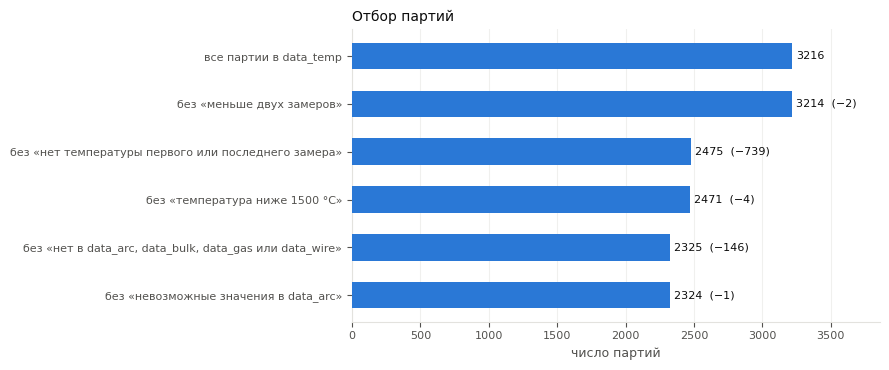

В анализе 2324 партий (key 1–2499), исключено 892.


In [9]:
REQUIRED_SOURCES = ['data_arc', 'data_bulk', 'data_gas', 'data_wire']
keys_by_source = {t: set(raw[t]['key']) for t in INDUSTRIAL_TABLES}

rules = [
    ('меньше двух замеров', stats['n_measurements'] < 2),
    ('нет температуры первого или последнего замера', stats['T_first'].isna() | stats['T_last'].isna()),
    (f'температура ниже {MIN_TEMPERATURE} °C', (stats['T_first'] < MIN_TEMPERATURE) | (stats['T_last'] < MIN_TEMPERATURE)),
    ('нет в data_arc, data_bulk, data_gas или data_wire',
     ~pd.Series(stats.index, index=stats.index).map(lambda k: all(k in keys_by_source[t] for t in REQUIRED_SOURCES))),
    ('невозможные значения в data_arc', stats.index.isin(ARC_ANOMALY_KEYS)),
]
reason = pd.Series('в анализе', index=stats.index)
for label, mask in reversed(rules):  # причина исключения — первое сработавшее правило
    reason = reason.mask(mask, label)

funnel_labels, funnel_counts = ['все партии в data_temp'], [len(stats)]
for label, _ in rules:
    funnel_labels.append(f'без «{label}»')
    funnel_counts.append(funnel_counts[-1] - int((reason == label).sum()))

fig, ax = plt.subplots(figsize=(9, 3.8), facecolor='white')
y_pos = np.arange(len(funnel_counts))[::-1]
ax.barh(y_pos, funnel_counts, height=0.55, color=BAR_COLOR, zorder=3)
ax.set_yticks(y_pos)
ax.set_yticklabels(funnel_labels, color=INK, fontsize=8)
for y, count, previous in zip(y_pos, funnel_counts, [None] + funnel_counts[:-1]):
    ax.text(count + 30, y, f'{count}' + ('' if previous is None else f'  (−{previous - count})'), va='center', color=INK, fontsize=8)
ax.set_xlim(0, max(funnel_counts) * 1.2)
style_axes(ax, 'Отбор партий', 'число партий', grid_axis='x')
save_figure(fig, 'batch_selection.png')

batches = stats.loc[reason == 'в анализе'].sort_index()
print(f'В анализе {len(batches)} партий (key {batches.index.min()}–{batches.index.max()}), исключено {int((reason != "в анализе").sum())}.')

**Выводы.** Из 3 216 партий в анализе остаются 2 324 (`key` от 1 до 2499). Основная потеря — 739 партий (`key` от 2500), у которых температура заполнена только в первом замере, то есть конечная температура не записана. Ещё исключены 2 партии с одним замером, 4 партии с первым замером ниже 1500 °C (1191–1227 °C, вероятно ошибки датчика), 146 партий, отсутствующих в одной из таблиц операций, и партия 2116 с отрицательной реактивной мощностью (−715.5 при следующем минимальном значении 0.154). Аномальное значение не заменялось: обоснованной оценки истинной величины по данным нет. Модель, таким образом, описывает партии с завершённым циклом измерений.

## 4. Разбиение на обучающую и тестовую выборки

Выборка делится по времени первого замера: первые 75% партий — обучающая выборка (train), последние 25% — тестовая (test). При случайном разбиении в test попали бы партии, соседние по времени с обучающими и произведённые в сходных условиях, и оценка качества на будущих партиях могла бы оказаться оптимистичной. Разбиение не содержит случайного компонента. Список ключей сохраняется в `data/split_keys.csv`.

In [10]:
n_test = int(np.ceil(TEST_SIZE * len(batches)))
by_time = batches.sort_values('first_time', kind='stable').index
train_keys, test_keys = np.sort(by_time[:-n_test].to_numpy()), np.sort(by_time[-n_test:].to_numpy())
split_keys = pd.concat([pd.DataFrame({'key': train_keys, 'split': 'train'}),
                        pd.DataFrame({'key': test_keys, 'split': 'test'})]).sort_values('key').reset_index(drop=True)
split_keys.to_csv(DATA_DIR / 'split_keys.csv', index=False)

period = (batches[['first_time', 'last_time']].join(split_keys.set_index('key')['split'])
          .groupby('split').agg(партий=('first_time', 'size'), начало=('first_time', 'min'), конец=('last_time', 'max'))
          .loc[['train', 'test']])
period['key'] = [f'{train_keys.min()}–{train_keys.max()}', f'{test_keys.min()}–{test_keys.max()}']
display(period)
gap = batches.loc[test_keys, 'first_time'].min() - batches.loc[train_keys, 'last_time'].max()
print(f'Последняя партия train завершилась за {gap} до начала первой партии test.')

batches_train = batches.loc[train_keys]
t_first, t_last = batches_train['T_first'], batches_train['T_last']

,партий,начало,конец,key
split,,,,
train,1743,2019-05-03 11:02:04,2019-07-11 17:44:20,1–1867
test,581,2019-07-11 17:57:02,2019-08-10 13:58:58,1868–2499


Последняя партия train завершилась за 0 days 00:12:42 до начала первой партии test.


Обучающая выборка — 1 743 партии с 3 мая по 11 июля 2019 года, тестовая — 581 партия с 11 июля по 10 августа. Дальнейший анализ, отбор признаков и выбор модели выполняются только на train; test используется один раз в разделе 9.

## 5. Исследовательский анализ таблиц

Анализ выполняется на партиях train. Нетипичное значение считается **ошибкой**, если оно физически невозможно или противоречит описанию процесса (такие записи исключаются), и **выбросом**, если оно допустимо, но редко (выбросы сохраняются, подраздел 5.6). Пропуск в таблицах материалов означает, что материал не добавлялся.

In [11]:
tables = {name: raw[name][raw[name]['key'].isin(train_keys)].copy() for name in INDUSTRIAL_TABLES}
display(pd.DataFrame({
    'строк': {n: len(t) for n, t in tables.items()},
    'партий': {n: t['key'].nunique() for n, t in tables.items()},
    'дублей строк': {n: int(t.duplicated().sum()) for n, t in tables.items()},
    'пустых ячеек, %': {n: round(100 * t.drop(columns='key').isna().mean().mean(), 1) for n, t in tables.items()},
}))

,строк,партий,дублей строк,"пустых ячеек, %"
data_arc,8183,1743,0,0.0
data_bulk,1743,1743,0,76.3
data_bulk_time,1743,1743,0,76.3
data_gas,1743,1743,0,0.0
data_temp,9926,1743,0,0.0
data_wire,1743,1743,0,84.7
data_wire_time,1743,1743,0,84.7


### 5.1. Нагревы электродами (`data_arc`)

,count,mean,std,min,25%,50%,75%,max
ActivePower,8183.0,0.666,0.259,0.228,0.469,0.602,0.833,1.464
ReactivePower,8183.0,0.490,0.198,0.154,0.340,0.444,0.612,1.270
duration,8183.0,171.248,96.879,11.000,106.000,146.000,216.000,907.000


Нагревов 8183: от 1 до 15 на партию, медиана 5; пересечений нагревов внутри партии: 0; отношение активной мощности к реактивной: 1.00–1.77; пауза между нагревами: медиана 205 с, максимум 14528 с.


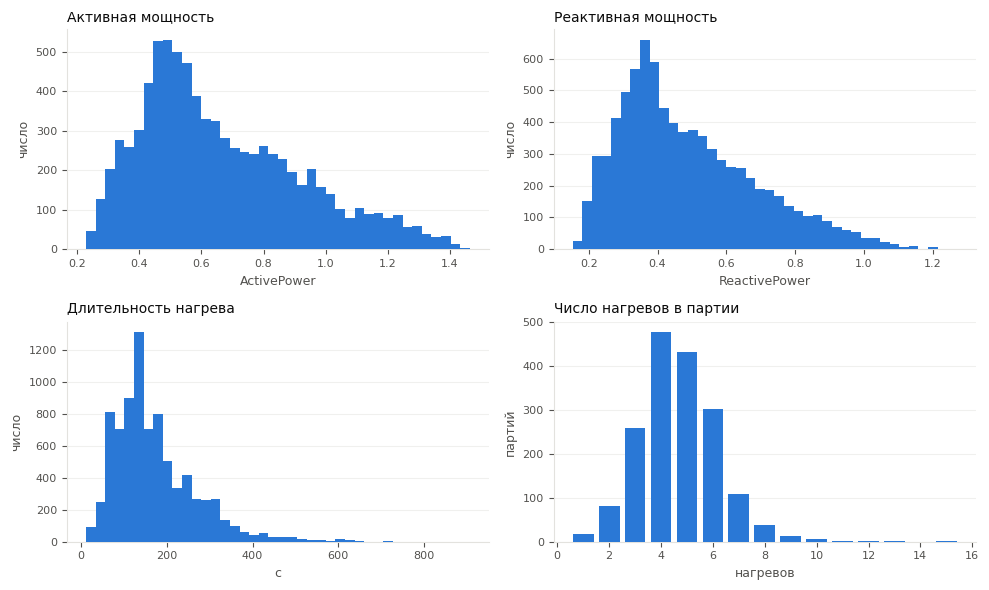

In [12]:
arc = tables['data_arc'].sort_values(['key', 'BeginHeat']).assign(
    duration=lambda d: (d['EndHeat'] - d['BeginHeat']).dt.total_seconds())
heats = arc.groupby('key').size()
pause = (arc['BeginHeat'] - arc.groupby('key')['EndHeat'].shift()).dt.total_seconds()
display(arc[['ActivePower', 'ReactivePower', 'duration']].describe().round(3).T)
print(f'Нагревов {len(arc)}: от {heats.min()} до {heats.max()} на партию, медиана {heats.median():.0f}; '
      f'пересечений нагревов внутри партии: {int((pause < 0).sum())}; '
      f'отношение активной мощности к реактивной: {(arc["ActivePower"] / arc["ReactivePower"]).min():.2f}–'
      f'{(arc["ActivePower"] / arc["ReactivePower"]).max():.2f}; пауза между нагревами: медиана {pause.median():.0f} с, '
      f'максимум {pause.max():.0f} с.')

fig, axes = plt.subplots(2, 2, figsize=(10, 6), facecolor='white')
hist_panel(axes[0, 0], arc['ActivePower'], 'Активная мощность', 'ActivePower')
hist_panel(axes[0, 1], arc['ReactivePower'], 'Реактивная мощность', 'ReactivePower')
hist_panel(axes[1, 0], arc['duration'], 'Длительность нагрева', 'с')
counts = heats.value_counts().sort_index()
axes[1, 1].bar(counts.index, counts.values, color=BAR_COLOR, zorder=3)
style_axes(axes[1, 1], 'Число нагревов в партии', 'нагревов', 'партий')
save_figure(fig, 'eda_arc.png')

### 5.2. Сыпучие и проволочные материалы (`data_bulk`, `data_wire` и таблицы времени подачи)

Для каждого материала показаны доля партий, где его добавляли, и распределение объёма там, где добавляли. Таблицы времени проверяются на совпадение пропусков с таблицами объёмов и на правдоподобие: подача материалов в партии не должна превышать сутки.

Сыпучие: пропуски объёмов и времени совпадают: True; объёмов <= 0: 0; видов в партии: 1–7; время от первой до последней подачи в партии: медиана 15 мин, максимум 1.6 ч.


,Bulk_1,Bulk_2,Bulk_3,Bulk_4,Bulk_5,Bulk_6,Bulk_7,Bulk_8,Bulk_9,Bulk_10,Bulk_11,Bulk_12,Bulk_13,Bulk_14,Bulk_15
партий,169.000,6.000,727.000,606.000,36.000,289.000,4.000,1.000,11.000,97.000,64.000,1357.000,12.000,1546.000,1265.000
доля партий,0.097,0.003,0.417,0.348,0.021,0.166,0.002,0.001,0.006,0.056,0.037,0.779,0.007,0.887,0.726
медиана,31.000,240.000,98.000,104.000,73.500,106.000,166.500,49.000,66.000,79.000,82.500,207.000,154.500,154.000,201.000
p99,92.600,321.600,352.700,254.400,458.100,328.000,399.200,49.000,139.400,126.800,268.300,616.900,302.000,373.200,224.000
максимум,185.000,325.000,454.000,281.000,603.000,503.000,406.000,49.000,147.000,147.000,313.000,1849.000,305.000,636.000,405.000


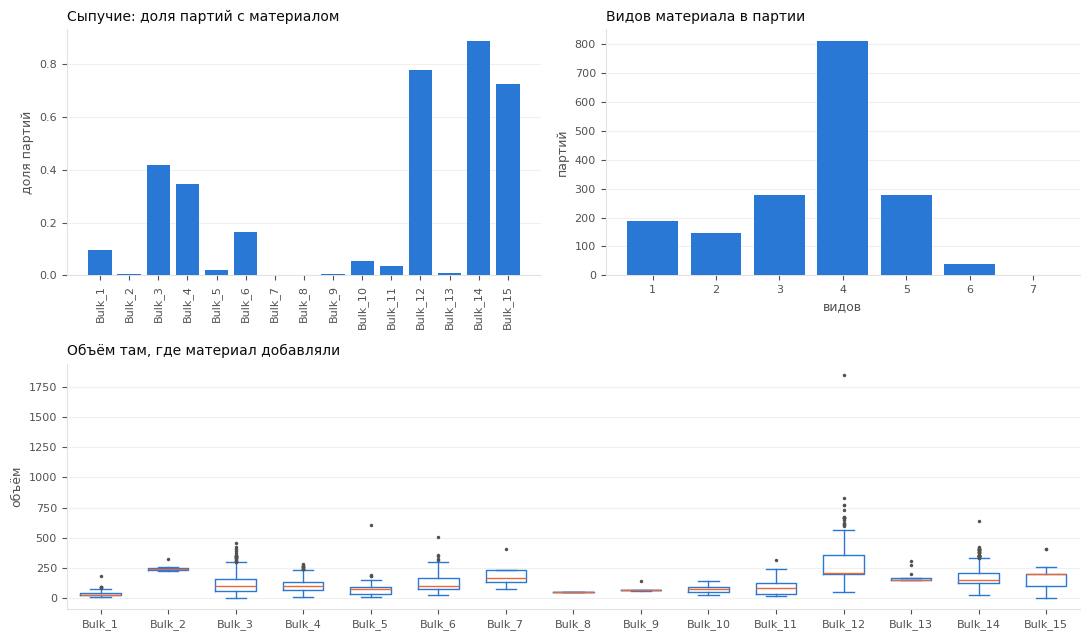

Проволока: пропуски объёмов и времени совпадают: True; объёмов <= 0: 0; видов в партии: 1–4; время от первой до последней подачи в партии: медиана 0 мин, максимум 1.0 ч.


,Wire_1,Wire_2,Wire_3,Wire_4,Wire_5,Wire_6,Wire_7,Wire_8,Wire_9
партий,1725.00,587.000,25.000,3.000,0.0,25.000,0.0,11.000,18.00
доля партий,0.99,0.337,0.014,0.002,0.0,0.014,0.0,0.006,0.01
медиана,103.20,43.400,244.500,33.200,NaN,39.200,NaN,46.100,30.10
p99,220.90,189.200,287.600,42.900,NaN,127.800,NaN,66.300,60.80
максимум,330.30,282.800,288.400,43.100,NaN,137.100,NaN,68.500,62.00


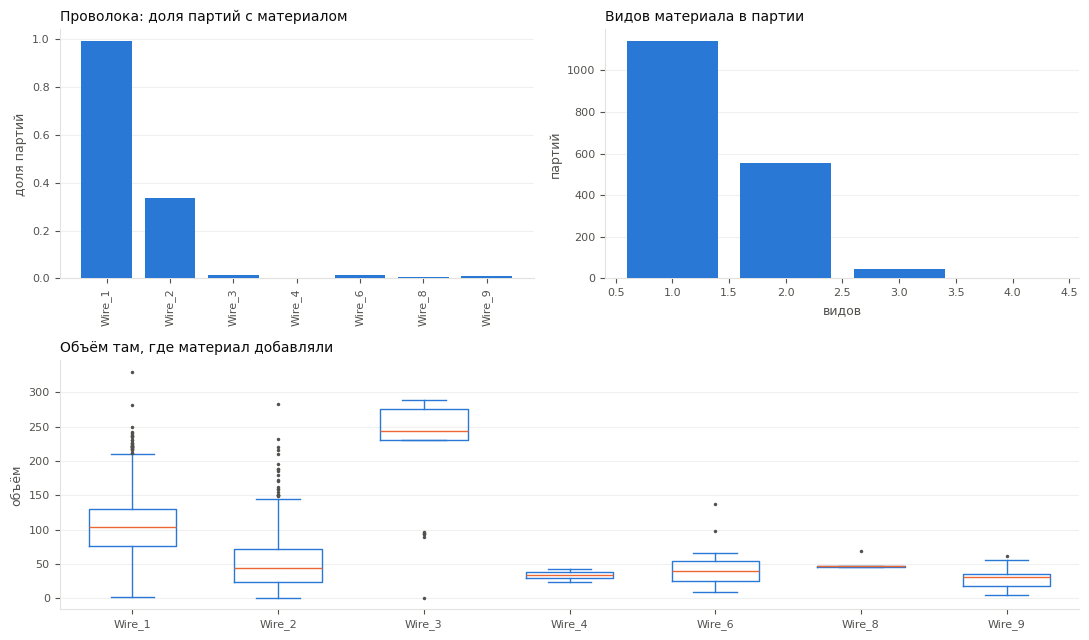

In [13]:
def material_summary(volumes):
    return pd.DataFrame({'партий': volumes.notna().sum(), 'доля партий': volumes.notna().mean().round(3),
                         'медиана': volumes.median().round(1), 'p99': volumes.quantile(0.99).round(1),
                         'максимум': volumes.max().round(1)})


def material_figure(volumes, title, name):
    present = volumes.notna()
    used = [c for c in volumes.columns if present[c].any()]
    fig = plt.figure(figsize=(11, 6.5), facecolor='white')
    grid = fig.add_gridspec(2, 2)
    ax_share, ax_kinds, ax_box = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1]), fig.add_subplot(grid[1, :])
    ax_share.bar(used, present.mean()[used], color=BAR_COLOR, zorder=3)
    ax_share.tick_params(axis='x', rotation=90)
    style_axes(ax_share, f'{title}: доля партий с материалом', ylabel='доля партий')
    kinds = present.sum(axis=1).value_counts().sort_index()
    ax_kinds.bar(kinds.index, kinds.values, color=BAR_COLOR, zorder=3)
    style_axes(ax_kinds, 'Видов материала в партии', 'видов', 'партий')
    ax_box.boxplot([volumes[c].dropna() for c in used], widths=0.6, medianprops={'color': ACCENT},
                   boxprops={'color': BAR_COLOR}, whiskerprops={'color': BAR_COLOR}, capprops={'color': BAR_COLOR},
                   flierprops={'marker': 'o', 'markersize': 2.5, 'markeredgecolor': 'none', 'markerfacecolor': INK_SECONDARY})
    ax_box.set_xticks(range(1, len(used) + 1))
    ax_box.set_xticklabels(used)
    style_axes(ax_box, 'Объём там, где материал добавляли', ylabel='объём')
    save_figure(fig, name)


materials = {}
for kind, label in [('bulk', 'Сыпучие'), ('wire', 'Проволока')]:
    volumes = tables[f'data_{kind}'].set_index('key')
    times = tables[f'data_{kind}_time'].set_index('key')
    span_hours = (times.max(axis=1) - times.min(axis=1)).dt.total_seconds() / 3600
    materials[kind] = volumes
    print(f'{label}: пропуски объёмов и времени совпадают: {bool((volumes.notna() == times.notna()).all().all())}; '
          f'объёмов <= 0: {int((volumes <= 0).sum().sum())}; видов в партии: {volumes.notna().sum(axis=1).min()}–'
          f'{volumes.notna().sum(axis=1).max()}; время от первой до последней подачи в партии: медиана '
          f'{span_hours.median() * 60:.0f} мин, максимум {span_hours.max():.1f} ч.')
    display(material_summary(volumes).T)
    material_figure(volumes, label, f'eda_{kind}.png')
bulk, wire = materials['bulk'], materials['wire']
bulk_time, wire_time = tables['data_bulk_time'].set_index('key'), tables['data_wire_time'].set_index('key')

### 5.3. Продувка газом (`data_gas`)

,count,mean,std,min,25%,50%,75%,max
gas,1743.0,11.27,6.42,0.01,7.22,10.0,13.92,78.0


Коэффициент асимметрии 2.12; значений меньше 1: 3; больше 40: 5.


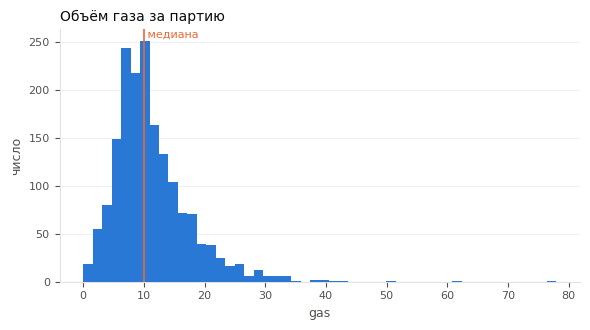

In [14]:
gas = tables['data_gas'].set_index('key')['gas']
display(gas.describe().round(2).to_frame().T)
print(f'Коэффициент асимметрии {gas.skew():.2f}; значений меньше 1: {int((gas < 1).sum())}; больше 40: {int((gas > 40).sum())}.')
fig, ax = plt.subplots(figsize=(6, 3.4), facecolor='white')
hist_panel(ax, gas, 'Объём газа за партию', 'gas', bins=50, marks=[(gas.median(), 'медиана')])
save_figure(fig, 'eda_gas.png')

### 5.4. Температура (`data_temp`)

,count,mean,std,min,25%,50%,75%,max
T_first,1743.0,1587.4,22.7,1519.0,1572.0,1587.0,1602.5,1660.0
T_last,1743.0,1593.9,11.0,1547.0,1588.0,1593.0,1599.0,1653.0
T_last − T_first,1743.0,6.6,21.9,-88.0,-8.0,7.0,21.0,83.0
замеров в партии,1743.0,5.7,1.6,2.0,5.0,6.0,7.0,16.0


Корреляция T_first и T_last: 0.31; партий, остывших к последнему замеру: 644 (36.9%); партий с T_last 1610–1625 °C: 9.4%.


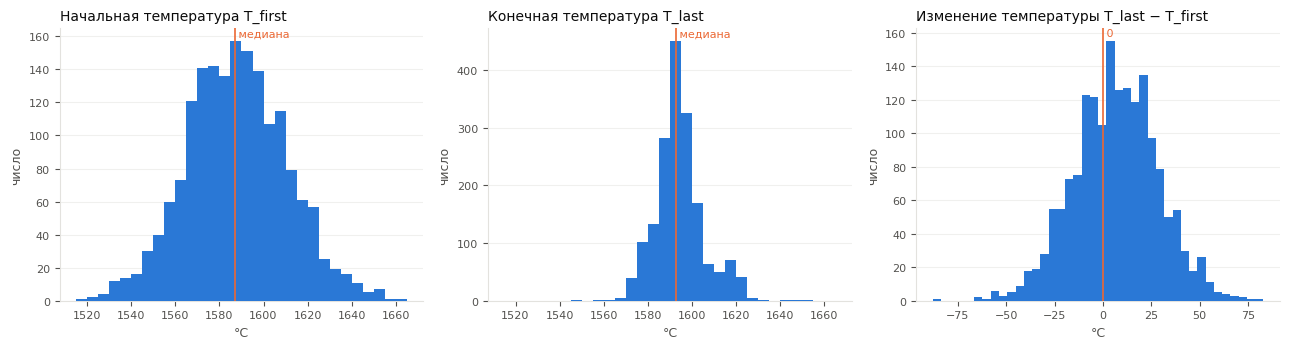

In [15]:
delta = t_last - t_first
display(pd.DataFrame({'T_first': t_first, 'T_last': t_last, 'T_last − T_first': delta,
                      'замеров в партии': batches_train['n_measurements']}).describe().round(1).T)
print(f'Корреляция T_first и T_last: {t_first.corr(t_last):.2f}; партий, остывших к последнему замеру: '
      f'{int((delta < 0).sum())} ({(delta < 0).mean():.1%}); партий с T_last 1610–1625 °C: {t_last.between(1610, 1625).mean():.1%}.')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), facecolor='white')
temperature_bins = np.arange(1515, 1670, 5)
hist_panel(axes[0], t_first, 'Начальная температура T_first', '°C', bins=temperature_bins, marks=[(t_first.median(), 'медиана')])
hist_panel(axes[1], t_last, 'Конечная температура T_last', '°C', bins=temperature_bins, marks=[(t_last.median(), 'медиана')])
hist_panel(axes[2], delta, 'Изменение температуры T_last − T_first', '°C', marks=[(0, '0')])
save_figure(fig, 'eda_temp.png')

### 5.5. Согласованность времени между таблицами

Ожидаемый порядок событий партии: первый замер → нагревы с паузами → подачи материалов → последний замер. Заказчик предупредил, что часы разных датчиков бывают рассинхронизированы; расхождения с этим порядком не считаются ошибкой, но определяют, насколько надёжны интервалы между событиями разных таблиц как признаки. Проверяется также запас времени от последней операции до контрольного замера: признаки должны описывать только события, предшествующие замеру. Время продувки газом не записано; то, что она завершена до последнего замера, — допущение.

,раньше первого замера,позже последнего замера,раньше начала первого нагрева
число партий,,,
подачи сыпучих,0,0,0
подачи проволоки,0,0,0
нагревы,0,0,<NA>


Задержка первого нагрева после первого замера: 10 с во всех партиях.
Последняя подача сыпучих позже окончания последнего нагрева в 1728 партиях (не более чем на 20 с), раньше — в 15; последняя подача проволоки позже окончания нагревов — в 50 партиях.
От последней операции до контрольного замера: медиана 243 с, минимум 4 с, максимум 6953 с; партий, где последняя операция не раньше замера: 0.


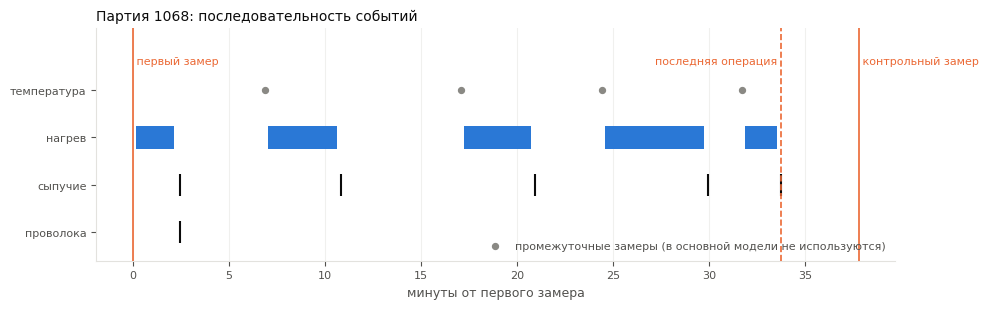

In [16]:
window = batches_train[['first_time', 'last_time']]
heat_span = arc.groupby('key').agg(first_heat=('BeginHeat', 'min'), last_heat_end=('EndHeat', 'max'))
order_checks = {}
for name, times in [('подачи сыпучих', bulk_time), ('подачи проволоки', wire_time)]:
    order_checks[name] = {'раньше первого замера': int((times.min(axis=1) < window['first_time']).sum()),
                          'позже последнего замера': int((times.max(axis=1) > window['last_time']).sum()),
                          'раньше начала первого нагрева': int((times.min(axis=1) < heat_span['first_heat']).sum())}
order_checks['нагревы'] = {'раньше первого замера': int((heat_span['first_heat'] < window['first_time']).sum()),
                           'позже последнего замера': int((heat_span['last_heat_end'] > window['last_time']).sum())}
display(pd.DataFrame(order_checks).T.astype('Int64').rename_axis('число партий'))

lag = (heat_span['first_heat'] - window['first_time']).dt.total_seconds()
last_bulk_lag = (bulk_time.max(axis=1) - heat_span['last_heat_end']).dt.total_seconds()
last_wire_lag = (wire_time.max(axis=1) - heat_span['last_heat_end']).dt.total_seconds()
print(f'Задержка первого нагрева после первого замера: {", ".join(f"{v:.0f}" for v in sorted(lag.unique()))} с во всех партиях.')
print(f'Последняя подача сыпучих позже окончания последнего нагрева в {int((last_bulk_lag > 0).sum())} партиях '
      f'(не более чем на {last_bulk_lag.max():.0f} с), раньше — в {int((last_bulk_lag < 0).sum())}; '
      f'последняя подача проволоки позже окончания нагревов — в {int((last_wire_lag > 0).sum())} партиях.')
last_operation = pd.concat([heat_span['last_heat_end'], bulk_time.max(axis=1), wire_time.max(axis=1)], axis=1).max(axis=1)
margin = (window['last_time'] - last_operation.reindex(window.index)).dt.total_seconds()
print(f'От последней операции до контрольного замера: медиана {margin.median():.0f} с, минимум {margin.min():.0f} с, '
      f'максимум {margin.max():.0f} с; партий, где последняя операция не раньше замера: {int((margin <= 0).sum())}.')

example = (margin[heats == heats.median()] - margin.median()).abs().idxmin()
start = batches.loc[example, 'first_time']
minutes = lambda t: (t - start).total_seconds() / 60
ex_heats = raw['data_arc'][raw['data_arc']['key'] == example]
ex_adds = {name: raw[t].set_index('key').loc[example].dropna() for name, t in [('сыпучие', 'data_bulk_time'), ('проволока', 'data_wire_time')]}
ex_temps = raw['data_temp'][raw['data_temp']['key'] == example].sort_values('MeasureTime')

fig, ax = plt.subplots(figsize=(10, 3.2), facecolor='white')
for _, row in ex_heats.iterrows():
    ax.barh(2, minutes(row['EndHeat']) - minutes(row['BeginHeat']), left=minutes(row['BeginHeat']), height=0.5, color=BAR_COLOR, zorder=3)
for y, times in zip([1, 0], ex_adds.values()):
    ax.scatter([minutes(t) for t in times], [y] * len(times), marker='|', s=250, color=INK, zorder=3)
inner = ex_temps.iloc[1:-1]
ax.scatter([minutes(t) for t in inner['MeasureTime']], [3] * len(inner), s=18, color=NEUTRAL, zorder=3,
           label='промежуточные замеры (в основной модели не используются)')
for moment, label, style, align in [(start, ' первый замер', '-', 'left'), (last_operation[example], 'последняя операция ', '--', 'right'),
                                    (batches.loc[example, 'last_time'], ' контрольный замер', '-', 'left')]:
    ax.axvline(minutes(moment), color=ACCENT, linestyle=style, linewidth=1.2, zorder=4)
    ax.text(minutes(moment), 3.5, label, color=ACCENT, fontsize=8, ha=align, va='bottom')
ax.set_yticks([0, 1, 2, 3])
ax.set_yticklabels(['проволока', 'сыпучие', 'нагрев', 'температура'], color=INK, fontsize=9)
ax.set_ylim(-0.6, 4.3)
ax.legend(frameon=False, fontsize=8, labelcolor=INK_SECONDARY, loc='lower right')
style_axes(ax, f'Партия {example}: последовательность событий', 'минуты от первого замера', grid_axis='x')
save_figure(fig, 'batch_timeline.png')

### 5.6. Выбросы

Выбросом считается значение за границами Тьюки с множителем k = 3 («далёкий выброс»): выше Q3 + 3·IQR или ниже max(Q1 − 3·IQR, 0), где IQR — межквартильный размах. Множитель 3 вместо обычного 1.5 выбран потому, что распределения скошены вправо и при k = 1.5 границу пересекает естественный хвост. Материалы, которые добавлялись менее чем в 5% партий, в таблицу не включены: для них квартили ненадёжны.

In [17]:
OUTLIER_K = 3
OUTLIER_MIN_SHARE = 0.05


def tukey_bounds(values, k=OUTLIER_K):
    q1, q3 = values.quantile([0.25, 0.75])
    return max(q1 - k * (q3 - q1), 0), q3 + k * (q3 - q1)


frequent = [c for c in bulk.columns if bulk[c].notna().mean() >= OUTLIER_MIN_SHARE] + \
           [c for c in wire.columns if wire[c].notna().mean() >= OUTLIER_MIN_SHARE]
batch_values = {'gas': gas, **{c: (bulk[c] if c in bulk else wire[c]).dropna() for c in frequent}}
columns = {'ActivePower': arc['ActivePower'], 'ReactivePower': arc['ReactivePower'], 'длительность нагрева, с': arc['duration'],
           'пауза между нагревами, с': pause.dropna(), 'нагревов в партии': heats.astype(float),
           **batch_values, 'T_first': t_first, 'T_last': t_last}
rows = {}
for name, values in columns.items():
    low_bound, high_bound = tukey_bounds(values)
    outliers = (values < low_bound) | (values > high_bound)
    rows[name] = {'медиана': values.median(), 'максимум': values.max(), 'верхняя граница': high_bound,
                  'выбросов': int(outliers.sum()), 'выбросов, %': 100 * outliers.mean()}
display(pd.DataFrame(rows).T.astype({'выбросов': int}).round(2))

holders = pd.Series({name: values.idxmax() for name, values in batch_values.items()})
print(f'Партия {holders.value_counts().index[0]} — максимум сразу по {holders.value_counts().iloc[0]} признакам: '
      f'{list(holders.index[holders == holders.value_counts().index[0]])}.')

,медиана,максимум,верхняя граница,выбросов,"выбросов, %"
ActivePower,0.60,1.46,1.92,0,0.00
ReactivePower,0.44,1.27,1.43,0,0.00
"длительность нагрева, с",146.00,907.00,546.00,49,0.60
"пауза между нагревами, с",205.00,14528.00,1054.00,202,3.14
нагревов в партии,5.00,15.00,12.00,4,0.23
gas,10.00,78.00,34.01,11,0.63
Bulk_1,31.00,185.00,111.00,1,0.59
Bulk_3,98.00,454.00,448.00,1,0.14
Bulk_4,104.00,281.00,339.00,0,0.00
Bulk_6,106.00,503.00,435.00,1,0.35


Партия 322 — максимум сразу по 4 признакам: ['gas', 'Bulk_1', 'Bulk_12', 'Bulk_14'].


Редкие значения сохранены: признаков ошибки записи у них не выявлено, а удаление крупных партий сузило бы область применимости модели. Предобработка признаков определяется моделью и выполняется внутри обучающей части каждого фолда (раздел 8). Целевая переменная не обрезается; метрика MAE сама по себе менее чувствительна к крупным ошибкам, чем квадратичная.

### 5.7. Целевая переменная во времени и схема кросс-валидации

Поскольку test следует за train по времени, кросс-валидация внутри train организована так же: `TimeSeriesSplit` с расширяющимся окном, где каждый фолд обучается на партиях, предшествующих проверочному блоку. Эта схема используется во всех сравнениях моделей.

,в обучении,в проверке,проверка с,по,среднее T_last,MAE константы-медианы
фолд,,,,,,
1,293,290,2019-05-16,2019-05-27,1594.36,7.03
2,583,290,2019-05-27,2019-06-09,1595.38,7.96
3,873,290,2019-06-09,2019-06-19,1593.37,8.0
4,1163,290,2019-06-19,2019-07-01,1593.83,8.14
5,1453,290,2019-07-01,2019-07-11,1592.38,8.25


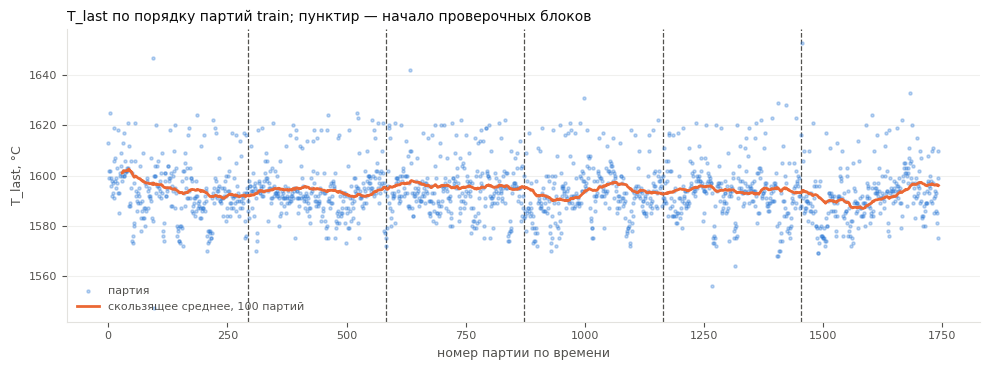

In [18]:
cv = TimeSeriesSplit(n_splits=N_FOLDS)
folds = pd.DataFrame({k: {'в обучении': len(fit), 'в проверке': len(valid),
                          'проверка с': batches_train['first_time'].iloc[valid].min().date(),
                          'по': batches_train['first_time'].iloc[valid].max().date(),
                          'среднее T_last': round(t_last.iloc[valid].mean(), 2),
                          'MAE константы-медианы': round((t_last.iloc[valid] - t_last.iloc[fit].median()).abs().mean(), 2)}
                      for k, (fit, valid) in enumerate(cv.split(batches_train), start=1)}).T.rename_axis('фолд')
display(folds)

fig, ax = plt.subplots(figsize=(10, 3.8), facecolor='white')
ax.scatter(np.arange(len(t_last)), t_last, s=5, alpha=0.3, color=BAR_COLOR, zorder=3, label='партия')
ax.plot(np.arange(len(t_last)), t_last.rolling(100, min_periods=30).mean().to_numpy(), color=ACCENT, linewidth=2,
        zorder=4, label='скользящее среднее, 100 партий')
for _, valid in cv.split(batches_train):
    ax.axvline(valid[0], color=INK_SECONDARY, linestyle='--', linewidth=0.9, zorder=2)
ax.legend(frameon=False, fontsize=8, labelcolor=INK_SECONDARY, loc='lower left')
style_axes(ax, 'T_last по порядку партий train; пунктир — начало проверочных блоков', 'номер партии по времени', 'T_last, °C')
save_figure(fig, 'eda_target_over_time.png')

### Выводы по исследовательскому анализу

- **Полнота.** Все 1 743 партии train есть во всех таблицах, дублей строк нет; пропуски есть только в таблицах материалов и означают отсутствие добавки (пропуски объёмов и моментов подачи совпадают).
- **Нагревы.** 8 183 нагрева, от 1 до 15 на партию (медиана 5); нарушений проверенных условий не выявлено: мощности положительны, нагревы не пересекаются, активная мощность не меньше реактивной (отношение 1.00–1.77). Распределения мощности и длительности скошены вправо. Паузы между нагревами обычно 2–4 минуты, но 3.1% пауз длиннее 17.5 минуты (до 4 часов) — вероятно, технологические простои.
- **Материалы.** Основу составляют `Bulk_14` (89% партий), `Bulk_12` (78%), `Bulk_15` (73%) и `Wire_1` (99%); пять видов сыпучих и четыре вида проволоки добавлялись менее чем в 1% партий, а `Wire_5` и `Wire_7` в train не встречаются. Подачи сыпучих материалов в партии укладываются в 15 минут по медиане (максимум 1.6 ч), проволоки — не более чем в 1 ч: значений, измеряемых сутками, нет.
- **Газ.** Медиана 10.0, распределение скошено вправо (коэффициент асимметрии 2.1), максимум 78; малые значения (менее 1) встречаются у трёх партий; оснований считать их ошибкой не обнаружено.
- **Температура.** `T_last` в среднем 1593.9 °C со стандартным отклонением 11.0 °C — вдвое меньше, чем у `T_first` (22.7 °C): обработка сводит партии к узкому целевому диапазону. Корреляция `T_first` и `T_last` слабая (0.31), 37% партий к последнему замеру остывают. В распределении `T_last` есть второй пик в диапазоне 1610–1625 °C (около 9% партий), причину которого (режим, марка стали) имеющиеся данные не раскрывают.
- **Хронология.** Все нагревы и подачи лежат между первым и последним замером; первый нагрев во всех партиях начинается ровно через 10 с после первого замера, то есть `T_first` — температура до нагрева. Последняя подача сыпучих почти всегда регистрируется в пределах 20 с после окончания последнего нагрева, что указывает на привязку отметки к окончанию нагрева; интервалы между событиями разных журналов поэтому надёжны лишь приблизительно. Последняя операция предшествует контрольному замеру не менее чем на 4 с (медиана 243 с). Это согласованность записей, а не доказательство порядка событий, поскольку часы датчиков могут расходиться.
- **Выбросы.** Значений, нарушающих проверенные ограничения, в train не выявлено. Доля выбросов не превышает 1% значений, кроме пауз между нагревами (3.1%). Партия 322 — максимум сразу по четырём признакам (газ, `Bulk_1`, `Bulk_12`, `Bulk_14`); значения согласованы между собой и соответствуют интенсивной обработке, оснований для удаления не обнаружено.
- **Стабильность во времени.** Средняя `T_last` по проверочным блокам меняется в пределах 1592.4–1595.4 °C, выраженного тренда нет. MAE константной модели по фолдам — 7.0–8.3 °C, ориентир относительно требования 6.8.

## 6. Признаки

**Технологический процесс.** Сталь обрабатывается в ковше циклами: замер температуры и химический анализ → нагрев графитовыми электродами → добавка легирующих материалов (сыпучих из бункера или проволоки) → продувка инертным газом для перемешивания → снова замер. Цикл повторяется, пока не достигнуты нужный состав и температура. Приращение температуры определяется тепловым балансом: подведённой энергией нагрева за вычетом потерь и охлаждения добавками, ΔT ≈ (η·E − потери) / (m·c), где m — масса металла в ковше, c — теплоёмкость, η — коэффициент полезного действия нагрева. Масса плавки и коэффициент полезного действия в данных отсутствуют.

**Момент прогноза.** Модель оценивает температуру контрольного (последнего) замера после завершения всех операций партии и до самого замера. Признаки — характеристики выполненной обработки и `T_first`; момент последнего замера, промежуточные температуры, номер партии и даты не используются. Для прогноза сразу после первого замера, когда режим обработки ещё не выполнен, модель не предназначена: фактические значения признаков пришлось бы заменить плановыми.

**Построение.** Сначала признаки вычисляются для каждого нагрева, затем агрегируются по партии. Признаки не используют целевую переменную и одинаково применяются к train и test. Из материалов исключены только `Wire_5` и `Wire_7`, которые не встречаются в train ни разу. Признаки объединены во вложенные наборы, чтобы оценить вклад каждой группы на кросс-валидации (подраздел 8.1):

| Набор | Признаки | Обоснование |
|---|---|---|
| A (8) | `T_first`; число нагревов `n_heat`, суммарная длительность `dur_sum`, полная энергия `ES_sum`, среднее отношение активной мощности к реактивной `ratio_PQ`; суммарные объёмы сыпучих `bulk_total` и проволоки `wire_total`, объём газа `gas` | базовые характеристики начального состояния и обработки партии |
| B (15) | A + активная энергия `E_sum`, коэффициент мощности, взвешенный по энергии, `cosphi_w`, средняя мощность `P_mean_w`, наибольший нагрев `E_max` и `dur_max`, число видов материалов `bulk_n`, `wire_n` | приращение температуры пропорционально подведённой энергии |
| C (59) | B + объём каждого материала и индикатор его добавления | материалы различаются тепловым эффектом |
| D (65) | C + хронология: сумма пауз `pause_sum`, размах нагревов `arc_span`, коэффициент заполнения `duty`, интервалы от первого нагрева до первой добавки `t_first_add`, между первой и последней добавкой `add_span`, от окончания нагревов до последней добавки `t_last_add_vs_heat_end` | паузы означают остывание; интервалы между журналами нагрева и добавок зависят от синхронности часов |

In [19]:
FEATURE_KEYS = batches.index

arc_rows = raw['data_arc'][raw['data_arc']['key'].isin(FEATURE_KEYS)].sort_values(['key', 'BeginHeat']).reset_index(drop=True)
arc_rows['dur'] = (arc_rows['EndHeat'] - arc_rows['BeginHeat']).dt.total_seconds()
arc_rows['S'] = np.hypot(arc_rows['ActivePower'], arc_rows['ReactivePower'])   # полная мощность
arc_rows['ratio'] = arc_rows['ActivePower'] / arc_rows['ReactivePower']
arc_rows['E'] = arc_rows['ActivePower'] * arc_rows['dur']                       # активная энергия нагрева
arc_rows['ES'] = arc_rows['S'] * arc_rows['dur']                                # полная энергия нагрева
arc_rows['pause'] = (arc_rows['BeginHeat'] - arc_rows.groupby('key')['EndHeat'].shift()).dt.total_seconds()

heat = arc_rows.groupby('key')
heat_start, heat_end = heat['BeginHeat'].min(), heat['EndHeat'].max()
arc_features = pd.DataFrame({
    'n_heat': heat.size(), 'dur_sum': heat['dur'].sum(), 'ES_sum': heat['ES'].sum(), 'ratio_PQ': heat['ratio'].mean(),
    'E_sum': heat['E'].sum(), 'E_max': heat['E'].max(), 'dur_max': heat['dur'].max(),
    'pause_sum': heat['pause'].sum(), 'arc_span': (heat_end - heat_start).dt.total_seconds()})
arc_features['cosphi_w'] = arc_features['E_sum'] / arc_features['ES_sum']        # средний коэффициент мощности, взвешенный по энергии
arc_features['P_mean_w'] = arc_features['E_sum'] / arc_features['dur_sum']       # средняя мощность, взвешенная по длительности
arc_features['duty'] = arc_features['dur_sum'] / arc_features['arc_span']

bulk_all = raw['data_bulk'].set_index('key').reindex(FEATURE_KEYS).fillna(0)
wire_all = raw['data_wire'].set_index('key').reindex(FEATURE_KEYS).fillna(0)
absent = [c for c in list(bulk.columns) + list(wire.columns) if (bulk[c] if c in bulk else wire[c]).notna().sum() == 0]
material_features = pd.concat([volumes.join((volumes > 0).astype(int).add_prefix('was_added_'))
                               for volumes in [bulk_all.drop(columns=absent, errors='ignore'), wire_all.drop(columns=absent, errors='ignore')]],
                              axis=1)

add_times = pd.concat([raw[t].set_index('key').reindex(FEATURE_KEYS) for t in ['data_bulk_time', 'data_wire_time']], axis=1)
first_add, last_add = add_times.min(axis=1), add_times.max(axis=1)

features = batches[['T_first']].join([
    arc_features,
    pd.DataFrame({'bulk_total': bulk_all.sum(axis=1), 'wire_total': wire_all.sum(axis=1),
                  'gas': raw['data_gas'].set_index('key')['gas'].reindex(FEATURE_KEYS),
                  'bulk_n': (bulk_all > 0).sum(axis=1), 'wire_n': (wire_all > 0).sum(axis=1)}),
    pd.DataFrame({'t_first_add': (first_add - heat_start).dt.total_seconds(),
                  'add_span': (last_add - first_add).dt.total_seconds(),
                  't_last_add_vs_heat_end': (last_add - heat_end).dt.total_seconds()}),
    material_features])

SET_A = ['n_heat', 'dur_sum', 'ES_sum', 'ratio_PQ', 'T_first', 'bulk_total', 'wire_total', 'gas']
SET_B = SET_A + ['E_sum', 'cosphi_w', 'P_mean_w', 'E_max', 'dur_max', 'bulk_n', 'wire_n']
MATERIAL_COLUMNS = list(material_features.columns)
SET_C = SET_B + MATERIAL_COLUMNS
CHRONOLOGY_COLUMNS = ['pause_sum', 'arc_span', 'duty', 't_first_add', 'add_span', 't_last_add_vs_heat_end']
SET_D = SET_C + CHRONOLOGY_COLUMNS
FEATURE_SETS = {'A': SET_A, 'B': SET_B, 'C': SET_C, 'D': SET_D}
features = features[SET_D]
features_train = features.loc[train_keys]
print({name: len(cols) for name, cols in FEATURE_SETS.items()}, f'| партий: {len(features)}; пропусков: {int(features.isna().sum().sum())}; '
      f'исключены материалы, отсутствующие в train: {absent}')

{'A': 8, 'B': 15, 'C': 59, 'D': 65} | партий: 2324; пропусков: 0; исключены материалы, отсутствующие в train: ['Wire_5', 'Wire_7']


**Выводы.** Для 2 324 партий построено 65 признаков без пропусков. Все признаки описывают события, зарегистрированные до контрольного замера (подраздел 5.5). Ожидание перед первым нагревом постоянно (10 с) и в признаки не включено. Признак `t_last_add_vs_heat_end` изменяется в узком диапазоне 10–20 с и, вероятно, отражает правило регистрации, а не процесс.

## 7. Объединённая таблица: распределения и корреляции

Объединённая таблица train содержит одну строку на партию: 65 признаков и `T_last`. Ниже показаны распределения 19 признаков, построенных в разделе 6; распределения `T_first` и `gas` приведены в подразделах 5.3–5.4, объёмы и частоты добавления отдельных материалов — в подразделе 5.2. Затем оцениваются связь признаков с целевой переменной и связи между собой. Корреляционный анализ формирует гипотезы и выявляет избыточность; состав признаков выбирается по качеству на кросс-валидации (раздел 8).

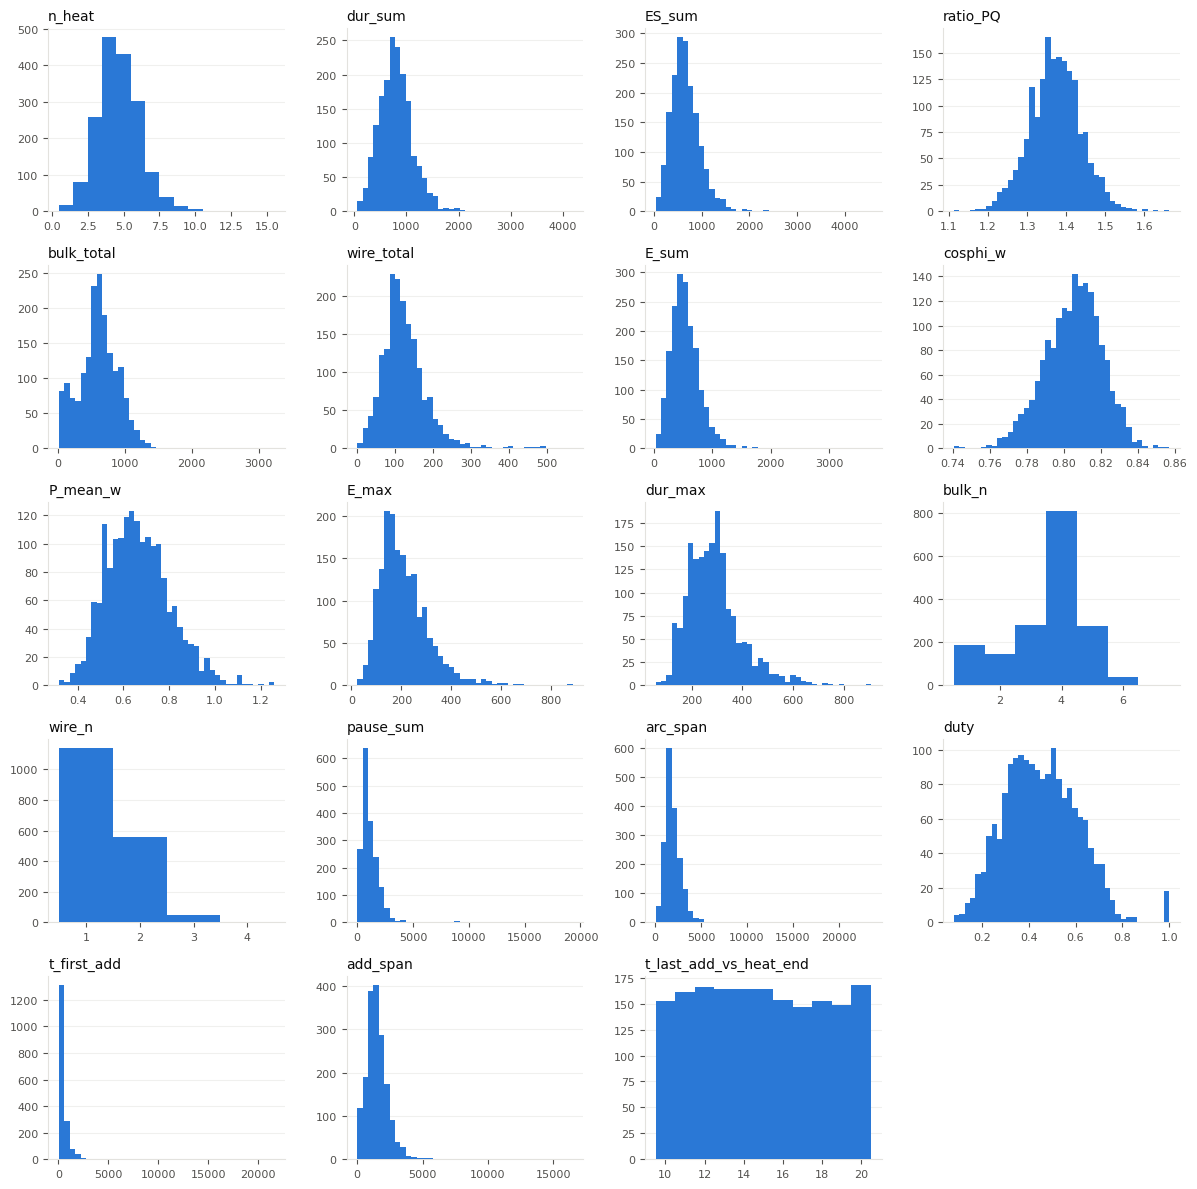

,mean,std,min,50%,max,асимметрия
n_heat,4.69,1.57,1.00,5.00,15.00,0.87
dur_sum,803.97,334.95,57.00,781.00,4189.00,1.37
ES_sum,665.60,317.21,33.43,626.30,4546.41,1.89
ratio_PQ,1.37,0.07,1.11,1.37,1.66,0.06
bulk_total,608.80,291.97,19.00,609.00,3235.00,0.45
wire_total,127.15,64.23,1.92,117.19,568.78,2.09
E_sum,535.79,255.50,26.19,504.75,3718.05,1.94
cosphi_w,0.81,0.02,0.74,0.81,0.86,-0.29
P_mean_w,0.66,0.14,0.32,0.65,1.26,0.50
E_max,210.12,98.24,23.82,191.02,885.34,1.47


In [20]:
merged_train = features_train.join(t_last)
AGG_COLUMNS = [c for c in SET_D if c not in MATERIAL_COLUMNS]
DIST_COLUMNS = [c for c in AGG_COLUMNS if c not in ('T_first', 'gas')]

n_cols = 4
fig, axes = plt.subplots(int(np.ceil(len(DIST_COLUMNS) / n_cols)), n_cols, figsize=(12, 12), facecolor='white')
for ax, name in zip(axes.flat, DIST_COLUMNS):
    values = merged_train[name]
    ax.hist(values, bins=40 if values.nunique() > 20 else np.arange(values.min() - 0.5, values.max() + 1.5), color=BAR_COLOR, zorder=3)
    style_axes(ax, name, ylabel='')
for ax in list(axes.flat)[len(DIST_COLUMNS):]:
    ax.set_visible(False)
save_figure(fig, 'merged_distributions.png')
display(merged_train[DIST_COLUMNS].describe().T.assign(асимметрия=merged_train[DIST_COLUMNS].skew())
        [['mean', 'std', 'min', '50%', 'max', 'асимметрия']].round(2))

### 7.1. Связь признаков с целевой переменной

Коэффициент Пирсона измеряет линейную связь, Спирмена — монотонную по рангам; заметное расхождение между ними указывает на нелинейность или влияние выбросов.

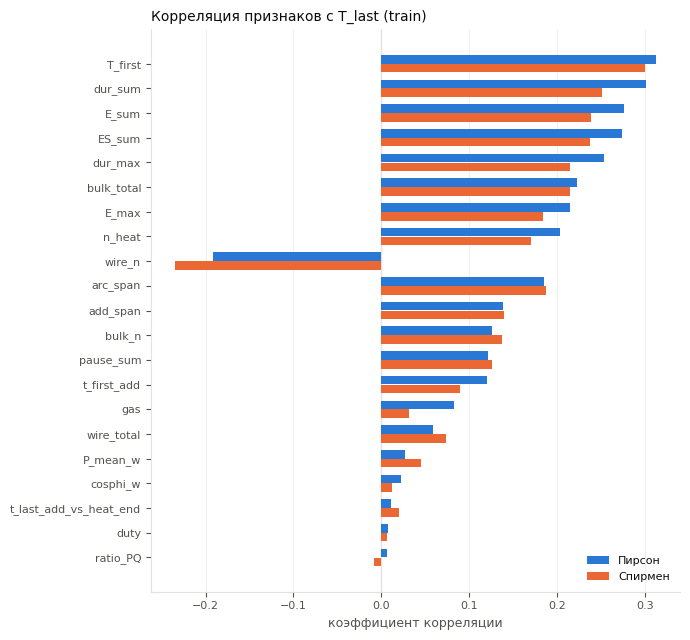

In [21]:
corr_table = pd.DataFrame({'Пирсон': merged_train[AGG_COLUMNS].corrwith(merged_train['T_last']),
                           'Спирмен': merged_train[AGG_COLUMNS].corrwith(merged_train['T_last'], method='spearman')})
corr_table = corr_table.reindex(corr_table['Пирсон'].abs().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(7, 6.5), facecolor='white')
y_pos = np.arange(len(corr_table))[::-1]
ax.barh(y_pos + 0.18, corr_table['Пирсон'], height=0.35, color=BAR_COLOR, label='Пирсон', zorder=3)
ax.barh(y_pos - 0.18, corr_table['Спирмен'], height=0.35, color=ACCENT, label='Спирмен', zorder=3)
ax.set_yticks(y_pos)
ax.set_yticklabels(corr_table.index, fontsize=8)
ax.axvline(0, color=GRID, linewidth=1)
ax.legend(fontsize=8, frameon=False, labelcolor=INK, loc='lower right')
style_axes(ax, 'Корреляция признаков с T_last (train)', 'коэффициент корреляции', grid_axis='x')
save_figure(fig, 'corr_target.png')

Энергия нагрева связана с конечной температурой слабее, чем следует из теплового баланса. Возможное объяснение — смешивающий фактор: более холодные партии получают больше энергии, и разброс начальной температуры частично маскирует эффект нагрева. Это проверяется частной корреляцией признака с `T_last` при линейном исключении `T_first` из обеих переменных.

In [22]:
def partial_corr(x, y, z):
    rxy, rxz, rzy = x.corr(y), x.corr(z), z.corr(y)
    return (rxy - rxz * rzy) / np.sqrt((1 - rxz ** 2) * (1 - rzy ** 2))


display(pd.DataFrame({name: {'r с T_last': merged_train[name].corr(merged_train['T_last']),
                             'r с T_first': merged_train[name].corr(merged_train['T_first']),
                             'r с T_last при контроле T_first': partial_corr(merged_train[name], merged_train['T_last'], merged_train['T_first'])}
                      for name in ['E_sum', 'ES_sum', 'dur_sum', 'n_heat']}).T.round(3))

,r с T_last,r с T_first,r с T_last при контроле T_first
E_sum,0.276,-0.343,0.430
ES_sum,0.274,-0.343,0.428
dur_sum,0.301,-0.394,0.486
n_heat,0.203,-0.185,0.279


### 7.2. Связи между признаками и избыточность

Часть признаков связана по построению: `arc_span = dur_sum + pause_sum` и `arc_span = t_first_add + add_span − t_last_add_vs_heat_end` (линейные тождества), `cosphi_w = E_sum / ES_sum` и `P_mean_w = E_sum / dur_sum` (отношения), а `bulk_total` и `wire_total` — суммы объёмов отдельных материалов. Для деревьев такая избыточность не мешает; для линейной модели она означает мультиколлинеарность, которую оценивает VIF (variance inflation factor, фактор инфляции дисперсии). По результату выбирается состав признаков для `Ridge`.

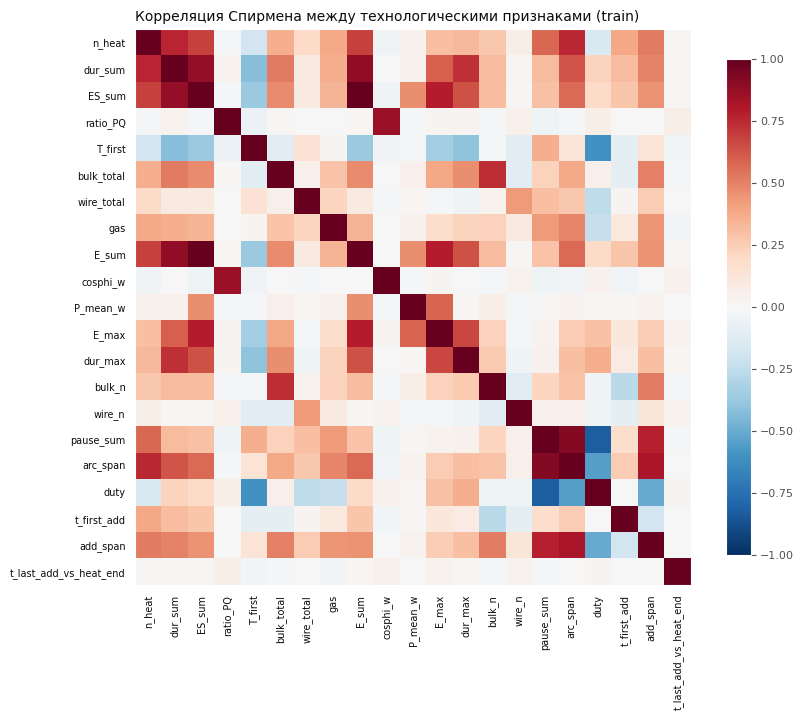

,признак 1,признак 2,Спирмен
0,ES_sum,E_sum,0.999
1,pause_sum,arc_span,0.921
2,dur_sum,E_sum,0.884
3,dur_sum,ES_sum,0.882
4,ratio_PQ,cosphi_w,0.865
5,pause_sum,duty,-0.822
6,arc_span,add_span,0.819
7,E_sum,E_max,0.789


,"VIF, набор B","VIF, без ES_sum и P_mean_w"
ES_sum,3157.3,NaN
E_sum,3143.8,14.6
dur_sum,34.6,17.2
cosphi_w,9.4,4.3
E_max,5.5,5.4
P_mean_w,5.5,NaN
ratio_PQ,4.4,4.3
dur_max,4.4,4.4
n_heat,4.0,4.0
bulk_total,3.5,3.5


In [23]:
spearman_matrix = merged_train[AGG_COLUMNS].corr(method='spearman')
fig, ax = plt.subplots(figsize=(8.5, 7.5), facecolor='white')
image = ax.imshow(spearman_matrix, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(AGG_COLUMNS)))
ax.set_xticklabels(AGG_COLUMNS, rotation=90, fontsize=7, color=INK)
ax.set_yticks(range(len(AGG_COLUMNS)))
ax.set_yticklabels(AGG_COLUMNS, fontsize=7, color=INK)
ax.set_title('Корреляция Спирмена между технологическими признаками (train)', loc='left', color=INK, fontsize=10)
colorbar = fig.colorbar(image, ax=ax, shrink=0.8)
colorbar.ax.tick_params(colors=INK_SECONDARY, labelsize=8)
save_figure(fig, 'corr_features.png')

upper = np.triu_indices_from(spearman_matrix, k=1)
pairs = pd.DataFrame({'признак 1': spearman_matrix.columns[upper[0]], 'признак 2': spearman_matrix.columns[upper[1]],
                      'Спирмен': spearman_matrix.to_numpy()[upper]})
display(pairs.reindex(pairs['Спирмен'].abs().sort_values(ascending=False).index).head(8).reset_index(drop=True).round(3))


def vif(columns):
    # VIF_i — диагональ обратной корреляционной матрицы
    return pd.Series(np.diag(np.linalg.inv(np.corrcoef(merged_train[columns].to_numpy(dtype=float), rowvar=False))), index=columns)


SET_B_REDUCED = [c for c in SET_B if c not in ['ES_sum', 'P_mean_w']]
display(pd.DataFrame({'VIF, набор B': vif(SET_B), 'VIF, без ES_sum и P_mean_w': vif(SET_B_REDUCED)})
        .sort_values('VIF, набор B', ascending=False).round(1))

### 7.3. Материалы

Для материалов, которые добавлялись не менее чем в 5% партий, оценивается корреляция объёма с `T_last` среди партий, где материал добавляли. Для более редких материалов число партий слишком мало для надёжной оценки связи.

In [24]:
dose_rows = {}
for name in frequent:
    used = merged_train[name] > 0
    dose_rows[name] = {'партий': int(used.sum()),
                       'Пирсон': merged_train.loc[used, name].corr(merged_train.loc[used, 'T_last']),
                       'Спирмен': merged_train.loc[used, name].corr(merged_train.loc[used, 'T_last'], method='spearman')}
display(pd.DataFrame(dose_rows).T.astype({'партий': int}).sort_values('партий', ascending=False).round(3))
together = (merged_train['Bulk_9'] > 0) == (merged_train['Wire_8'] > 0)
print(f'Bulk_9 и Wire_8 добавлялись в одних и тех же партиях: {bool(together.all())} '
      f'({int((merged_train["Bulk_9"] > 0).sum())} партий).')

,партий,Пирсон,Спирмен
Wire_1,1725,0.280,0.255
Bulk_14,1546,0.058,0.033
Bulk_12,1357,0.227,0.186
Bulk_15,1265,0.163,0.108
Bulk_3,727,-0.044,-0.029
Bulk_4,606,0.009,-0.004
Wire_2,587,-0.144,-0.198
Bulk_6,289,0.080,0.066
Bulk_1,169,-0.154,-0.316
Bulk_10,97,0.134,0.166


Bulk_9 и Wire_8 добавлялись в одних и тех же партиях: True (11 партий).


### Выводы по объединённой таблице

- **Распределения.** Большинство технологических признаков скошены вправо: суммарные длительности, энергии, паузы и интервалы имеют длинные хвосты, связанные с длительными простоями и продолжительной обработкой отдельных партий. Отношение мощностей `ratio_PQ` и коэффициент мощности `cosphi_w` изменяются в узких диапазонах (SD 0.07 и 0.02); число видов материалов принимает несколько значений.
- **Связь с целью умеренная.** Наибольшие корреляции с `T_last` — у `T_first` (r = 0.31), суммарной длительности нагрева (0.30) и энергии (0.28); у электрических характеристик режима (`ratio_PQ`, `cosphi_w`, `P_mean_w`) и коэффициента заполнения связь практически отсутствует (|r| < 0.03).
- **Начальная температура маскирует эффект нагрева.** Энергия нагрева отрицательно связана с `T_first`; при контроле `T_first` её связь с `T_last` усиливается: `E_sum` 0.28 → 0.43, `dur_sum` 0.30 → 0.49. Это согласуется с тем, что холодные партии получают больше энергии, но остаётся интерпретацией наблюдательных данных, а не причинным выводом.
- **Избыточность.** Энергетические признаки почти дублируют друг друга (`E_sum` и `ES_sum`: ρ = 0.999), в наборе B VIF `E_sum` и `ES_sum` превышает 3 000. Исключение `ES_sum` и `P_mean_w` снижает максимальный VIF до 17; этот состав используется для линейной модели. Сильно связаны и признаки хронологии: `pause_sum` с `arc_span` (ρ = 0.92) и с `duty` (ρ = −0.82).
- **Материалы.** Наибольшая связь объёма с `T_last` у `Wire_1` (r = 0.28) и `Bulk_12` (0.23); у `Bulk_1` корреляция Пирсона заметно смещена одной партией (322). `Bulk_9` и `Wire_8` добавляются только вместе — вероятно, это технологически связанная пара.

## 8. Модели: обучение и выбор по кросс-валидации

**Протокол.** Все модели обучаются и оцениваются на одних и тех же пяти фолдах `TimeSeriesSplit` внутри train (обучающие части от 293 до 1 453 партий, проверочные блоки по 290 партий). Для каждой модели приводятся средняя MAE по фолдам, её стандартное отклонение (SD) между фолдами, R² и время обучения и прогноза. Конфигурации сравниваются попарно по тем же фолдам: средняя разность MAE с эталоном, SD этих разностей и число фолдов из пяти, где конфигурация лучше. Если более сложная конфигурация улучшает среднюю MAE меньше чем на 0.02 °C, выбирается более простая; установленная граница является правилом выбора и не несет статистической значимости. Гиперпараметры (`alpha` у `Ridge`, параметры бустингов) подбираются вложенной кросс-валидацией внутри обучающей части каждого фолда.

Решения о наборе признаков и параметризации цели принимаются по тем же фолдам, поэтому оценки на кросс-валидации служат для сравнения конфигураций, а несмещённую оценку итоговой модели даёт только тестовая выборка (раздел 9).

**Кандидаты:** константа (медиана) как нижняя граница; линейная модель `Ridge`; решающее дерево и случайный лес; градиентные бустинги LightGBM и CatBoost с подбором гиперпараметров в Optuna; нейросеть TabM; табличная фундаментальная модель TabPFN v2.

In [25]:
FOLD_COLUMNS = [f'фолд {k}' for k in range(1, N_FOLDS + 1)]
SCORES, OOF, FOLD_PARAMS = {}, {}, {}   # метрики по фолдам, внефолдовые прогнозы и гиперпараметры, выбранные в фолдах


def cv_run(name, estimator, X=None, y=None):
    X = features_train if X is None else X
    y = t_last if y is None else y
    oof = pd.Series(np.nan, index=X.index)
    maes, r2s, fit_times, predict_times, params = [], [], [], [], []
    for fit_idx, valid_idx in cv.split(X):
        model = clone(estimator)
        start = time.perf_counter()
        model.fit(X.iloc[fit_idx], y.iloc[fit_idx])
        fit_times.append(time.perf_counter() - start)
        start = time.perf_counter()
        pred = model.predict(X.iloc[valid_idx])
        predict_times.append(time.perf_counter() - start)
        maes.append(mean_absolute_error(y.iloc[valid_idx], pred))
        r2s.append(r2_score(y.iloc[valid_idx], pred))
        oof.iloc[valid_idx] = pred
        inner = getattr(model, 'estimator_', model)
        if hasattr(inner, 'best_params_'):
            params.append(inner.best_params_)
    SCORES[name] = {'MAE': np.mean(maes), 'SD по фолдам': np.std(maes, ddof=1), **dict(zip(FOLD_COLUMNS, maes)),
                    'R²': np.mean(r2s), 'время fit, с': np.mean(fit_times), 'время predict, с': np.mean(predict_times)}
    OOF[name] = oof
    if params:
        FOLD_PARAMS[name] = params
    return SCORES[name]


def scores_table(names, labels=None):
    table = pd.DataFrame({n: SCORES[n] for n in names}).T
    if labels is not None:
        table.index = labels
    return table.rename_axis('модель')


def ablation_table(runs, reference):
    # runs: подпись -> имя запуска; парные разности MAE с эталоном по тем же фолдам
    ref = np.array([SCORES[runs[reference]][c] for c in FOLD_COLUMNS])
    rows = {}
    for label, key in runs.items():
        diff = np.array([SCORES[key][c] for c in FOLD_COLUMNS]) - ref
        rows[label] = {'MAE': SCORES[key]['MAE'], 'SD по фолдам': SCORES[key]['SD по фолдам'],
                       **{c: SCORES[key][c] for c in FOLD_COLUMNS}, 'Δ MAE к эталону': diff.mean(),
                       'SD разностей': diff.std(ddof=1), 'фолдов лучше эталона': int((diff < 0).sum())}
    return pd.DataFrame(rows).T.astype({'фолдов лучше эталона': int}).rename_axis('конфигурация')

### 8.1. Базовые модели, наборы признаков и параметризация цели

Признаки, масштаб которых важен для модели, масштабируются внутри конвейера (`Pipeline`) по обучающей части фолда. `Ridge` использует `StandardScaler` и состав без избыточных признаков (подраздел 7.2): из наборов C и D исключены суммарные объёмы и числа видов материалов (они выражаются через поматериальные признаки), индикаторы, совпадающие с другими столбцами (`was_added_Bulk_8`, `was_added_Wire_8`), а из D — `arc_span` и `pause_sum` (линейные тождества хронологии); во всех наборах, кроме A, исключены `ES_sum` и `P_mean_w`. Деревья получают признаки без преобразований. Решающее дерево (глубина 5, не менее 20 партий в листе) и случайный лес (300 деревьев, не менее 3 партий в листе, половина признаков в разбиении) заданы фиксированно: на этом шаге сравниваются наборы признаков, а не настройки моделей.

Для параметризации цели сравниваются два варианта: прогноз `T_last` напрямую и прогноз приращения ΔT = `T_last` − `T_first` с последующим восстановлением `T_last`. Набор и цель выбираются по среднему MAE `Ridge` и случайного леса.

In [26]:
class DeltaTarget(BaseEstimator, RegressorMixin):
    # обучает модель на ΔT = T_last − T_first и возвращает прогноз T_last
    def __init__(self, estimator, base='T_first'):
        self.estimator = estimator
        self.base = base

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator).fit(X, np.asarray(y) - X[self.base].to_numpy())
        return self

    def predict(self, X):
        return self.estimator_.predict(X) + X[self.base].to_numpy()


def with_target(model, mode):
    return DeltaTarget(model) if mode == 'delta' else model


def select_columns(columns):
    return ColumnTransformer([('keep', 'passthrough', list(columns))], remainder='drop', verbose_feature_names_out=False)


def make_tree_pipeline(columns, model):
    return Pipeline([('select', select_columns(columns)), ('model', model)]).set_output(transform='pandas')


RIDGE_DROP = {'A': [], 'B': ['ES_sum', 'P_mean_w'],
              'C': ['bulk_total', 'wire_total', 'bulk_n', 'wire_n', 'was_added_Bulk_8', 'was_added_Wire_8', 'ES_sum', 'P_mean_w'],
              'D': ['bulk_total', 'wire_total', 'bulk_n', 'wire_n', 'was_added_Bulk_8', 'was_added_Wire_8', 'arc_span', 'pause_sum',
                    'ES_sum', 'P_mean_w']}
ALPHA_GRID = np.logspace(-2, 3, 11)
RF_PARAMS = dict(n_estimators=300, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=RANDOM_STATE)
DT_PARAMS = dict(max_depth=5, min_samples_leaf=20, random_state=RANDOM_STATE)


def ridge_columns(set_name):
    return [c for c in FEATURE_SETS[set_name] if c not in RIDGE_DROP[set_name]]


def ridge_model(set_name):
    pipe = Pipeline([('select', select_columns(ridge_columns(set_name))), ('scale', StandardScaler()),
                     ('ridge', Ridge())]).set_output(transform='pandas')
    return GridSearchCV(pipe, {'ridge__alpha': ALPHA_GRID}, cv=TimeSeriesSplit(3), scoring='neg_mean_absolute_error')


def base_model(kind, set_name, mode='level'):
    model = {'ridge': lambda: ridge_model(set_name),
             'dt': lambda: make_tree_pipeline(FEATURE_SETS[set_name], DecisionTreeRegressor(**DT_PARAMS)),
             'rf': lambda: make_tree_pipeline(FEATURE_SETS[set_name], RandomForestRegressor(**RF_PARAMS))}[kind]()
    return with_target(model, mode)


BASE_LABELS = {'ridge': 'Ridge', 'dt': 'Решающее дерево', 'rf': 'Случайный лес'}
key = lambda kind, set_name, mode='level': f'{BASE_LABELS[kind]} {set_name}' + (' [ΔT]' if mode == 'delta' else '')

,Ridge,Решающее дерево,Случайный лес,среднее Ridge и леса
набор,,,,
A,6.695,7.313,6.742,6.718
B,6.573,7.444,6.678,6.626
C,6.302,7.503,6.580,6.441
D,5.981,7.443,6.496,6.239


,MAE,SD по фолдам,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,Δ MAE к эталону,SD разностей,фолдов лучше эталона
конфигурация,,,,,,,,,,
A,6.695,0.511,6.194,7.477,6.512,6.914,6.377,0.000,0.000,0
B,6.573,0.521,6.019,7.319,6.473,6.852,6.204,-0.122,0.065,5
C,6.302,0.592,6.341,7.114,5.818,6.587,5.651,-0.393,0.353,4
D,5.981,0.558,5.855,6.750,5.621,6.324,5.358,-0.713,0.265,5


,MAE,SD по фолдам,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,Δ MAE к эталону,SD разностей,фолдов лучше эталона
конфигурация,,,,,,,,,,
A,6.742,0.450,6.357,7.460,6.521,6.900,6.471,0.000,0.000,0
B,6.678,0.334,6.385,7.214,6.542,6.781,6.467,-0.064,0.118,3
C,6.580,0.460,6.507,7.280,6.245,6.748,6.120,-0.162,0.191,4
D,6.496,0.373,6.484,7.078,6.267,6.556,6.094,-0.246,0.215,4


Набор признаков для всех моделей: D.


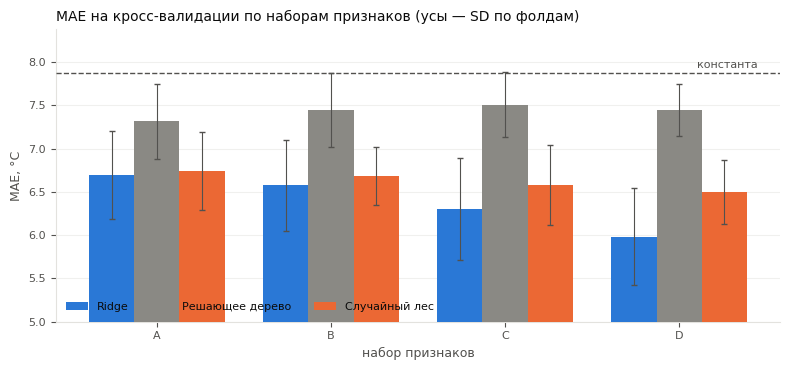

In [27]:
cv_run('Константа (медиана)', DummyRegressor(strategy='median'))
SETS = ['A', 'B', 'C', 'D']
for set_name in SETS:
    for kind in BASE_LABELS:
        cv_run(key(kind, set_name), base_model(kind, set_name))
by_set = pd.DataFrame({BASE_LABELS[kind]: {s: SCORES[key(kind, s)]['MAE'] for s in SETS} for kind in BASE_LABELS}).rename_axis('набор')
by_set['среднее Ridge и леса'] = (by_set['Ridge'] + by_set['Случайный лес']) / 2
display(by_set.round(3))
display(ablation_table({s: key('ridge', s) for s in SETS}, reference='A').round(3))
display(ablation_table({s: key('rf', s) for s in SETS}, reference='A').round(3))
MAIN_SET = next(s for s in SETS if by_set.loc[s, 'среднее Ridge и леса'] - by_set['среднее Ridge и леса'].min() < 0.02)
print(f'Набор признаков для всех моделей: {MAIN_SET}.')

fig, ax = plt.subplots(figsize=(8, 3.8), facecolor='white')
for i, (kind, color) in enumerate(zip(BASE_LABELS, [BAR_COLOR, NEUTRAL, ACCENT])):
    ax.bar(np.arange(len(SETS)) + (i - 1) * 0.26, [SCORES[key(kind, s)]['MAE'] for s in SETS], 0.26,
           yerr=[SCORES[key(kind, s)]['SD по фолдам'] for s in SETS], color=color, label=BASE_LABELS[kind], zorder=3,
           error_kw={'ecolor': INK_SECONDARY, 'capsize': 2, 'linewidth': 0.8})
ax.axhline(SCORES['Константа (медиана)']['MAE'], color=INK_SECONDARY, linestyle='--', linewidth=1, zorder=4)
ax.text(len(SETS) - 0.55, SCORES['Константа (медиана)']['MAE'] + 0.05, 'константа', color=INK_SECONDARY, fontsize=8, ha='right')
ax.set_xticks(np.arange(len(SETS)))
ax.set_xticklabels(SETS)
ax.set_ylim(5, SCORES['Константа (медиана)']['MAE'] + 0.5)
ax.legend(fontsize=8, labelcolor=INK, frameon=False, loc='lower left', ncol=3)
style_axes(ax, 'MAE на кросс-валидации по наборам признаков (усы — SD по фолдам)', 'набор признаков', 'MAE, °C')
save_figure(fig, 'models_feature_sets.png')

In [28]:
for kind in BASE_LABELS:
    cv_run(key(kind, MAIN_SET, 'delta'), base_model(kind, MAIN_SET, 'delta'))
target_table = ablation_table({f'{BASE_LABELS[kind]}, {label}': key(kind, MAIN_SET, mode)
                               for kind in BASE_LABELS for mode, label in [('level', 'T_last'), ('delta', 'ΔT')]},
                              reference='Ridge, T_last')
display(target_table.round(3))
mean_mae = lambda mode: (SCORES[key('ridge', MAIN_SET, mode)]['MAE'] + SCORES[key('rf', MAIN_SET, mode)]['MAE']) / 2
TARGET_MODE = 'delta' if mean_mae('level') - mean_mae('delta') >= 0.02 else 'level'
print(f'Среднее MAE Ridge и леса: T_last {mean_mae("level"):.3f}, ΔT {mean_mae("delta"):.3f}; '
      f'цель базовых моделей — {"ΔT" if TARGET_MODE == "delta" else "T_last"}.')
print('alpha Ridge, выбранный в фолдах:', [round(float(p['ridge__alpha']), 2) for p in FOLD_PARAMS[key('ridge', MAIN_SET, TARGET_MODE)]])
MODEL_KEYS = {'Константа (медиана)': 'Константа (медиана)', **{BASE_LABELS[kind]: key(kind, MAIN_SET, TARGET_MODE) for kind in BASE_LABELS}}

,MAE,SD по фолдам,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,Δ MAE к эталону,SD разностей,фолдов лучше эталона
конфигурация,,,,,,,,,,
"Ridge, T_last",5.981,0.558,5.855,6.750,5.621,6.324,5.358,0.000,0.000,0
"Ridge, ΔT",5.943,0.515,5.812,6.597,5.676,6.321,5.308,-0.039,0.076,4
"Решающее дерево, T_last",7.443,0.298,7.710,7.705,6.987,7.362,7.452,1.462,0.500,0
"Решающее дерево, ΔT",7.876,0.419,8.379,8.127,7.489,7.981,7.403,1.894,0.431,0
"Случайный лес, T_last",6.496,0.373,6.484,7.078,6.267,6.556,6.094,0.514,0.221,0
"Случайный лес, ΔT",6.108,0.131,6.137,6.274,5.988,6.179,5.963,0.127,0.432,2


Среднее MAE Ridge и леса: T_last 6.239, ΔT 6.026; цель базовых моделей — ΔT.
alpha Ridge, выбранный в фолдах: [10.0, 31.62, 31.62, 31.62, 31.62]


**Выводы.** Каждое расширение набора признаков снижает MAE: от A к D у `Ridge` на 0.71 °C (лучше во всех пяти фолдах), у случайного леса — на 0.25 °C (в четырёх из пяти); неглубокое решающее дерево от состава признаков почти не зависит. Основным выбран набор D. Прогноз приращения ΔT улучшает `Ridge` (5.943 против 5.981) и особенно случайный лес (6.108 против 6.496, при этом SD по фолдам снижается с 0.37 до 0.13), но ухудшает решающее дерево. Для базовых моделей и бустингов цель — ΔT; для TabM и TabPFN параметризация проверяется отдельно, поскольку её эффект зависит от модели. `alpha` у `Ridge`, подобранный внутри фолдов, лежит в пределах 10–32. Лучшая базовая модель — `Ridge` (MAE 5.94 °C при 7.88 у константы); решающее дерево на ΔT не лучше константы и далее служит только нижней границей.

### 8.2. Градиентный бустинг: LightGBM и CatBoost

Функция потерь выбирается из L1 и Huber, устойчивых к крупным ошибкам. Гиперпараметры подбираются в Optuna (сэмплер TPE, tree-structured Parzen estimator) по MAE на внутренней `TimeSeriesSplit(3)` обучающей части фолда; проверочный блок внешнего фолда в подбор не попадает (вложенная кросс-валидация). Число деревьев в каждой пробе определяется ранней остановкой по последним 15% обучающей части (по времени), после чего модель переобучается на всей обучающей части.

| Модель | Подбираемые гиперпараметры | Проб в каждом фолде |
|---|---|---|
| LightGBM | функция потерь и порог Huber, `learning_rate`, `num_leaves`, `min_child_samples`, `subsample`, `colsample_bytree`, `reg_lambda` | 30 |
| CatBoost | функция потерь и порог Huber, `learning_rate`, `depth`, `l2_leaf_reg`, `rsm`, `random_strength` | 12 |

In [29]:
N_THREADS = 2
BUDGET = {'lightgbm': {'nested': 30, 'final': 80}, 'catboost': {'nested': 12, 'final': 30}}


def make_booster(kind, params, n_iter):
    p = dict(params)
    loss, delta = p.pop('loss'), p.pop('huber_delta', None)
    if kind == 'lightgbm':
        objective = {'objective': 'huber', 'alpha': delta} if loss == 'huber' else {'objective': loss}
        return LGBMRegressor(n_estimators=n_iter, metric='l1', subsample_freq=1, n_jobs=N_THREADS, random_state=RANDOM_STATE,
                             deterministic=True, force_row_wise=True, verbose=-1, **objective, **p)
    loss_function = {'l1': 'MAE', 'huber': f'Huber:delta={delta}'}[loss]
    return CatBoostRegressor(iterations=n_iter, loss_function=loss_function, eval_metric='MAE', thread_count=N_THREADS,
                             random_seed=RANDOM_STATE, verbose=0, allow_writing_files=False, **p)


class BoostingEarlyStop(BaseEstimator, RegressorMixin):
    # число деревьев — по ранней остановке на последних `holdout` строках обучающей части, затем переобучение на всей части
    def __init__(self, kind, params, columns, holdout=0.15, rounds=50, max_iter=1500):
        self.kind = kind
        self.params = params
        self.columns = columns
        self.holdout = holdout
        self.rounds = rounds
        self.max_iter = max_iter

    def fit(self, X, y):
        Xc, y = X[list(self.columns)], np.asarray(y, dtype=float)
        cut = len(Xc) - max(int(round(len(Xc) * self.holdout)), 20)
        probe = make_booster(self.kind, self.params, self.max_iter)
        if self.kind == 'lightgbm':
            probe.fit(Xc.iloc[:cut], y[:cut], eval_set=[(Xc.iloc[cut:], y[cut:])],
                      callbacks=[early_stopping(self.rounds, verbose=False)])
            best = probe.best_iteration_ or self.max_iter
        else:
            probe.fit(Xc.iloc[:cut], y[:cut], eval_set=(Xc.iloc[cut:], y[cut:]), early_stopping_rounds=self.rounds,
                      use_best_model=True)
            best = probe.get_best_iteration() + 1
        self.n_iter_ = max(int(best), 10)
        self.model_ = make_booster(self.kind, self.params, self.n_iter_).fit(Xc, y)
        return self

    def predict(self, X):
        return self.model_.predict(X[list(self.columns)])


def suggest_params(kind, trial):
    if kind == 'lightgbm':
        params = {'loss': trial.suggest_categorical('loss', ['l1', 'huber']),
                  'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
                  'num_leaves': trial.suggest_int('num_leaves', 4, 48, log=True),
                  'min_child_samples': trial.suggest_int('min_child_samples', 5, 60),
                  'subsample': trial.suggest_float('subsample', 0.5, 1.0),
                  'colsample_bytree': trial.suggest_float('colsample_bytree', 0.3, 1.0),
                  'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 30.0, log=True)}
    else:
        params = {'loss': trial.suggest_categorical('loss', ['l1', 'huber']),
                  'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
                  'depth': trial.suggest_int('depth', 3, 8),
                  'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 30.0, log=True),
                  'rsm': trial.suggest_float('rsm', 0.3, 1.0),
                  'random_strength': trial.suggest_float('random_strength', 0.1, 5.0, log=True)}
    if params['loss'] == 'huber':
        params['huber_delta'] = trial.suggest_float('huber_delta', 2.0, 15.0)
    return params


class OptunaBooster(BaseEstimator, RegressorMixin):
    # подбор гиперпараметров в Optuna по MAE на внутренней TimeSeriesSplit и обучение лучшей конфигурации
    def __init__(self, kind, columns, n_trials=20, inner_splits=3, seed=RANDOM_STATE):
        self.kind = kind
        self.columns = columns
        self.n_trials = n_trials
        self.inner_splits = inner_splits
        self.seed = seed

    def fit(self, X, y):
        y = pd.Series(np.asarray(y, dtype=float), index=X.index)
        inner = TimeSeriesSplit(self.inner_splits)

        def objective(trial):
            model = BoostingEarlyStop(self.kind, suggest_params(self.kind, trial), self.columns)
            return float(np.mean([mean_absolute_error(y.iloc[v], clone(model).fit(X.iloc[f], y.iloc[f]).predict(X.iloc[v]))
                                  for f, v in inner.split(X)]))

        sampler = optuna.samplers.TPESampler(seed=self.seed, n_startup_trials=max(5, self.n_trials // 4))
        self.study_ = optuna.create_study(direction='minimize', sampler=sampler)
        self.study_.optimize(objective, n_trials=self.n_trials)
        self.best_params_ = suggest_params(self.kind, optuna.trial.FixedTrial(self.study_.best_params))
        self.model_ = BoostingEarlyStop(self.kind, self.best_params_, self.columns).fit(X, y)
        return self

    def predict(self, X):
        return self.model_.predict(X)

In [30]:
BOOSTERS = {'LightGBM + Optuna': 'lightgbm', 'CatBoost + Optuna': 'catboost'}
for label, kind in BOOSTERS.items():
    cv_run(label, with_target(OptunaBooster(kind, FEATURE_SETS[MAIN_SET], n_trials=BUDGET[kind]['nested']), TARGET_MODE))
    display(pd.DataFrame(FOLD_PARAMS[label], index=FOLD_COLUMNS).rename_axis(f'{label}: гиперпараметры по фолдам').round(3))
MODEL_KEYS.update({label: label for label in BOOSTERS})
display(ablation_table({m: MODEL_KEYS[m] for m in ['Ridge', 'Случайный лес', *BOOSTERS]}, reference='Ridge').round(3))

,loss,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,huber_delta
LightGBM + Optuna: гиперпараметры по фолдам,,,,,,,,
фолд 1,huber,0.019,6,5,0.816,0.536,0.008,6.221
фолд 2,huber,0.135,5,8,0.820,0.733,0.005,12.678
фолд 3,huber,0.143,47,9,0.911,0.756,0.004,7.358
фолд 4,huber,0.052,13,11,0.579,0.936,11.076,12.080
фолд 5,huber,0.022,6,7,0.950,0.713,0.190,10.463


,loss,learning_rate,depth,l2_leaf_reg,rsm,random_strength,huber_delta
CatBoost + Optuna: гиперпараметры по фолдам,,,,,,,
фолд 1,l1,0.026,3,27.093,0.662,4.630,NaN
фолд 2,huber,0.020,4,29.096,0.668,1.076,14.776
фолд 3,huber,0.020,4,29.096,0.668,1.076,14.776
фолд 4,huber,0.020,4,29.096,0.668,1.076,14.776
фолд 5,l1,0.021,3,16.198,0.327,0.635,NaN


,MAE,SD по фолдам,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,Δ MAE к эталону,SD разностей,фолдов лучше эталона
конфигурация,,,,,,,,,,
Ridge,5.943,0.515,5.812,6.597,5.676,6.321,5.308,0.000,0.000,0
Случайный лес,6.108,0.131,6.137,6.274,5.988,6.179,5.963,0.165,0.394,2
LightGBM + Optuna,6.202,0.357,6.412,6.631,6.122,6.164,5.679,0.259,0.311,1
CatBoost + Optuna,6.301,0.735,7.497,6.494,5.793,6.013,5.706,0.358,0.787,2


**Выводы.** Бустинги не превзошли `Ridge`: LightGBM — 6.20 °C, CatBoost — 6.30 °C против 5.94 °C (лучше `Ridge` лишь в одном–двух фолдах из пяти). Подобранные гиперпараметры заметно различаются между фолдами: LightGBM во всех фолдах выбирает потери Huber, но `learning_rate` меняется от 0.02 до 0.14, а `num_leaves` — от 5 до 47; CatBoost особенно неустойчив на первом, самом коротком фолде (MAE 7.50 против 5.7–6.5 на остальных). Возможные причины — небольшой объём обучающих частей и близкая к линейной зависимость на подготовленных признаках; отдельно эти объяснения не проверялись.

### 8.3. TabPFN v2 и нейросеть TabM

**TabPFN v2** — трансформер, предобученный на синтетических табличных задачах; он строит прогноз по обучающей выборке как по контексту, без градиентного обучения на наших данных, и применяет собственную предобработку признаков. Используются веса версии 2 (файл `models/tabpfn-v2-regressor.ckpt`, репозиторий Hugging Face `Prior-Labs/TabPFN-v2-reg`, лицензия Prior Labs License 1.1 — Apache 2.0 с дополнительным требованием указания авторства), расчёт на CPU, ансамбль из 8 проходов. Сравниваются цели `T_last` и ΔT.

**TabM** — ансамбль из 32 многослойных перцептронов с общими весами (BatchEnsemble); прогноз — среднее по ансамблю. Архитектура фиксирована: два блока по 256 нейронов, dropout 0.1, оптимизатор AdamW (скорость обучения 2·10⁻³, weight decay 3·10⁻⁴), пакет 256. Число эпох (не более 300) выбирается ранней остановкой по последним 15% обучающей части, после чего сеть переобучается на всей части. Последовательно выбираются масштабирование признаков (`QuantileTransformer` или `StandardScaler`), функция потерь (MSE или L1) и цель (`T_last` или ΔT).

In [31]:
TABPFN_PATH = MODELS_DIR / 'tabpfn-v2-regressor.ckpt'


def tabpfn_model(**kwargs):
    # по умолчанию tabpfn ограничивает расчёт на CPU 1 000 строками; обучающие части здесь до 1 453 партий
    return TabPFNRegressor.create_default_for_version(ModelVersion.V2, model_path=str(TABPFN_PATH), device='cpu', n_estimators=8,
                                                      random_state=RANDOM_STATE, inference_config={'MAX_CPU_SAMPLES': 5000}, **kwargs)


for mode in ['level', 'delta']:
    cv_run('TabPFN v2' + (' [ΔT]' if mode == 'delta' else ''),
           with_target(make_tree_pipeline(FEATURE_SETS[MAIN_SET], tabpfn_model()), mode))
tabpfn_table = ablation_table({'T_last': 'TabPFN v2', 'ΔT': 'TabPFN v2 [ΔT]'}, reference='T_last')
display(tabpfn_table.round(3))
TABPFN_MODE = 'delta' if tabpfn_table.loc['T_last', 'MAE'] - tabpfn_table.loc['ΔT', 'MAE'] >= 0.02 else 'level'
MODEL_KEYS['TabPFN v2'] = 'TabPFN v2' + (' [ΔT]' if TABPFN_MODE == 'delta' else '')
print(f'TabPFN v2: цель {"ΔT" if TABPFN_MODE == "delta" else "T_last"}; обучение {SCORES[MODEL_KEYS["TabPFN v2"]]["время fit, с"]:.1f} с, '
      f'прогноз проверочного блока {SCORES[MODEL_KEYS["TabPFN v2"]]["время predict, с"]:.1f} с на фолд.')

,MAE,SD по фолдам,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,Δ MAE к эталону,SD разностей,фолдов лучше эталона
конфигурация,,,,,,,,,,
T_last,5.636,0.459,5.509,6.277,5.416,5.891,5.086,0.000,0.000,0
ΔT,5.627,0.406,5.651,6.191,5.418,5.772,5.102,-0.009,0.102,2


TabPFN v2: цель T_last; обучение 0.4 с, прогноз проверочного блока 52.5 с на фолд.


In [32]:
class TabMRegressor(BaseEstimator, RegressorMixin):
    # TabM: k многослойных перцептронов с общими весами; цель стандартизуется по обучающей части
    def __init__(self, columns, quantile=False, loss='l1', k=32, n_blocks=2, d_block=256, dropout=0.1, lr=2e-3,
                 weight_decay=3e-4, batch_size=256, max_epochs=300, patience=20, holdout=0.15, seed=RANDOM_STATE):
        self.columns = columns
        self.quantile = quantile
        self.loss = loss
        self.k = k
        self.n_blocks = n_blocks
        self.d_block = d_block
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.holdout = holdout
        self.seed = seed

    def _preprocessor(self):
        scaler = (QuantileTransformer(output_distribution='normal', n_quantiles=250, random_state=RANDOM_STATE)
                  if self.quantile else StandardScaler())
        return Pipeline([('select', select_columns(self.columns)), ('scale', scaler)]).set_output(transform='pandas')

    @staticmethod
    def _predict_mean(model, x):
        model.eval()
        with torch.no_grad():
            return model(x).squeeze(-1).mean(dim=1).numpy()

    def _train(self, X, y, n_epochs, X_val=None, y_val=None):
        torch.manual_seed(self.seed)
        rng = np.random.default_rng(self.seed)
        y_mean, y_std = float(y.mean()), float(y.std())
        model = TabM.make(n_num_features=X.shape[1], d_out=1, k=self.k, n_blocks=self.n_blocks, d_block=self.d_block,
                          dropout=self.dropout)
        optimizer = torch.optim.AdamW(model.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        x_t = torch.tensor(np.asarray(X, dtype=np.float32))
        y_t = torch.as_tensor((y - y_mean) / y_std, dtype=torch.float32)
        x_v = None if X_val is None else torch.tensor(np.asarray(X_val, dtype=np.float32))
        loss_fn = torch.nn.functional.mse_loss if self.loss == 'mse' else torch.nn.functional.l1_loss
        best_mae, best_epoch, wait = np.inf, 1, 0
        for epoch in range(1, n_epochs + 1):
            model.train()
            order = rng.permutation(len(x_t))
            for start in range(0, len(order), self.batch_size):
                idx = torch.as_tensor(order[start:start + self.batch_size])
                pred = model(x_t[idx]).squeeze(-1)                                  # (пакет, k): прогноз каждого члена ансамбля
                loss = loss_fn(pred, y_t[idx].unsqueeze(1).expand_as(pred))
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            if x_v is not None:
                mae = np.abs(self._predict_mean(model, x_v) * y_std + y_mean - y_val).mean()
                if mae < best_mae - 1e-6:
                    best_mae, best_epoch, wait = mae, epoch, 0
                else:
                    wait += 1
                    if wait >= self.patience:
                        break
        return model, best_epoch, (y_mean, y_std)

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        cut = len(X) - max(int(round(len(X) * self.holdout)), 20)
        probe = self._preprocessor().fit(X.iloc[:cut])
        _, self.n_epochs_, _ = self._train(probe.transform(X.iloc[:cut]).to_numpy(), y[:cut], self.max_epochs,
                                           probe.transform(X.iloc[cut:]).to_numpy(), y[cut:])
        self.prep_ = self._preprocessor().fit(X)
        self.model_, _, self.y_stats_ = self._train(self.prep_.transform(X).to_numpy(), y, self.n_epochs_)
        return self

    def predict(self, X):
        y_mean, y_std = self.y_stats_
        return self._predict_mean(self.model_, torch.tensor(self.prep_.transform(X).to_numpy(dtype=np.float32))) * y_std + y_mean


def tabm_model(prep, loss, mode):
    return with_target(TabMRegressor(FEATURE_SETS[MAIN_SET], quantile=(prep == 'QuantileTransformer'), loss=loss), mode)


tabm_key = lambda prep, loss, mode: f'TabM [{prep}, {loss.upper()}, {"ΔT" if mode == "delta" else "T_last"}]'


def tabm_step(title, configs):
    # оценивает варианты одного шага выбора конфигурации; эталон — первый вариант
    for config in configs:
        if tabm_key(*config) not in SCORES:
            cv_run(tabm_key(*config), tabm_model(*config))
    table = ablation_table({tabm_key(*c): tabm_key(*c) for c in configs}, reference=tabm_key(*configs[0]))
    display(table.round(3).rename_axis(f'TabM: {title}'))
    return {tabm_key(*c): c for c in configs}, table

In [33]:
options, table = tabm_step('масштабирование признаков', [('QuantileTransformer', 'mse', 'delta'), ('StandardScaler', 'mse', 'delta')])
prep = options[table['MAE'].idxmin()][0]
options, table = tabm_step('функция потерь', [(prep, 'mse', 'delta'), (prep, 'l1', 'delta')])
loss = options[table['MAE'].idxmin()][1]
options, table = tabm_step('цель', [(prep, loss, 'level'), (prep, loss, 'delta')])
mode = 'delta' if table['MAE'].iloc[0] - table['MAE'].iloc[1] >= 0.02 else 'level'
TABM_CONFIG = (prep, loss, mode)
MODEL_KEYS['TabM'] = tabm_key(*TABM_CONFIG)
print('Итоговая конфигурация:', MODEL_KEYS['TabM'])

,MAE,SD по фолдам,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,Δ MAE к эталону,SD разностей,фолдов лучше эталона
TabM: масштабирование признаков,,,,,,,,,,
"TabM [QuantileTransformer, MSE, ΔT]",6.217,0.597,6.465,7.062,5.824,6.219,5.513,0.000,0.000,0
"TabM [StandardScaler, MSE, ΔT]",5.969,0.517,5.832,6.775,5.715,6.114,5.407,-0.248,0.229,5


,MAE,SD по фолдам,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,Δ MAE к эталону,SD разностей,фолдов лучше эталона
TabM: функция потерь,,,,,,,,,,
"TabM [StandardScaler, MSE, ΔT]",5.969,0.517,5.832,6.775,5.715,6.114,5.407,0.000,0.000,0
"TabM [StandardScaler, L1, ΔT]",5.932,0.530,5.829,6.765,5.812,5.960,5.295,-0.036,0.099,4


,MAE,SD по фолдам,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,Δ MAE к эталону,SD разностей,фолдов лучше эталона
TabM: цель,,,,,,,,,,
"TabM [StandardScaler, L1, T_last]",6.047,0.743,6.859,6.699,5.404,6.068,5.206,0.000,0.000,0
"TabM [StandardScaler, L1, ΔT]",5.932,0.530,5.829,6.765,5.812,5.960,5.295,-0.115,0.544,2


Итоговая конфигурация: TabM [StandardScaler, L1, ΔT]


**Выводы.** TabPFN v2 — лучшая модель на кросс-валидации: MAE 5.64 °C против 5.94 у `Ridge`, лучше во всех пяти фолдах; переход к цели ΔT для неё не даёт выигрыша (5.63, разница 0.01 °C меньше порога выбора), поэтому сохранена `T_last`. TabM в лучшей конфигурации (`StandardScaler`, потери L1, цель ΔT) даёт 5.93 °C, то есть практически не отличается от `Ridge`. `QuantileTransformer` ухудшает TabM на 0.25 °C во всех фолдах; выигрыш L1 перед MSE мал (0.04 °C), а преимущество ΔT определяется в основном первым фолдом, так что эта часть выбора неустойчива. Вся стоимость TabPFN приходится на прогноз: около 52 с на проверочный блок из 290 партий на CPU.

### 8.4. Сравнение моделей и выбор итоговой модели

Бленды (усреднения прогнозов) имеют смысл, если ошибки моделей слабо коррелированы. Проверяются простое среднее k лучших по кросс-валидации моделей (k = 2, 3, 4) и взвешенное среднее с весами, подобранными жадным отбором с возвращением (greedy ensemble selection with replacement). Веса для каждого фолда подбираются только по прогнозам предшествующих по времени фолдов, поэтому бленды и одиночные модели сравниваются на фолдах 2–5. Бленд принимается, если он лучше лучшей одиночной модели не менее чем на 0.02 °C по средней MAE и не менее чем в трёх фолдах из четырёх; иначе итоговой становится лучшая одиночная модель.

,MAE,SD по фолдам,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,R²,"время fit, с","время predict, с"
модель,,,,,,,,,,
Константа (медиана),7.876,0.488,7.028,7.959,8.003,8.141,8.248,-0.015,0.001,0.000
Ridge,5.943,0.515,5.812,6.597,5.676,6.321,5.308,0.477,0.691,0.006
Решающее дерево,7.876,0.419,8.379,8.127,7.489,7.981,7.403,0.087,0.011,0.003
Случайный лес,6.108,0.131,6.137,6.274,5.988,6.179,5.963,0.436,0.479,0.073
LightGBM + Optuna,6.202,0.357,6.412,6.631,6.122,6.164,5.679,0.406,31.450,0.004
CatBoost + Optuna,6.301,0.735,7.497,6.494,5.793,6.013,5.706,0.381,64.446,0.003
TabPFN v2,5.636,0.459,5.509,6.277,5.416,5.891,5.086,0.508,0.417,52.452
TabM,5.932,0.530,5.829,6.765,5.812,5.960,5.295,0.474,49.466,0.014


,MAE,SD по фолдам,Δ MAE к эталону,SD разностей,фолдов лучше эталона
конфигурация,,,,,
Константа (медиана),7.876,0.488,1.933,0.711,0
Ridge,5.943,0.515,0.000,0.000,0
Решающее дерево,7.876,0.419,1.933,0.412,0
Случайный лес,6.108,0.131,0.165,0.394,2
LightGBM + Optuna,6.202,0.357,0.259,0.311,1
CatBoost + Optuna,6.301,0.735,0.358,0.787,2
TabPFN v2,5.636,0.459,-0.307,0.079,5
TabM,5.932,0.530,-0.011,0.210,2


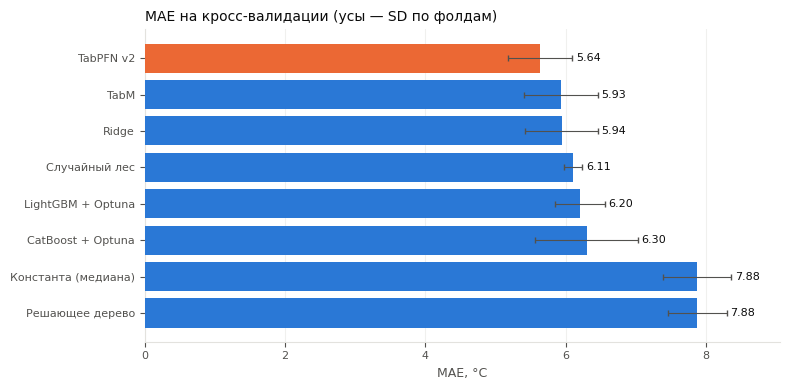

In [34]:
summary = scores_table(list(MODEL_KEYS.values()), labels=list(MODEL_KEYS))
display(summary.round(3))
display(ablation_table(MODEL_KEYS, reference='Ridge').drop(columns=FOLD_COLUMNS).round(3))

fig, ax = plt.subplots(figsize=(8, 4), facecolor='white')
order = sorted(MODEL_KEYS, key=lambda m: SCORES[MODEL_KEYS[m]]['MAE'], reverse=True)
ax.barh(range(len(order)), [SCORES[MODEL_KEYS[m]]['MAE'] for m in order], xerr=[SCORES[MODEL_KEYS[m]]['SD по фолдам'] for m in order],
        color=[ACCENT if m == 'TabPFN v2' else BAR_COLOR for m in order], zorder=3,
        error_kw={'ecolor': INK_SECONDARY, 'capsize': 2, 'linewidth': 0.8})
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=9, color=INK)
for y, m in enumerate(order):
    ax.text(SCORES[MODEL_KEYS[m]]['MAE'] + SCORES[MODEL_KEYS[m]]['SD по фолдам'] + 0.05, y, f"{SCORES[MODEL_KEYS[m]]['MAE']:.2f}",
            va='center', color=INK, fontsize=8)
ax.set_xlim(0, SCORES['Константа (медиана)']['MAE'] * 1.15)
style_axes(ax, 'MAE на кросс-валидации (усы — SD по фолдам)', 'MAE, °C', grid_axis='x')
save_figure(fig, 'models_comparison.png')

Корреляция остатков между моделями на 1450 партиях: от 0.835 до 0.941, среднее 0.883.


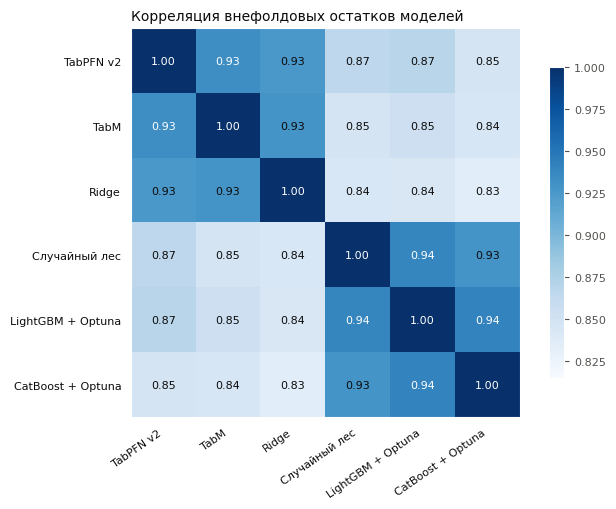

In [35]:
CANDIDATES = {m: k for m, k in MODEL_KEYS.items() if m not in ('Константа (медиана)', 'Решающее дерево')}
RANKING = sorted(CANDIDATES, key=lambda m: SCORES[CANDIDATES[m]]['MAE'])
FOLD_VALID = [valid for _, valid in cv.split(features_train)]
ROWS_OOF = np.concatenate(FOLD_VALID)
y_all = t_last.to_numpy()
P = pd.DataFrame({m: OOF[CANDIDATES[m]].to_numpy() for m in RANKING}, index=features_train.index)

residual_corr = pd.DataFrame({m: y_all[ROWS_OOF] - P[m].to_numpy()[ROWS_OOF] for m in RANKING}).corr()
off_diagonal = residual_corr.to_numpy()[np.triu_indices(len(RANKING), k=1)]
print(f'Корреляция остатков между моделями на {len(ROWS_OOF)} партиях: от {off_diagonal.min():.3f} до {off_diagonal.max():.3f}, '
      f'среднее {off_diagonal.mean():.3f}.')
fig, ax = plt.subplots(figsize=(7, 5.2), facecolor='white')
image = ax.imshow(residual_corr.to_numpy(), cmap='Blues', vmin=off_diagonal.min() - 0.02, vmax=1.0)
ax.set_xticks(range(len(RANKING)))
ax.set_xticklabels(RANKING, rotation=35, ha='right', fontsize=8, color=INK)
ax.set_yticks(range(len(RANKING)))
ax.set_yticklabels(RANKING, fontsize=8, color=INK)
for i in range(len(RANKING)):
    for j in range(len(RANKING)):
        ax.text(j, i, f'{residual_corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if residual_corr.iloc[i, j] > 0.93 else INK)
ax.set_title('Корреляция внефолдовых остатков моделей', loc='left', color=INK, fontsize=10)
fig.colorbar(image, ax=ax, shrink=0.8).ax.tick_params(labelsize=8, colors=INK_SECONDARY)
save_figure(fig, 'models_residual_corr.png')

In [36]:
def caruana_weights(pred_matrix, target, n_iter=30):
    # жадный отбор с возвращением: на каждом шаге добавляется модель, сильнее всего снижающая MAE среднего
    counts, total = np.zeros(pred_matrix.shape[1]), np.zeros(len(target))
    for step in range(1, n_iter + 1):
        best = int(np.argmin([np.mean(np.abs(target - (total + pred_matrix[:, j]) / step)) for j in range(pred_matrix.shape[1])]))
        counts[best] += 1
        total += pred_matrix[:, best]
    return counts / counts.sum()


def fold_maes(pred):
    return np.array([mean_absolute_error(y_all[v], pred[v]) if not np.isnan(pred[v]).any() else np.nan for v in FOLD_VALID])


P_values = P.to_numpy()
blend_preds = {f'Среднее топ-{k}': P[RANKING[:k]].mean(axis=1).to_numpy() for k in (2, 3, 4)}
weighted = np.full(len(y_all), np.nan)
for fold in range(1, N_FOLDS):
    previous = np.concatenate(FOLD_VALID[:fold])
    weighted[FOLD_VALID[fold]] = P_values[FOLD_VALID[fold]] @ caruana_weights(P_values[previous], y_all[previous])
blend_preds['Взвешенный бленд'] = weighted

BEST_SINGLE = min(RANKING, key=lambda m: fold_maes(P[m].to_numpy())[1:].mean())
reference = fold_maes(P[BEST_SINGLE].to_numpy())[1:]
rows = {}
for name, pred in {**{m: P[m].to_numpy() for m in RANKING}, **blend_preds}.items():
    maes = fold_maes(pred)
    diff = maes[1:] - reference
    rows[name] = {'MAE, фолды 2–5': maes[1:].mean(), **dict(zip(FOLD_COLUMNS[1:], maes[1:])),
                  'Δ к лучшей одиночной': diff.mean(), 'фолдов лучше (из 4)': int((diff < 0).sum())}
selection = pd.DataFrame(rows).T.astype({'фолдов лучше (из 4)': int}).sort_values('MAE, фолды 2–5').rename_axis('модель')
display(selection.round(3))
passing = [b for b in blend_preds if selection.loc[b, 'Δ к лучшей одиночной'] <= -0.02 and selection.loc[b, 'фолдов лучше (из 4)'] >= 3]
OFFICIAL = min([BEST_SINGLE] + passing, key=lambda n: selection.loc[n, 'MAE, фолды 2–5'])
print(f'Лучшая одиночная модель: {BEST_SINGLE}; бленды, прошедшие критерий: {passing or "нет"}. Итоговая модель: {OFFICIAL}.')

,"MAE, фолды 2–5",фолд 2,фолд 3,фолд 4,фолд 5,Δ к лучшей одиночной,фолдов лучше (из 4)
модель,,,,,,,
TabPFN v2,5.668,6.277,5.416,5.891,5.086,0.000,0
Среднее топ-4,5.703,6.232,5.501,5.919,5.160,0.035,1
Взвешенный бленд,5.703,6.334,5.453,5.870,5.156,0.036,1
Среднее топ-2,5.714,6.440,5.481,5.864,5.069,0.046,2
Среднее топ-3,5.728,6.393,5.506,5.979,5.035,0.061,1
TabM,5.958,6.765,5.812,5.960,5.295,0.291,0
Ridge,5.976,6.597,5.676,6.321,5.308,0.308,0
CatBoost + Optuna,6.002,6.494,5.793,6.013,5.706,0.334,0
Случайный лес,6.101,6.274,5.988,6.179,5.963,0.434,1


Лучшая одиночная модель: TabPFN v2; бленды, прошедшие критерий: нет. Итоговая модель: TabPFN v2.


**Выводы.** Остатки моделей сильно коррелированы (0.84–0.94, в среднем 0.88): модели ошибаются на одних и тех же партиях, и усреднение почти не снижает ошибку. Ни один бленд не прошёл критерий: лучшие из них (среднее четырёх лучших моделей и взвешенный бленд, 5.70 °C на фолдах 2–5) хуже TabPFN v2 (5.67 °C) и лучше её лишь в одном фолде из четырёх. Итоговая модель — **TabPFN v2** с целью `T_last` на наборе признаков D.

## 9. Проверка на тестовой выборке, анализ ошибок и важность признаков

Итоговая модель обучается на всём train и один раз оценивается на test вместе с константной моделью (медиана train). После этого модель не меняется: анализ ошибок служит для определения границ применимости и рекомендаций.

In [37]:
def build_component(name, cached=False):
    # необученный оценщик с теми же настройками, что на кросс-валидации; прогноз — T_last
    if name in BASE_LABELS.values():
        kind = next(k for k, label in BASE_LABELS.items() if label == name)
        return base_model(kind, MAIN_SET, TARGET_MODE)
    if name == 'TabPFN v2':
        return with_target(make_tree_pipeline(FEATURE_SETS[MAIN_SET], tabpfn_model(**({'fit_mode': 'fit_with_cache'} if cached else {}))),
                           TABPFN_MODE)
    if name == 'TabM':
        return tabm_model(*TABM_CONFIG)
    return with_target(OptunaBooster(BOOSTERS[name], FEATURE_SETS[MAIN_SET], n_trials=BUDGET[BOOSTERS[name]]['final'],
                                     inner_splits=N_FOLDS), TARGET_MODE)


if OFFICIAL in CANDIDATES:
    OFFICIAL_WEIGHTS = {OFFICIAL: 1.0}
elif OFFICIAL.startswith('Среднее топ-'):
    OFFICIAL_WEIGHTS = {m: 1 / int(OFFICIAL.split('-')[1]) for m in RANKING[:int(OFFICIAL.split('-')[1])]}
else:
    OFFICIAL_WEIGHTS = {m: float(w) for m, w in zip(RANKING, caruana_weights(P_values[ROWS_OOF], y_all[ROWS_OOF])) if w > 0}

X_test, y_test = features.loc[test_keys], batches.loc[test_keys, 'T_last']
final_models = {name: build_component(name).fit(features_train, t_last) for name in OFFICIAL_WEIGHTS}
pred_test = sum(w * np.asarray(final_models[name].predict(X_test)) for name, w in OFFICIAL_WEIGHTS.items())
const_test = np.full(len(X_test), float(t_last.median()))
pd.DataFrame({'key': test_keys, 'T_last': y_test.to_numpy(), 'прогноз': pred_test, 'константа': const_test}).to_csv(
    OUTPUT_DIR / 'test_predictions.csv', index=False)

abs_err, abs_err_const = np.abs(pred_test - y_test.to_numpy()), np.abs(const_test - y_test.to_numpy())
rng = np.random.default_rng(RANDOM_STATE)
boot = [rng.integers(0, len(abs_err), len(abs_err)) for _ in range(2000)]
interval = lambda values: '{:.2f} – {:.2f}'.format(*np.percentile(values, [2.5, 97.5]))
test_table = pd.DataFrame({
    'MAE': [abs_err.mean(), abs_err_const.mean()],
    'R²': [r2_score(y_test, pred_test), r2_score(y_test, const_test)],
    '95% интервал MAE (bootstrap)': [interval([abs_err[b].mean() for b in boot]), interval([abs_err_const[b].mean() for b in boot])],
    'MAE на кросс-валидации (фолды 2–5)': [selection.loc[OFFICIAL, 'MAE, фолды 2–5'], np.nan],
}, index=[OFFICIAL, 'Константа (медиана train)']).rename_axis('test')
display(test_table.round(3))
print(f'MAE на test {abs_err.mean():.3f} °C (требование — менее 6.8); выигрыш у константы {abs_err_const.mean() - abs_err.mean():.3f} °C '
      f'(95% интервал {interval([(abs_err_const[b] - abs_err[b]).mean() for b in boot])}).')

,MAE,R²,95% интервал MAE (bootstrap),MAE на кросс-валидации (фолды 2–5)
test,,,,
TabPFN v2,5.627,0.511,5.16 – 6.12,5.668
Константа (медиана train),8.207,-0.012,7.57 – 8.90,NaN


MAE на test 5.627 °C (требование — менее 6.8); выигрыш у константы 2.580 °C (95% интервал 1.99 – 3.15).


Bootstrap-интервал построен по партиям и не учитывает зависимость соседних по времени партий, поэтому он описательный.

### 9.1. Анализ ошибок

Ошибки на test сравниваются с внефолдовыми ошибками той же модели на кросс-валидации (фолды 2–5), чтобы отличить типичные ошибки от изменений между периодами. Группировка по фактической `T_last` сама по себе смещает ошибку в крайних группах (регрессия к среднему), поэтому значения сопоставляются с кросс-валидацией.

In [38]:
errors = pd.DataFrame({'факт': y_test, 'прогноз': pred_test}, index=y_test.index)
errors['ошибка'] = errors['прогноз'] - errors['факт']
errors['|ошибка|'] = errors['ошибка'].abs()
errors = errors.join(batches.loc[test_keys, 'first_time']).join(X_test[['T_first', 'n_heat', 'E_sum', 'dur_sum', 'gas']])
errors['обработка, мин'] = (batches.loc[test_keys, 'last_time'] - batches.loc[test_keys, 'first_time']).dt.total_seconds() / 60
columns_main = FEATURE_SETS[MAIN_SET]
lo, hi = features_train[columns_main].min(), features_train[columns_main].max()
outside = (X_test[columns_main] < lo) | (X_test[columns_main] > hi)
errors['вне диапазона train'] = outside.any(axis=1)

oof_official = sum(w * P[m].to_numpy() for m, w in OFFICIAL_WEIGHTS.items())
cv_rows = np.concatenate(FOLD_VALID[1:])
cv_err = pd.Series(oof_official[cv_rows] - y_all[cv_rows])
quantiles = [0.5, 0.9, 0.99, 1.0]
dist = pd.DataFrame({'test': np.quantile(errors['|ошибка|'], quantiles), 'CV': np.quantile(cv_err.abs(), quantiles)},
                    index=['медиана', '90%', '99%', 'максимум']).rename_axis('|ошибка|, °C')
dist.loc['доля |ошибки| > 10 °C'] = [(errors['|ошибка|'] > 10).mean(), (cv_err.abs() > 10).mean()]
dist.loc['смещение (прогноз − факт)'] = [errors['ошибка'].mean(), cv_err.mean()]
display(dist.round(3))

bins, labels = [-np.inf, 1580, 1600, 1610, 1625, np.inf], ['< 1580', '1580–1600', '1600–1610', '1610–1625', '> 1625']
by_target = lambda y, err, kind: pd.DataFrame({
    f'партий, {kind}': err.groupby(pd.cut(y, bins, labels=labels, right=False), observed=False).size(),
    f'MAE, {kind}': err.abs().groupby(pd.cut(y, bins, labels=labels, right=False), observed=False).mean(),
    f'смещение, {kind}': err.groupby(pd.cut(y, bins, labels=labels, right=False), observed=False).mean()})
display(pd.concat([by_target(errors['факт'], errors['ошибка'], 'test'),
                   by_target(pd.Series(y_all[cv_rows]), cv_err, 'CV')], axis=1).round(2).rename_axis('фактическая T_last, °C'))

errors = errors.sort_values('first_time')
block = pd.qcut(np.arange(len(errors)), 6, labels=[f'блок {k}' for k in range(1, 7)])
by_block = errors.groupby(block, observed=True).agg(начало=('first_time', 'min'), партий=('ошибка', 'size'),
                                                    MAE=('|ошибка|', 'mean'), смещение=('ошибка', 'mean'))
by_block['MAE константы'] = [np.abs(const_test[0] - g['факт']).mean() for _, g in errors.groupby(block, observed=True)]
display(by_block.round({'MAE': 3, 'смещение': 3, 'MAE константы': 3}).rename_axis('хронологический блок test'))
rho, p_value = sps.spearmanr(np.arange(len(errors)), errors['|ошибка|'])
print(f'Корреляция Спирмена |ошибки| с порядком партий по времени: {rho:+.3f} (p = {p_value:.2f}).')

display(errors.groupby('вне диапазона train').agg(партий=('ошибка', 'size'), MAE=('|ошибка|', 'mean'), смещение=('ошибка', 'mean'))
        .rename(index={False: 'все признаки в диапазоне train', True: 'есть признаки вне диапазона'}).round(3))
print(f'Признаков, у которых значения test выходят за диапазон train: {int(outside.any().sum())} из {len(columns_main)}.')
display(errors.sort_values('|ошибка|', ascending=False).head(10)
        [['first_time', 'факт', 'прогноз', 'ошибка', 'T_first', 'n_heat', 'E_sum', 'обработка, мин', 'gas']]
        .round({'прогноз': 1, 'ошибка': 1, 'E_sum': 1, 'обработка, мин': 0, 'gas': 1}).rename_axis('10 наибольших ошибок'))
print(f'Медианы по test: T_first {errors["T_first"].median():.0f} °C, нагревов {errors["n_heat"].median():.0f}, '
      f'обработка {errors["обработка, мин"].median():.0f} мин.')

# смещение: сдвиг всего распределения ошибок или отдельные партии; сравнение уровней train и test
day = errors['first_time'].dt.date == pd.Timestamp('2019-07-27').date()
print(f'Ошибка на test (прогноз − факт): среднее {errors["ошибка"].mean():+.2f} °C, медиана {errors["ошибка"].median():+.2f} °C, '
      f'завышено {(errors["ошибка"] > 0).mean():.0%} прогнозов; без партий 27 июля среднее {errors.loc[~day, "ошибка"].mean():+.2f} °C.')
levels = pd.DataFrame({'train': [features_train['T_first'].mean(), features_train['E_sum'].mean(), t_last.mean()],
                       'test': [X_test['T_first'].mean(), X_test['E_sum'].mean(), y_test.mean()]},
                      index=['T_first', 'E_sum', 'T_last'])
levels['test − train'] = levels['test'] - levels['train']
display(levels.round(1).rename_axis('среднее'))

,test,CV
"|ошибка|, °C",,
медиана,4.097,4.301
90%,12.515,11.959
99%,24.767,23.065
максимум,57.358,39.613
доля |ошибки| > 10 °C,0.160,0.157
смещение (прогноз − факт),1.926,0.068


,"партий, test","MAE, test","смещение, test","партий, CV","MAE, CV","смещение, CV"
"фактическая T_last, °C",,,,,,
< 1580,69,9.81,9.56,103,7.65,7.23
1580–1600,426,4.51,2.37,793,4.40,1.61
1600–1610,37,6.29,-3.08,150,6.83,-4.79
1610–1625,47,8.48,-8.45,108,10.68,-10.21
> 1625,2,20.52,-20.52,6,19.89,-19.89


,начало,партий,MAE,смещение,MAE константы
хронологический блок test,,,,,
блок 1,2019-07-11 17:57:02,97,5.995,2.367,7.948
блок 2,2019-07-22 04:17:33,97,4.879,1.538,7.845
блок 3,2019-07-26 04:00:28,97,7.958,3.726,11.227
блок 4,2019-07-30 01:14:13,96,4.717,1.200,6.500
блок 5,2019-08-02 15:34:37,97,5.492,0.168,8.990
блок 6,2019-08-06 22:02:26,97,4.711,2.548,6.711


Корреляция Спирмена |ошибки| с порядком партий по времени: -0.032 (p = 0.45).


,партий,MAE,смещение
вне диапазона train,,,
все признаки в диапазоне train,559,5.269,1.632
есть признаки вне диапазона,22,14.715,9.382


Признаков, у которых значения test выходят за диапазон train: 13 из 65.


,first_time,факт,прогноз,ошибка,T_first,n_heat,E_sum,"обработка, мин",gas
10 наибольших ошибок,,,,,,,,,
2108,2019-07-27 10:41:03,1541.0,1598.4,57.4,1639.0,16,1761.9,356.0,45.6
2107,2019-07-27 07:53:57,1543.0,1585.8,42.8,1641.0,8,485.1,148.0,29.7
2106,2019-07-27 05:45:43,1545.0,1585.7,40.7,1602.0,8,879.3,127.0,19.5
2110,2019-07-27 19:09:10,1551.0,1585.3,34.3,1645.0,5,216.0,124.0,52.1
2109,2019-07-27 16:37:34,1556.0,1583.5,27.5,1619.0,7,571.9,123.0,17.8
2019,2019-07-24 05:26:20,1596.0,1622.2,26.2,1596.0,8,1008.9,59.0,12.5
2104,2019-07-27 03:08:08,1626.0,1601.6,-24.4,1629.0,8,1122.2,76.0,25.6
1988,2019-07-22 23:03:19,1582.0,1605.7,23.7,1652.0,1,49.5,44.0,7.2
2354,2019-08-05 01:35:13,1591.0,1614.4,23.4,1641.0,6,604.3,60.0,9.6


Медианы по test: T_first 1585 °C, нагревов 4, обработка 34 мин.
Ошибка на test (прогноз − факт): среднее +1.93 °C, медиана +1.25 °C, завышено 61% прогнозов; без партий 27 июля среднее +1.65 °C.


,train,test,test − train
среднее,,,
T_first,1587.4,1587.4,0.0
E_sum,535.8,550.1,14.4
T_last,1593.9,1591.7,-2.2


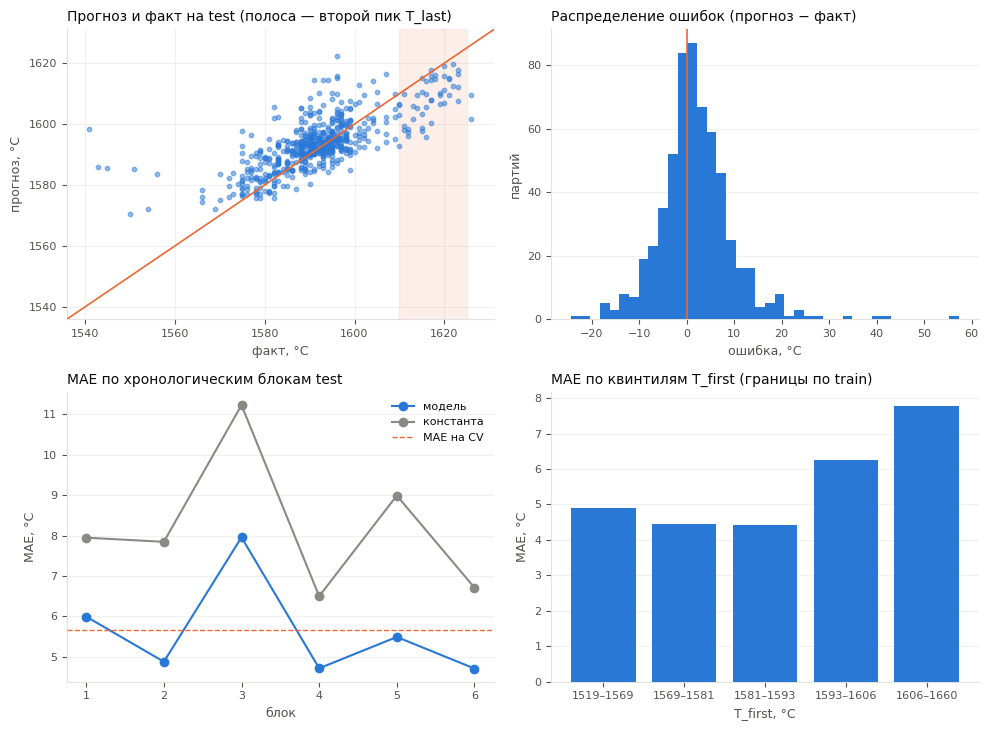

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7.4), facecolor='white')
ax = axes[0, 0]
limits = [min(errors['факт'].min(), errors['прогноз'].min()) - 5, max(errors['факт'].max(), errors['прогноз'].max()) + 5]
ax.scatter(errors['факт'], errors['прогноз'], s=10, alpha=0.5, color=BAR_COLOR, zorder=3)
ax.plot(limits, limits, color=ACCENT, linewidth=1.2, zorder=4)
ax.axvspan(1610, 1625, color=ACCENT, alpha=0.1, zorder=1)
ax.set_xlim(limits)
ax.set_ylim(limits)
style_axes(ax, 'Прогноз и факт на test (полоса — второй пик T_last)', 'факт, °C', 'прогноз, °C', grid_axis='both')
ax = axes[0, 1]
ax.hist(errors['ошибка'], bins=40, color=BAR_COLOR, zorder=3)
ax.axvline(0, color=ACCENT, linewidth=1.2, zorder=4)
style_axes(ax, 'Распределение ошибок (прогноз − факт)', 'ошибка, °C', 'партий')
ax = axes[1, 0]
ax.plot(range(1, 7), by_block['MAE'], marker='o', color=BAR_COLOR, zorder=3, label='модель')
ax.plot(range(1, 7), by_block['MAE константы'], marker='o', color=NEUTRAL, zorder=3, label='константа')
ax.axhline(selection.loc[OFFICIAL, 'MAE, фолды 2–5'], color=ACCENT, linestyle='--', linewidth=1, zorder=4, label='MAE на CV')
ax.set_xticks(range(1, 7))
ax.legend(fontsize=8, labelcolor=INK, frameon=False)
style_axes(ax, 'MAE по хронологическим блокам test', 'блок', 'MAE, °C')
ax = axes[1, 1]
edges = np.quantile(features_train['T_first'], np.linspace(0, 1, 6))
quintile = pd.cut(errors['T_first'], np.r_[-np.inf, edges[1:-1], np.inf])
ax.bar(range(5), errors.groupby(quintile, observed=False)['|ошибка|'].mean(), color=BAR_COLOR, zorder=3)
ax.set_xticks(range(5))
ax.set_xticklabels([f'{a:.0f}–{b:.0f}' for a, b in zip(edges[:-1], edges[1:])], fontsize=8)
style_axes(ax, 'MAE по квинтилям T_first (границы по train)', 'T_first, °C', 'MAE, °C')
save_figure(fig, 'test_errors.png')

### 9.2. Важность признаков

Важность оценивается перестановкой (permutation importance) на последнем проверочном блоке train: модель обучается на фолдах 1–4, затем значения признака (или группы признаков одновременно) перемешиваются между партиями блока 5, и рост MAE показывает вклад признака в прогноз. Перестановка повторяется трижды. Коррелированные признаки делят вклад между собой, поэтому важность сначала оценивается по группам, затем по отдельным признакам самой важной группы. Важность описывает поведение модели, а не причинный эффект. Для ускорения многократных прогнозов TabPFN использует кеш контекста (`fit_mode='fit_with_cache'`).

MAE на блоке 5 без перестановки: 5.086 °C.


,"прирост MAE, °C",SD по повторам,признаков
группа признаков,,,
T_first,6.681,0.599,1
нагрев: энергия и длительность,3.436,0.100,9
хронология нагревов,1.577,0.081,3
сыпучие: по материалам,0.587,0.085,30
проволока: по материалам,0.409,0.083,14
интервалы между нагревами и добавками,0.155,0.020,3
проволока: итоги,0.033,0.029,2
газ,0.022,0.021,1
сыпучие: итоги,-0.023,0.006,2


,"прирост MAE, °C",SD по повторам
признаки группы «T_first»,,
T_first,6.98,0.468


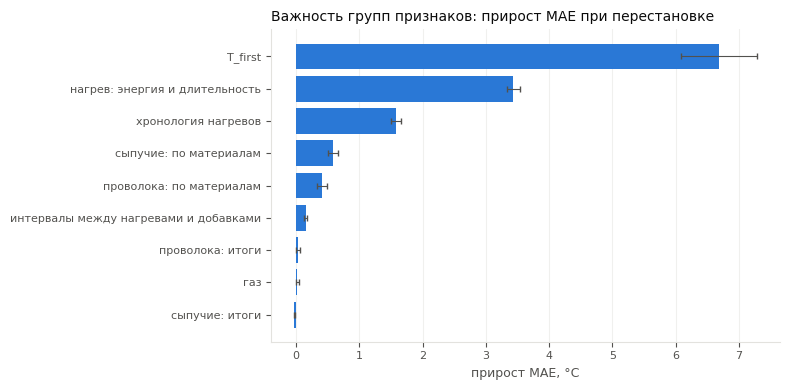

In [40]:
PERM_REPEATS, MAX_INDIVIDUAL = 3, 8
fit_idx, valid_idx = list(cv.split(features_train))[-1]
X_fit, y_fit = features_train.iloc[fit_idx], t_last.iloc[fit_idx]
X_val, y_val = features_train.iloc[valid_idx], t_last.iloc[valid_idx]
importance_models = {name: build_component(name, cached=True).fit(X_fit, y_fit) for name in OFFICIAL_WEIGHTS}
official_predict = lambda X: sum(w * np.asarray(importance_models[n].predict(X)) for n, w in OFFICIAL_WEIGHTS.items())
base_mae = mean_absolute_error(y_val, official_predict(X_val))

GROUPS = {
    'T_first': ['T_first'],
    'нагрев: энергия и длительность': ['n_heat', 'dur_sum', 'ES_sum', 'ratio_PQ', 'E_sum', 'E_max', 'dur_max', 'cosphi_w', 'P_mean_w'],
    'хронология нагревов': ['pause_sum', 'arc_span', 'duty'],
    'интервалы между нагревами и добавками': ['t_first_add', 'add_span', 't_last_add_vs_heat_end'],
    'газ': ['gas'],
    'сыпучие: итоги': ['bulk_total', 'bulk_n'],
    'проволока: итоги': ['wire_total', 'wire_n'],
    'сыпучие: по материалам': [c for c in MATERIAL_COLUMNS if c.startswith(('Bulk_', 'was_added_Bulk_'))],
    'проволока: по материалам': [c for c in MATERIAL_COLUMNS if c.startswith(('Wire_', 'was_added_Wire_'))],
}


def permutation_gain(columns, seed):
    rng = np.random.default_rng(seed)
    gains = []
    for _ in range(PERM_REPEATS):
        X_perm = X_val.copy()
        X_perm[columns] = X_val[columns].to_numpy()[rng.permutation(len(X_val))]
        gains.append(mean_absolute_error(y_val, official_predict(X_perm)) - base_mae)
    return np.mean(gains), np.std(gains, ddof=1)


group_importance = pd.DataFrame({g: permutation_gain(cols, RANDOM_STATE + k) for k, (g, cols) in enumerate(GROUPS.items())},
                                index=['прирост MAE, °C', 'SD по повторам']).T.sort_values('прирост MAE, °C', ascending=False)
group_importance['признаков'] = [len(GROUPS[g]) for g in group_importance.index]
print(f'MAE на блоке 5 без перестановки: {base_mae:.3f} °C.')
display(group_importance.round(3).rename_axis('группа признаков'))

TOP_GROUP = group_importance.index[0]
top_columns = sorted(GROUPS[TOP_GROUP], key=lambda c: -abs(sps.spearmanr(X_fit[c], y_fit)[0]))[:MAX_INDIVIDUAL]
feature_importance = pd.DataFrame({c: permutation_gain([c], RANDOM_STATE + 100 + k) for k, c in enumerate(top_columns)},
                                  index=['прирост MAE, °C', 'SD по повторам']).T.sort_values('прирост MAE, °C', ascending=False)
display(feature_importance.round(3).rename_axis(f'признаки группы «{TOP_GROUP}»'))
TOP_FEATURE = feature_importance.index[0]

fig, ax = plt.subplots(figsize=(8, 4), facecolor='white')
table = group_importance.iloc[::-1]
ax.barh(range(len(table)), table['прирост MAE, °C'], xerr=table['SD по повторам'], color=BAR_COLOR, zorder=3,
        error_kw={'ecolor': INK_SECONDARY, 'capsize': 2, 'linewidth': 0.8})
ax.set_yticks(range(len(table)))
ax.set_yticklabels(table.index, fontsize=8, color=INK)
style_axes(ax, 'Важность групп признаков: прирост MAE при перестановке', 'прирост MAE, °C', grid_axis='x')
save_figure(fig, 'feature_importance.png')

### 9.3. Зависимость целевой переменной от самого важного признака

Слева — наблюдаемая связь признака с `T_last` на train (средние по децилям признака ± стандартная ошибка). Справа — частичная зависимость (partial dependence) итоговой модели на блоке 5: средний прогноз при подстановке одного значения признака во все партии. При подстановке остальные признаки не меняются, поэтому возникают сочетания, которых в данных почти нет, и наклон частичной зависимости нельзя читать как физический эффект.

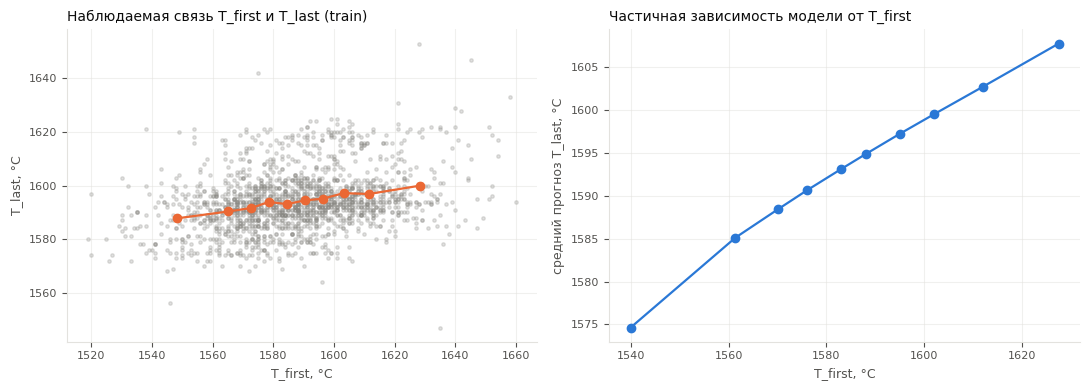

Наклон: наблюдаемый 0.15, частичной зависимости 0.37 °C на °C.


In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), facecolor='white')
ax = axes[0]
ax.scatter(features_train[TOP_FEATURE], t_last, s=6, alpha=0.25, color=NEUTRAL, zorder=2)
deciles = pd.qcut(features_train[TOP_FEATURE], 10, duplicates='drop')
observed = t_last.groupby(deciles, observed=True).agg(['mean', 'sem'])
ax.errorbar(features_train[TOP_FEATURE].groupby(deciles, observed=True).mean(), observed['mean'], yerr=observed['sem'],
            marker='o', color=ACCENT, linewidth=1.6, capsize=2, zorder=4)
style_axes(ax, f'Наблюдаемая связь {TOP_FEATURE} и T_last (train)', f'{TOP_FEATURE}, °C', 'T_last, °C', grid_axis='both')

ax = axes[1]
grid_values = np.unique(np.quantile(X_val[TOP_FEATURE], np.linspace(0.05, 0.95, 10)))
dependence = [official_predict(X_val.assign(**{TOP_FEATURE: value})).mean() for value in grid_values]
ax.plot(grid_values, dependence, marker='o', color=BAR_COLOR, linewidth=1.6, zorder=3)
style_axes(ax, f'Частичная зависимость модели от {TOP_FEATURE}', f'{TOP_FEATURE}, °C', 'средний прогноз T_last, °C', grid_axis='both')
save_figure(fig, 'feature_dependence.png')
slope = lambda x, y: np.polyfit(np.asarray(x, dtype=float), np.asarray(y, dtype=float), 1)[0]
print(f'Наклон: наблюдаемый {slope(features_train[TOP_FEATURE].groupby(deciles, observed=True).mean(), observed["mean"]):.2f}, '
      f'частичной зависимости {slope(grid_values, dependence):.2f} °C на °C.')

### 9.4. Интервалы прогноза и допуск датчика температуры

TabPFN оценивает не только точечный прогноз, но и распределение возможных значений `T_last`; его квантили 5% и 95% задают 90%-й интервал прогноза для каждой партии. Интервал полезен, если выполнены два условия: факт попадает в него примерно в 90% случаев, а ширина интервала отделяет партии с большой ошибкой. Большой здесь считается ошибка, превышающая допуск термопары: для термопар типов S и B класса 2 по IEC 60584-1 допуск при 1600 °C составляет ±0.25%·t ≈ ±4 °C (для типа S класса 1 — ±2.5 °C; тип и класс датчика в данных не указаны). Интервалы строятся по тем же фолдам кросс-валидации, что и в разделе 8; границы групп по ширине и пороги для ручного замера задаются по кросс-валидации и затем проверяются на test. Порог для ручного замера — перцентиль полуширины интервала на кросс-валидации, соответствующий доле замеряемых партий: например, при замере 30% партий это 70-й перцентиль.

In [42]:
TOLERANCE = 4.0           # допуск термопар типов S и B класса 2 по IEC 60584-1 при 1600 °C, °C
QUANTILES = [0.05, 0.95]  # границы 90%-го интервала прогноза


def interval_frame(model, X, y):
    # прогноз, границы интервала, полуширина и ошибка для каждой партии
    out = model.predict(X, output_type='main', quantiles=QUANTILES)
    frame = pd.DataFrame({'факт': np.asarray(y), 'прогноз': out['mean'], 'нижняя': out['quantiles'][0], 'верхняя': out['quantiles'][1]})
    frame['полуширина'] = (frame['верхняя'] - frame['нижняя']) / 2
    frame['|ошибка|'] = (frame['прогноз'] - frame['факт']).abs()
    frame['в интервале'] = frame['факт'].between(frame['нижняя'], frame['верхняя'])
    return frame


start = time.time()
cv_interval = pd.concat([
    interval_frame(make_tree_pipeline(FEATURE_SETS[MAIN_SET], tabpfn_model()).fit(features_train.iloc[fit_idx], t_last.iloc[fit_idx]),
                   features_train.iloc[valid_idx], t_last.iloc[valid_idx])
    for fit_idx, valid_idx in cv.split(features_train)])
test_interval = interval_frame(final_models['TabPFN v2'], X_test, y_test)

# группы по ширине интервала: границы — квартили полуширины на кросс-валидации
edges = np.r_[-np.inf, np.quantile(cv_interval['полуширина'], [0.25, 0.5, 0.75]), np.inf]
labels = ['1 (самые узкие)', '2', '3', '4 (самые широкие)']


def by_width(frame):
    groups = pd.cut(frame['полуширина'], edges, labels=labels)
    table = frame.groupby(groups, observed=True).agg(партий=('факт', 'size'), полуширина=('полуширина', 'mean'), MAE=('|ошибка|', 'mean'),
                                                     покрытие=('в интервале', 'mean'))
    table[f'доля |ошибки| > {TOLERANCE:.0f} °C'] = (frame['|ошибка|'] > TOLERANCE).groupby(groups, observed=True).mean()
    table.loc['все'] = [len(frame), frame['полуширина'].mean(), frame['|ошибка|'].mean(), frame['в интервале'].mean(),
                        (frame['|ошибка|'] > TOLERANCE).mean()]
    return table.astype({'партий': int})


display(pd.concat({'кросс-валидация': by_width(cv_interval), 'test': by_width(test_interval)}, axis=1).round(3)
        .rename_axis('четверть по ширине интервала'))

# правило «полуширина интервала больше порога → ручной замер»: доля замеров и доля пойманных превышений допуска
rows = {}
for share in [0.2, 0.3, 0.5]:
    threshold = np.quantile(cv_interval['полуширина'], 1 - share)
    row = {'порог полуширины, °C': threshold}
    for name, frame in [('CV', cv_interval), ('test', test_interval)]:
        flagged, exceeded = frame['полуширина'] > threshold, frame['|ошибка|'] > TOLERANCE
        row[f'замеров, {name}'] = flagged.mean()
        row[f'отмечено превышений допуска, {name}'] = flagged[exceeded].mean()
        row[f'MAE без замера, {name}'] = frame.loc[~flagged, '|ошибка|'].mean()
    rows[f'замер у {share:.0%} партий'] = row
display(pd.DataFrame(rows).T.round(3).rename_axis('правило'))
print(f'Партий, у которых весь 90%-й интервал укладывается в допуск ±{TOLERANCE:.0f} °C: '
      f'CV {(cv_interval["полуширина"] <= TOLERANCE).sum()}, test {(test_interval["полуширина"] <= TOLERANCE).sum()}. '
      f'Время расчёта интервалов: {time.time() - start:.0f} с.')

кросс-валидация                                                   test                                                
                                      партий полуширина    MAE покрытие доля |ошибки| > 4 °C партий полуширина    MAE покрытие доля |ошибки| > 4 °C
четверть по ширине интервала                                                                                                                       
1 (самые узкие)                          363      7.379  3.436    0.898                0.342    166      7.541  2.989    0.928                0.277
2                                        362      9.403  4.501    0.909                0.450    115      9.310  4.013    0.957                0.435
3                                        362     11.766  5.969    0.859                0.583    141     11.939  5.628    0.901                0.589
4 (самые широкие)                        363     15.887  8.635    0.882                0.749    159     18.043  9.548    0.881                0.736
все                                     1450     11.110  5.636    0.887                0.531    581     11.833  5.627    0.914                0.509

,"порог полуширины, °C","замеров, CV","отмечено превышений допуска, CV","MAE без замера, CV","замеров, test","отмечено превышений допуска, test","MAE без замера, test"
правило,,,,,,,
замер у 20% партий,14.461,0.2,0.299,4.736,0.203,0.297,4.398
замер у 30% партий,12.791,0.3,0.417,4.500,0.343,0.470,3.932
замер у 50% партий,10.285,0.5,0.627,3.968,0.516,0.676,3.408


Партий, у которых весь 90%-й интервал укладывается в допуск ±4 °C: CV 0, test 0. Время расчёта интервалов: 427 с.


### Выводы по проверке на test

- **Требование выполнено.** MAE TabPFN v2 на test — **5.63 °C** (требование — менее 6.8 °C), R² 0.51; bootstrap-интервал MAE 5.16–6.12 °C целиком ниже порога. Константная модель даёт 8.21 °C (R² −0.01), выигрыш модели — 2.58 °C (31%). MAE на test близка к оценке на кросс-валидации по фолдам 2–5 (5.67 °C).
- **Средняя ошибка скрывает неоднородность.** Для половины партий ошибка не больше 4.1 °C, но у 16% партий она превышает 10 °C.
- **Смещение на test.** Прогноз в среднем завышен на 1.9 °C (на кросс-валидации смещения нет). Сдвинуто всё распределение ошибок, а не отдельные партии: медиана ошибки +1.2 °C, завышено 61% прогнозов, завышение наблюдается во всех хронологических блоках и сохраняется без партий 27 июля (+1.6 °C). Средняя `T_first` в train и test одинакова, энергии нагрева в test подведено в среднем больше, а `T_last` ниже на 2.2 °C: при тех же входах партии test заканчиваются холоднее. Признаки этот сдвиг не объясняют; его причина (состояние ковшей, марки стали, потери тепла) по данным не установлена.
- **Крайние значения сглаживаются.** Партии с `T_last` ниже 1580 °C завышаются в среднем на 9.6 °C, партии второго пика (1610–1625 °C, 8% партий test) занижаются на 8.4 °C; на кросс-валидации картина та же. Модель тяготеет к центру распределения; это согласуется с отсутствием в данных явного признака целевого температурного режима партии.
- **Экстраполяция.** У 22 партий test (3.8%) хотя бы один признак выходит за диапазон train; их MAE 14.7 °C против 5.3 °C у остальных. Это довод в пользу контроля диапазона входов при эксплуатации.
- **Интервалы прогноза и допуск датчика.** 90%-е интервалы TabPFN согласуются с номиналом: факт попадает в интервал у 89% партий на кросс-валидации и у 91% на test. Средняя полуширина интервала ±11–12 °C; ни у одной партии интервал не укладывается в допуск термопары ±4 °C, а ошибка превышает этот допуск примерно у половины партий (53% на кросс-валидации, 51% на test). Ширина интервала отделяет ненадёжные прогнозы: среди 25% самых узких интервалов допуск превышен у 34% партий кросс-валидации (28% test), среди 25% самых широких — у 75% (74% test). Отсюда правило: партии с самыми широкими интервалами направлять на ручной замер. Порог полуширины задаётся долей партий, которые технологи готовы замерять, и равен соответствующему перцентилю полуширины на кросс-валидации. Например, если замерять 30% партий, порог — 70-й перцентиль, 12.8 °C; такое правило отмечает 42% превышений допуска на кросс-валидации (47% на test), а MAE остальных партий — 4.5 °C (3.9 °C на test). Выбор доли — решение заказчика: оно зависит от стоимости замера и риска ошибки. Точности термопары модель не достигает; интервал позволяет выбрать партии, где замер нужнее всего.
- **Локальный эпизод.** Шесть из десяти наибольших ошибок приходятся на 27 июля: партии 2106–2110 с фактической температурой 1541–1556 °C (прогноз 1583–1598 °C) и партия 2104 с ошибкой противоположного знака. Хронологический блок, содержащий этот день, даёт MAE 8.0 °C против 4.7–6.0 °C в остальных. Монотонной связи ошибки со временем нет (ρ = −0.03), что не исключает локальных изменений режима. Партии 2104–2110 нетипичны по нескольким признакам сразу: начальная температура 1602–1645 °C (медиана test 1585 °C), 5–16 нагревов (медиана 4), обработка от 1 до 6 ч (медиана 34 мин); партии 2106–2110 к контрольному замеру остыли на 57–98 °C относительно первого. У партии 2108 16 нагревов — больше максимума train. Такое сочетание похоже на нарушение ритма производства (длительное ожидание горячих партий), но данных для проверки этого нет.
- **Важность признаков.** Наибольший вклад вносит `T_first` (перестановка увеличивает MAE на 6.7 °C), далее энергия и длительность нагрева (3.4 °C) и хронология нагревов (1.6 °C); материалы по видам дают 0.4–0.6 °C, итоговые объёмы и газ — практически ноль. Это согласуется с тепловым балансом, в котором конечная температура зависит от начальной температуры и подведённой энергии.
- **Зависимость от `T_first`.** Наблюдаемая конечная температура растёт с начальной медленно (около 0.15 °C на °C): обработка компенсирует различия начального состояния. У частичной зависимости модели наклон больше (около 0.37 °C на °C), поскольку при подстановке `T_first` энергия нагрева не меняется, а в реальном процессе холодные партии греют дольше.

## 10. Общий вывод и рекомендации

### 10.1. Результаты

Построен виртуальный датчик температуры последнего замера партии. Лучшая модель — TabPFN v2 на 65 признаках, описывающих начальную температуру и выполненную обработку. **MAE на тестовой выборке — 5.63 °C** при требовании менее 6.8 °C; R² 0.51; константная модель даёт 8.21 °C.

| Шаг | Результат |
|---|---|
| Данные | из 3 216 партий в анализе 2 324 с завершённым циклом измерений; train — 1 743 партии (3 мая – 11 июля 2019), test — 581 (11 июля – 10 августа) |
| Признаки | 65 признаков в вложенных наборах A (8) → D (65); каждое расширение снижает ошибку, от A к D — на 0.71 °C у `Ridge` |
| Модели на кросс-валидации | TabPFN v2 5.64 °C; TabM 5.93; `Ridge` 5.94; случайный лес 6.11; LightGBM 6.20; CatBoost 6.30; константа 7.88 |
| Бленды | ошибки моделей сильно коррелированы (0.84–0.94), усреднение не улучшило лучшую модель |
| Test | MAE 5.63 °C (bootstrap-интервал 5.16–6.12) при оценке 5.67 °C на кросс-валидации |

Основные закономерности:

- **Наибольший вклад в прогноз дают начальная температура и характеристики нагрева;** вклад материалов, газа и интервалов между операциями мал. Связь энергии с конечной температурой отчётливо проявляется только при учёте начальной температуры, что согласуется с тем, что холодные партии получают больше энергии.
- **Сложные модели дают ограниченный выигрыш.** Линейная модель на построенных признаках уступает лучшей модели 0.3 °C и опережает бустинги, что согласуется с близкой к линейной зависимостью на этих признаках.
- **Точность неоднородна.** У 16% партий ошибка превышает 10 °C. Партии с нетипично низкой конечной температурой (ниже 1580 °C) завышаются, партии второго пика (1610–1625 °C) занижаются, а партии с признаками вне диапазона обучения оцениваются с MAE 14.7 °C. На test прогноз систематически завышен на 1.9 °C: при той же начальной температуре партии test заканчиваются в среднем на 2.2 °C холоднее, чем партии train. Отдельно выделяется эпизод 27 июля — нехарактерно долгая обработка горячих партий. Причины обоих эффектов по данным не установлены.
- **Точности термопары модель не достигает, но указывает, где замер нужнее.** Ошибка превышает допуск термопары ±4 °C (IEC 60584-1) примерно у половины партий. 90%-й интервал прогноза TabPFN откалиброван (покрытие 91% на test), и его ширина отделяет ненадёжные прогнозы: если направлять на ручной замер 30% партий с самыми широкими интервалами, отмечается около 45% превышений допуска, а MAE остальных партий снижается до 3.9–4.5 °C.

### 10.2. Ограничения

| Ограничение | Содержание |
|---|---|
| Популяция | модель построена по партиям с завершённым циклом измерений; партии без конечной температуры или без записи в одной из таблиц операций исключены |
| Момент прогноза | прогноз строится после завершения операций партии и до контрольного замера; для прогноза в начале обработки модель не предназначена |
| Замкнутый контур | режим нагрева и добавок оператор выбирал по промежуточным замерам, поэтому признаки косвенно несут информацию из этих замеров. Если замеры сократить или использовать модель для подбора режима («что будет, если»), поведение операторов и распределение признаков изменятся, и точность, измеренная на исторических данных, может не сохраниться |
| Один период | данные охватывают май–август 2019 года, test — 30 дней; устойчивость к смене сезона, режима и марки стали не проверена |
| Состояние оборудования | в данных нет сведений о ковшах, износе футеровки, ремонтах и замене оборудования (электродов, трансформатора, датчиков температуры). Такие события могут сдвинуть связь входов с конечной температурой; смещение прогноза на test (подраздел 9.1) может быть их следствием, но проверить это по данным нельзя |
| Синхронность часов | интервалы между событиями разных журналов зависят от согласованности часов датчиков |
| Интерпретация | важность признаков и частичная зависимость описывают поведение модели, а не причинные эффекты |

### 10.3. Способы улучшения

1. **Дополнительные данные** — масса металла в ковше, марка стали, номер ковша и состояние футеровки, журнал ремонтов и замен оборудования, уставки мощности, моменты начала и окончания продувки, результаты химического анализа, погрешность датчика температуры. Масса и состояние ковша прямо входят в тепловой баланс, поэтому это наиболее значимое направление для дальнейшего исследования.
2. **Гибридная модель** — при появлении данных о массе металла и состоянии ковша (пункт 1): физический тепловой баланс с поправкой, обученной на данных (grey-box). Без этих данных баланс сводится к линейной зависимости от энергии и начальной температуры, которую модель и так учитывает.
3. **Правило ручного замера** — порог ширины интервала (подраздел 9.4) выбрать по соотношению стоимости замера и риска ошибки и проверить его вместе с признаком выхода за диапазон обучения в теневом режиме.
4. **Асимметричная функция потерь**, если цена недогрева и перегрева различна: модель систематически сглаживает крайние значения температуры.
5. **Разбор с технологами** сдвига конечной температуры в test, эпизода 27 июля и партий второго пика — возможно, это отдельные режимы или изменения оборудования, которые можно описать признаками.

### 10.4. Рекомендации заказчику

1. **Начать с теневого режима.** Модель рассчитывает прогноз для новых партий параллельно с замерами и не влияет на процесс, пока на нескольких неделях новых данных не подтвердится уровень ошибки, сопоставимый с test (MAE около 5.6 °C, доля ошибок больше 10 °C около 16%).
2. **Сопровождать прогноз интервалом и признаком достоверности.** Для каждой партии выдавать 90%-й интервал прогноза; партии с широким интервалом (подраздел 9.4) или с признаками вне диапазона обучения направлять на ручной замер. Порог ширины интервала определяется долей партий, которые технологи готовы замерять.
3. **Использовать модель для имитации процесса с осторожностью.** Оценка «что будет при другом режиме» опирается на зависимости, полученные при текущей практике управления (ограничение замкнутого контура). Для цифрового двойника установки (digital twin) нужна модель, проверенная на данных с изменёнными режимами, — например, гибридная модель из п. 10.3 и план экспериментов, согласованный с технологами.
4. **Не пересчитывать точность в экономию электроэнергии напрямую.** Для оценки экономии нужны данные о расходе энергии, допусках процесса и стоимости перегрева и недогрева.
5. **Собирать недостающие данные** (п. 10.3, пункт 1) и синхронизировать часы журналов нагрева и подачи материалов.
6. **Выбор модели для эксплуатации.** TabPFN v2 точнее, но хранит обучающую выборку как контекст и требует около 0.18 с на партию при пакетном прогнозе на CPU; веса распространяются по лицензии Prior Labs License 1.1 (Apache 2.0 с дополнительным требованием указания авторства). Если важнее простота, `Ridge` уступает ей 0.3 °C на кросс-валидации; на test эта модель не оценивалась, и её точность нужно подтвердить тем же теневым режимом.
7. **Переобучать модель по мере накопления данных и после ремонтов или замены оборудования**, отслеживать дрейф ошибки; частоту переобучения определить по результатам теневого режима.

## 11. Дополнительно: пошаговая оценка температуры между замерами

Основная модель — виртуальный датчик **конечной** температуры: по начальной температуре и всем операциям партии она сразу оценивает последний замер, пропуская все промежуточные (прямая стратегия на весь горизонт). Здесь рассматривается **пошаговая** постановка того же датчика: оценка температуры следующего замера по последнему фактическому замеру и операциям, выполненным после него. Она отвечает на практический вопрос, можно ли пропускать отдельные промежуточные замеры. Постановка использует промежуточные температуры, поэтому рассматривается отдельно.

**Сегмент** — интервал между соседними замерами k и k + 1 одной партии; между ними всегда ровно один нагрев. Датчик оценивает `T_next` по `T_now` и признакам сегмента: длительности интервала `dt`, номеру замера `k`, времени от первого замера, предыдущему изменению температуры, энергии предыдущих нагревов партии, `T_first`, числу, длительности и энергии нагревов сегмента, объёму и числу добавок. Газ не используется: время продувки не записано. Цель модели — приращение `T_next − T_now`.

**Момент оценки** — после выполнения операций сегмента, непосредственно перед очередным замером: длительность интервала и выполненные операции к этому моменту известны. Проверяется одношаговая оценка, когда `T_now` — реальный замер. Замена нескольких замеров подряд, при которой оценка подставляется вместо замера на следующем шаге и ошибка накапливается, на исторических данных содержательно не проверяется: операции в данных выбраны по фактическим замерам (ограничение замкнутого контура, п. 10.2).

**Схема оценки.** Модель — TabPFN v2 с теми же настройками, что в основной задаче (обучающая часть — до 6 800 сегментов; порог числа строк для CPU поднят до 10 000, предела предобучения версии 2). Ориентиры — оценка «без изменений» (`T_next = T_now`) и `Ridge` (`alpha` подбирается вложенной кросс-валидацией по партиям). Кросс-валидация использует те же пять блоков партий train, что и раздел 8; сегменты одной партии всегда попадают в одну часть. Критерий превосходства над оценкой «без изменений» задан заранее: средняя MAE ниже не менее чем на 0.5 °C и не менее чем в четырёх фолдах из пяти. Затем схема фиксируется и один раз проверяется на сегментах партий test, которые основная модель не использовала (из них берутся только первый и последний замеры). На test, как и в основной задаче, оцениваются только выбранная модель и простейший ориентир — оценка «без изменений»; `Ridge` служит ориентиром на кросс-валидации.

**Надёжность.** Допуск заказчика на ошибку температуры неизвестен, поэтому надёжность описывается долями оценок с ошибкой не больше 3, 5 и 10 °C, ошибкой по номеру сегмента, горизонту и энергии нагрева и эмпирическими прогнозными интервалами с номинальным покрытием 90%. Полуширина интервала для каждого фолда — квантиль модуля внефолдовых остатков предыдущих фолдов. Это не стандартное разделённое конформное предсказание (split conformal prediction): там остатки для калибровки даёт та же модель, что затем применяется, а здесь — модели, обученные на более коротких окнах, поэтому теоретическая гарантия покрытия не установлена.

In [43]:
OPERATION_COLUMNS = ['n_heat', 'dur', 'E', 'ES', 'bulk_total', 'n_bulk', 'wire_total', 'n_wire']
SEG_FEATURES = ['T_now', 'dt', 'k', 'is_first', 'elapsed', 'dT_prev', 'E_before', 'T_first'] + OPERATION_COLUMNS


def assign_segment(events, meas):
    """Номер сегмента события: последний замер партии не позже момента события (события после последнего замера отбрасываются)."""
    merged = pd.merge_asof(events.sort_values('time'), meas[['key', 'MeasureTime', 'k']].sort_values('MeasureTime'),
                           left_on='time', right_on='MeasureTime', by='key', direction='backward')
    return merged.dropna(subset=['k']).astype({'k': int})


def long_additions(volumes, times, keys):
    """Добавки партий `keys` в длинном виде: партия, момент, объём (только фактические добавки)."""
    present = volumes[volumes['key'].isin(keys)]['key']
    v = volumes.set_index('key').loc[present].stack().rename('volume')
    t = times.set_index('key').loc[present].stack().rename('time')
    return pd.concat([v, t], axis=1).dropna().query('volume > 0').reset_index(names=['key', 'material'])


def build_segments(keys):
    """Таблица сегментов партий `keys` (в хронологическом порядке): входы датчика SEG_FEATURES и цель dT = T_next − T_now."""
    meas = (raw['data_temp'][raw['data_temp']['key'].isin(keys)].dropna(subset=['Temperature'])
            .sort_values(['key', 'MeasureTime']).reset_index(drop=True))
    meas['k'] = meas.groupby('key').cumcount()
    table = meas.merge(meas.assign(k=meas['k'] - 1), on=['key', 'k'], suffixes=('_a', '_b'))
    table = table.rename(columns={'MeasureTime_a': 'time_a', 'MeasureTime_b': 'time_b', 'Temperature_a': 'T_now', 'Temperature_b': 'T_next'})
    table['dt'] = (table['time_b'] - table['time_a']).dt.total_seconds()

    heat_events = arc_rows.loc[arc_rows['key'].isin(keys), ['key', 'BeginHeat', 'dur', 'E', 'ES']].rename(columns={'BeginHeat': 'time'})
    heat_seg = assign_segment(heat_events, meas).groupby(['key', 'k']).agg(n_heat=('dur', 'size'), dur=('dur', 'sum'),
                                                                         E=('E', 'sum'), ES=('ES', 'sum'))
    bulk_seg = assign_segment(long_additions(raw['data_bulk'], raw['data_bulk_time'], keys), meas).groupby(['key', 'k']).agg(
        bulk_total=('volume', 'sum'), n_bulk=('volume', 'size'))
    wire_seg = assign_segment(long_additions(raw['data_wire'], raw['data_wire_time'], keys), meas).groupby(['key', 'k']).agg(
        wire_total=('volume', 'sum'), n_wire=('volume', 'size'))
    table = table.join(heat_seg, on=['key', 'k']).join(bulk_seg, on=['key', 'k']).join(wire_seg, on=['key', 'k'])
    table[OPERATION_COLUMNS] = table[OPERATION_COLUMNS].fillna(0)

    order = {key: i for i, key in enumerate(keys)}                               # хронологический порядок партий
    table = table.assign(order=table['key'].map(order)).sort_values(['order', 'k']).reset_index(drop=True)
    by_batch = table.groupby('key')
    table['E_before'] = by_batch['E'].cumsum() - table['E']                       # энергия предыдущих сегментов партии
    table['elapsed'] = (table['time_a'] - by_batch['time_a'].transform('min')).dt.total_seconds()
    table['is_first'] = (table['k'] == 0).astype(int)
    table['dT_prev'] = by_batch['T_now'].diff().fillna(0)                         # T_k − T_{k−1}; для k = 0 заполнено нулём (есть индикатор is_first)
    table['T_first'] = by_batch['T_now'].transform('first')
    table['dT'] = table['T_next'] - table['T_now']
    return table


def describe_segments(table, label):
    """Число партий и сегментов, доли сегментов с нагревом и добавками."""
    counts = table.groupby('key').size()
    print(f'{label}: партий {table["key"].nunique()}, сегментов {len(table)} (на партию: медиана {counts.median():.0f}, '
          f'от {counts.min()} до {counts.max()}); сегментов с нагревом: {(table["n_heat"] > 0).mean():.1%}, '
          f'с сыпучими: {(table["n_bulk"] > 0).mean():.1%}, с проволокой: {(table["n_wire"] > 0).mean():.1%}.')


seg = build_segments(list(features_train.index))
describe_segments(seg, 'Train')
display(seg[['dt', 'dT', 'E', 'dur', 'T_now']].describe().round(1).T.rename_axis('сегменты train'))

Train: партий 1743, сегментов 8183 (на партию: медиана 5, от 1 до 15); сегментов с нагревом: 100.0%, с сыпучими: 64.7%, с проволокой: 29.1%.


,count,mean,std,min,25%,50%,75%,max
сегменты train,,,,,,,,
dt,8183.0,487.7,420.4,79.0,299.0,399.0,551.5,14785.0
dT,8183.0,1.4,11.6,-96.0,-5.0,1.0,8.0,51.0
E,8183.0,114.1,81.6,5.3,57.4,93.3,146.5,885.3
dur,8183.0,171.2,96.9,11.0,106.0,146.0,216.0,907.0
T_now,8183.0,1588.9,16.7,1519.0,1579.0,1589.0,1599.0,1662.0


In [44]:
fold_keys = [(features_train.index[fit].to_numpy(), features_train.index[valid].to_numpy()) for fit, valid in cv.split(features_train)]
fold_rows = [(np.flatnonzero(seg['key'].isin(fit)), np.flatnonzero(seg['key'].isin(valid))) for fit, valid in fold_keys]


class BatchTimeSeriesSplit:
    """TimeSeriesSplit по партиям: блоки строятся по хронологически упорядоченным партиям, затем переводятся в строки сегментов,
    поэтому сегменты одной партии не попадают одновременно в обучающую и проверочную части. Партии — аргумент groups."""

    def __init__(self, n_splits=3):
        self.n_splits = n_splits

    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits

    def split(self, X, y=None, groups=None):
        groups = np.asarray(groups)
        batches = pd.unique(groups)                                              # строки уже упорядочены по времени партий
        for fit_batches, valid_batches in TimeSeriesSplit(self.n_splits).split(batches):
            yield np.flatnonzero(np.isin(groups, batches[fit_batches])), np.flatnonzero(np.isin(groups, batches[valid_batches]))


def fit_segment_model(name, model, rows):
    # для Ridge передаются партии: вложенная кросс-валидация делит данные по партиям
    groups = {'groups': seg.loc[rows, 'key'].to_numpy()} if name == 'Ridge' else {}
    return clone(model).fit(seg.loc[rows, SEG_FEATURES], seg.loc[rows, 'dT'], **groups)


def seg_tabpfn():
    # настройки основной модели; порог числа строк для CPU поднят до 10 000 (обучающая часть — до 6 800 сегментов)
    return TabPFNRegressor.create_default_for_version(ModelVersion.V2, model_path=str(TABPFN_PATH), device='cpu', n_estimators=8,
                                                      random_state=RANDOM_STATE, inference_config={'MAX_CPU_SAMPLES': 10000})


SEG_MODEL = 'TabPFN v2'
SEG_MODELS = {
    'Без изменений (T_next = T_now)': None,
    'Ridge': GridSearchCV(Pipeline([('scale', StandardScaler()), ('ridge', Ridge())]), {'ridge__alpha': np.logspace(-2, 3, 11)},
                          cv=BatchTimeSeriesSplit(3), scoring='neg_mean_absolute_error'),
    SEG_MODEL: seg_tabpfn(),
}
seg_oof = {name: np.full(len(seg), np.nan) for name in SEG_MODELS}
seg_times = []
for fit_rows, valid_rows in fold_rows:
    for name, model in SEG_MODELS.items():
        if model is None:
            seg_oof[name][valid_rows] = 0.0
        else:
            t0 = time.time()
            fitted = fit_segment_model(name, model, fit_rows)
            seg_oof[name][valid_rows] = fitted.predict(seg.loc[valid_rows, SEG_FEATURES])
            if name == SEG_MODEL:
                seg_times.append(time.time() - t0)

seg_mae = pd.DataFrame({name: [np.abs(pred[v] - seg['dT'].to_numpy()[v]).mean() for _, v in fold_rows] for name, pred in seg_oof.items()},
                       index=FOLD_COLUMNS).T
reference_name = 'Без изменений (T_next = T_now)'
seg_summary = pd.DataFrame({'MAE': seg_mae.mean(axis=1), 'SD по фолдам': seg_mae.std(axis=1, ddof=1)})
seg_summary = seg_summary.join(seg_mae)
seg_paired = seg_mae.sub(seg_mae.loc[reference_name], axis=1)
seg_summary['Δ MAE к «без изменений»'] = seg_paired.mean(axis=1)
seg_summary['SD разностей'] = seg_paired.std(axis=1, ddof=1)
seg_summary['фолдов лучше'] = (seg_paired < 0).sum(axis=1)
display(seg_summary.round(3).rename_axis('модель (сегменты, MAE по T_next, °C)'))
seg_delta = seg_paired.loc[SEG_MODEL]
seg_verdict = 'полезнее «без изменений»' if seg_delta.mean() <= -0.5 and (seg_delta < 0).sum() >= 4 else 'польза не установлена'
print(f'{SEG_MODEL} − без изменений: Δ MAE {seg_delta.mean():+.3f} °C (SD разностей {seg_delta.std(ddof=1):.3f}), лучше в {(seg_delta < 0).sum()} фолдах из 5 → {seg_verdict}. '
      f'Время fit + predict {SEG_MODEL}: {np.mean(seg_times):.0f} с на фолд (всего {np.sum(seg_times) / 60:.1f} мин).')

,MAE,SD по фолдам,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,Δ MAE к «без изменений»,SD разностей,фолдов лучше
"модель (сегменты, MAE по T_next, °C)",,,,,,,,,,
Без изменений (T_next = T_now),8.355,0.244,8.316,8.050,8.403,8.724,8.282,0.000,0.000,0
Ridge,6.916,0.194,6.841,6.850,6.881,7.253,6.756,-1.439,0.136,5
TabPFN v2,6.471,0.197,6.483,6.488,6.383,6.769,6.231,-1.884,0.199,5


TabPFN v2 − без изменений: Δ MAE -1.884 °C (SD разностей 0.199), лучше в 5 фолдах из 5 → полезнее «без изменений». Время fit + predict TabPFN v2: 172 с на фолд (всего 14.4 мин).


Ниже — надёжность датчика по внефолдовым прогнозам: доли оценок в допуске, ошибка по группам сегментов и покрытие прогнозных интервалов, в том числе по номеру сегмента (среднее покрытие, близкое к номиналу, не означает такого же покрытия в отдельных группах). Ошибка — «прогноз − факт».

,|ошибка| ≤ 3 °C,|ошибка| ≤ 5 °C,|ошибка| ≤ 10 °C,MAE,SD ошибки
"сегменты, внефолдовые прогнозы",,,,,
TabPFN v2,0.326,0.512,0.800,6.473,8.878
без изменений,0.318,0.458,0.713,8.352,11.503


сегментов  MAE модели  MAE «без изменений»  смещение модели
группа   интервал                                                                                
k_group  k = 0                             1450        8.42                11.96             0.39
         k = 1                             1437        7.03                 9.20             0.48
         k = 2                             1366        5.77                 6.87             0.04
         k = 3                             1143        5.52                 6.32             0.06
         k ≥ 4                             1381        5.33                 6.84             0.01
dt_group (84.999, 299.0]                   1702        6.46                 8.09             0.11
         (299.0, 399.0]                    1688        6.26                 8.14             0.44
         (399.0, 549.0]                    1693        6.48                 8.38             0.12
         (549.0, 14785.0]                  1694        6.69                 8.80             0.16
E_group  (5.324999999999999, 57.163]       1695        5.60                 7.05            -0.15
         (57.163, 93.098]                  1694        6.46                 8.59             0.14
         (93.098, 147.148]                 1694        6.73                 8.82            -0.02
         (147.148, 885.344]                1694        7.11                 8.95             0.84

,"полуширина интервала, °C",покрытие,сегментов
интервалы с номинальным покрытием 90%,,,
2,13.649,0.888,1432
3,13.960,0.918,1299
4,13.746,0.882,1368
5,13.939,0.907,1328


Среднее покрытие по фолдам 2–5: 0.899 (номинал 0.90); средняя полуширина 13.8 °C. Покрытие наблюдаемое: теоретическая гарантия для этой процедуры не установлена, а сегменты одной партии и соседние партии зависимы.


,сегментов,покрытие
"покрытие по номеру сегмента, фолды 2–5",,
k = 0,1160,0.816
k = 1,1150,0.870
k = 2,1093,0.934
k = 3,900,0.944
k ≥ 4,1124,0.942


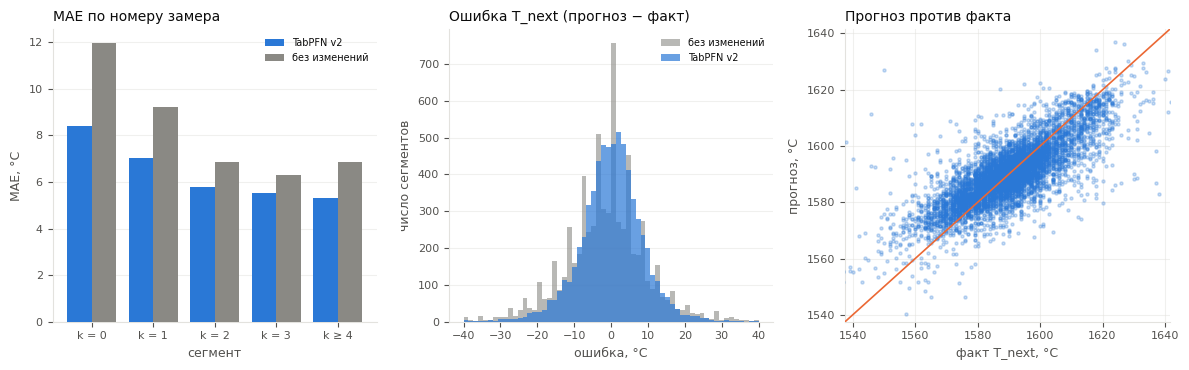

In [45]:
seg['pred'] = seg['T_now'] + seg_oof[SEG_MODEL]                                   # прогноз T_next
seg['err'] = seg['pred'] - seg['T_next']                                          # прогноз − факт
seg['err_base'] = seg['T_now'] - seg['T_next']                                    # «без изменений»
valid_all = np.concatenate([valid_seg for _, valid_seg in fold_rows])
valid_seg = seg.loc[valid_all]

# 1) доли сегментов с ошибкой в допуске (допуск заказчика неизвестен, поэтому три значения)
tolerance = pd.DataFrame({tol: [(valid_seg['err'].abs() <= tol).mean(), (valid_seg['err_base'].abs() <= tol).mean()] for tol in (3, 5, 10)},
                         index=[SEG_MODEL, 'без изменений']).rename(columns=lambda t: f'|ошибка| ≤ {t} °C')
tolerance['MAE'] = [valid_seg['err'].abs().mean(), valid_seg['err_base'].abs().mean()]
tolerance['SD ошибки'] = [valid_seg['err'].std(), valid_seg['err_base'].std()]
display(tolerance.round(3).rename_axis('сегменты, внефолдовые прогнозы'))

# 2) где ошибка больше: номер замера, горизонт прогноза, энергия нагрева
valid_seg = valid_seg.assign(k_group=pd.cut(valid_seg['k'], [-1, 0, 1, 2, 3, 99], labels=['k = 0', 'k = 1', 'k = 2', 'k = 3', 'k ≥ 4']),
             dt_group=pd.qcut(valid_seg['dt'], 4), E_group=pd.qcut(valid_seg['E'], 4, duplicates='drop'))
group_tables = {}
for group in ['k_group', 'dt_group', 'E_group']:
    g = valid_seg.groupby(group, observed=True)
    group_tables[group] = pd.DataFrame({'сегментов': g.size(), 'MAE модели': g['err'].apply(lambda s: s.abs().mean()),
                                'MAE «без изменений»': g['err_base'].apply(lambda s: s.abs().mean()), 'смещение модели': g['err'].mean()})
for name, group_table in group_tables.items():
    group_table.index = group_table.index.astype(str)
display(pd.concat(group_tables, names=['группа', 'интервал']).round(2))

# 3) прогнозные интервалы: квантиль модуля остатков предыдущих фолдов задаёт полуширину интервала следующего
ALPHA = 0.10
coverage = []
seg['covered'] = np.nan
for f in range(1, N_FOLDS):
    calibration = np.abs(seg.loc[np.concatenate([fold_rows[j][1] for j in range(f)]), 'err'].to_numpy())
    q = np.quantile(calibration, min(1.0, np.ceil((len(calibration) + 1) * (1 - ALPHA)) / len(calibration)))
    e = seg.loc[fold_rows[f][1], 'err'].abs()
    seg.loc[fold_rows[f][1], 'covered'] = (e <= q).astype(float).to_numpy()
    coverage.append({'фолд': f + 1, 'полуширина интервала, °C': q, 'покрытие': (e <= q).mean(), 'сегментов': len(e)})
coverage = pd.DataFrame(coverage).set_index('фолд')
display(coverage.round(3).rename_axis(f'интервалы с номинальным покрытием {1 - ALPHA:.0%}'))
print(f'Среднее покрытие по фолдам 2–5: {coverage["покрытие"].mean():.3f} (номинал {1 - ALPHA:.2f}); средняя полуширина {coverage["полуширина интервала, °C"].mean():.1f} °C. '
      'Покрытие наблюдаемое: теоретическая гарантия для этой процедуры не установлена, а сегменты одной партии и соседние партии зависимы.')
covered_rows = seg.loc[seg['covered'].notna()]
display(covered_rows.groupby(pd.cut(covered_rows['k'], [-1, 0, 1, 2, 3, 99], labels=['k = 0', 'k = 1', 'k = 2', 'k = 3', 'k ≥ 4']), observed=True)['covered']
        .agg(['size', 'mean']).rename(columns={'size': 'сегментов', 'mean': 'покрытие'}).round(3).rename_axis('покрытие по номеру сегмента, фолды 2–5'))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), facecolor='white')
ax = axes[0]
group_table = group_tables['k_group']
x = np.arange(len(group_table))
ax.bar(x - 0.2, group_table['MAE модели'], 0.4, color=BAR_COLOR, zorder=3, label=SEG_MODEL.split(' (')[0])
ax.bar(x + 0.2, group_table['MAE «без изменений»'], 0.4, color=NEUTRAL, zorder=3, label='без изменений')
ax.set_xticks(x)
ax.set_xticklabels(group_table.index, fontsize=8)
ax.legend(fontsize=7, frameon=False, labelcolor=INK)
style_axes(ax, 'MAE по номеру замера', 'сегмент', 'MAE, °C')
ax = axes[1]
ax.hist(valid_seg['err_base'], bins=60, range=(-40, 40), color=NEUTRAL, alpha=0.6, zorder=3, label='без изменений')
ax.hist(valid_seg['err'], bins=60, range=(-40, 40), color=BAR_COLOR, alpha=0.7, zorder=4, label=SEG_MODEL.split(' (')[0])
ax.legend(fontsize=7, frameon=False, labelcolor=INK)
style_axes(ax, 'Ошибка T_next (прогноз − факт)', 'ошибка, °C', 'число сегментов')
ax = axes[2]
ax.scatter(valid_seg['T_next'], valid_seg['pred'], s=5, alpha=0.25, color=BAR_COLOR, zorder=3)
lims = [valid_seg['T_next'].quantile(0.002) - 5, valid_seg['T_next'].quantile(0.998) + 5]
ax.plot(lims, lims, color=ACCENT, linewidth=1.2, zorder=4)
ax.set_xlim(lims)
ax.set_ylim(lims)
style_axes(ax, 'Прогноз против факта', 'факт T_next, °C', 'прогноз, °C', grid_axis='both')
save_figure(fig, 'appendix_soft_sensor.png')

**Проверка на test.** Модели обучаются один раз на всех сегментах train и оценивают сегменты партий test теми же метриками; полуширина интервала берётся по внефолдовым остаткам train, на test проверяется только покрытие — в целом и в трёх хронологических блоках.

In [46]:
seg_test = build_segments(list(features.loc[test_keys].index))
describe_segments(seg_test, 'Test')

seg_test_pred = {}
for name in [reference_name, SEG_MODEL]:   # на test — модель датчика и ориентир «без изменений»; Ridge — ориентир только на CV
    model = SEG_MODELS[name]
    if model is None:
        seg_test_pred[name] = np.zeros(len(seg_test))
    else:
        t0 = time.time()
        fitted = fit_segment_model(name, model, seg.index)
        # прогноз частями по 500 сегментов: ограничивает память TabPFN, результат не меняется
        seg_test_pred[name] = np.concatenate([fitted.predict(seg_test[SEG_FEATURES].iloc[i:i + 500])
                                              for i in range(0, len(seg_test), 500)])
        seg_test_time = time.time() - t0
seg_test_err = {name: seg_test['T_now'].to_numpy() + pred - seg_test['T_next'].to_numpy() for name, pred in seg_test_pred.items()}

seg_test_table = pd.DataFrame({name: {'MAE на test': np.abs(e).mean(), 'MAE на CV': seg_summary.loc[name, 'MAE'],
                                      **{f'|ошибка| ≤ {tol} °C': (np.abs(e) <= tol).mean() for tol in (3, 5, 10)},
                                      'SD ошибки': e.std(), 'смещение (прогноз − факт)': e.mean()}
                               for name, e in seg_test_err.items()}).T
display(seg_test_table.round(3).rename_axis('сегменты test'))

seg_test = seg_test.assign(err=seg_test_err[SEG_MODEL], err_base=seg_test_err[reference_name],
                           k_group=pd.cut(seg_test['k'], [-1, 0, 1, 2, 3, 99], labels=['k = 0', 'k = 1', 'k = 2', 'k = 3', 'k ≥ 4']))
by_k = seg_test.groupby('k_group', observed=True)
k_table = pd.DataFrame({'сегментов': by_k.size(), 'MAE модели': by_k['err'].apply(lambda s: s.abs().mean()),
                        'MAE «без изменений»': by_k['err_base'].apply(lambda s: s.abs().mean()), 'смещение модели': by_k['err'].mean()})
k_table['MAE модели на CV'] = group_tables['k_group']['MAE модели'].to_numpy()
display(k_table.round(2).rename_axis('номер сегмента (test)'))

calibration = np.abs(seg.loc[valid_all, 'err'].to_numpy())
q_test = np.quantile(calibration, min(1.0, np.ceil((len(calibration) + 1) * (1 - ALPHA)) / len(calibration)))
covered = seg_test['err'].abs() <= q_test
blocks = np.array_split(np.arange(len(seg_test)), 3)                            # три хронологических блока test
coverage_test = pd.DataFrame({'сегментов': [len(seg_test)] + [len(b) for b in blocks],
                              'покрытие': [covered.mean()] + [covered.iloc[b].mean() for b in blocks]},
                             index=['весь test', 'блок 1 (ранний)', 'блок 2', 'блок 3 (поздний)'])
display(coverage_test.round(3).rename_axis(f'интервал ±{q_test:.1f} °C, номинал {1 - ALPHA:.0%}'))
d_test = seg_test_table.loc[SEG_MODEL, 'MAE на test'] - seg_test_table.loc[reference_name, 'MAE на test']
print(f'{SEG_MODEL} на test: MAE {seg_test_table.loc[SEG_MODEL, "MAE на test"]:.3f} °C (на CV {seg_summary.loc[SEG_MODEL, "MAE"]:.3f}); '
      f'«без изменений» {seg_test_table.loc[reference_name, "MAE на test"]:.3f}, разность {d_test:+.3f} °C. '
      f'Покрытие интервала ±{q_test:.1f} °C: {covered.mean():.3f} (номинал {1 - ALPHA:.2f}). Время обучения и прогноза: {seg_test_time:.0f} с.')

Test: партий 581, сегментов 2732 (на партию: медиана 4, от 1 до 16); сегментов с нагревом: 100.0%, с сыпучими: 65.9%, с проволокой: 31.0%.


,MAE на test,MAE на CV,|ошибка| ≤ 3 °C,|ошибка| ≤ 5 °C,|ошибка| ≤ 10 °C,SD ошибки,смещение (прогноз − факт)
сегменты test,,,,,,,
Без изменений (T_next = T_now),8.857,8.355,0.314,0.454,0.690,12.350,-0.916
TabPFN v2,6.564,6.471,0.333,0.519,0.795,9.103,0.912


,сегментов,MAE модели,MAE «без изменений»,смещение модели,MAE модели на CV
номер сегмента (test),,,,,
k = 0,581,8.42,13.76,1.06,8.42
k = 1,574,6.91,9.21,0.76,7.03
k = 2,543,5.87,7.17,1.17,5.77
k = 3,447,5.44,6.16,0.06,5.52
k ≥ 4,587,5.88,7.28,1.33,5.33


,сегментов,покрытие
"интервал ±13.8 °C, номинал 90%",,
весь test,2732,0.896
блок 1 (ранний),911,0.913
блок 2,911,0.883
блок 3 (поздний),910,0.891


TabPFN v2 на test: MAE 6.564 °C (на CV 6.471); «без изменений» 8.857, разность -2.293 °C. Покрытие интервала ±13.8 °C: 0.896 (номинал 0.90). Время обучения и прогноза: 2178 с.


### Выводы по пошаговой оценке

- **Данные.** 8 183 сегмента в 1 743 партиях train (медиана — 5 сегментов на партию) и 2 732 сегмента в 581 партии test.
- **Модель точнее оценки «без изменений».** На кросс-валидации MAE TabPFN v2 — 6.47 °C против 8.36 °C у оценки «без изменений» (лучше во всех пяти фолдах) и 6.92 °C у `Ridge`. На test MAE 6.56 °C против 8.86 °C у «без изменений», то есть близка к оценке на кросс-валидации.
- **Возможность замены замеров не установлена.** Ошибка не больше 5 °C у 51% оценок (у «без изменений» — 46%), не больше 10 °C — у 80% (71%); в узком допуске ±3 °C датчик почти не лучше «без изменений» (33% против 32%). Выигрыш приходится в основном на крупные ошибки. Часть ошибки в пределах нескольких градусов может приходиться на погрешность самого замера: допуск платинородиевых термопар типов S и B при 1600 °C составляет ±2.5–4 °C в зависимости от класса (IEC 60584-1), а фактическая погрешность погружного замера в ковше и тип датчика в данных не указаны.
- **Ошибка зависит от места в цикле.** Первый сегмент оценивается хуже всего (MAE 8.4 °C), начиная с четвёртого — около 5.3 °C; ошибка растёт с энергией нагрева сегмента.
- **Прогнозные интервалы широкие.** Полуширина 90%-го интервала — около 13.8 °C. Наблюдаемое покрытие в среднем близко к номиналу (89.9% на кросс-валидации, 89.6% на test), но для первого сегмента оно ниже (около 82%), а для поздних — выше (93–94%); теоретическая гарантия покрытия для этой процедуры не установлена.
- **Связь с основной моделью.** В основной задаче получена меньшая MAE (5.63 °C), хотя промежуточные замеры в ней не используются. Это не доказывает превосходства основной модели: целевые величины различаются, а распределения температур неодинаковы — конечные температуры сосредоточены в узком диапазоне (73% партий test лежат в 1580–1600 °C), промежуточные распределены шире. На поздних сегментах пошаговая оценка сопоставима с основной моделью.
- **Итог.** Пошаговую оценку можно использовать как информационную, с интервалом, например в теневом режиме рядом с реальными замерами; пригодность для эксплуатации зависит от требований, которые в данном исследовании не заданы. Для решения о пропуске замеров заказчику нужно задать два требования: допустимую ошибку и допустимую частоту её превышения (например, «ошибка не больше 5 °C хотя бы у 95% оценок»).

## Время выполнения ноутбука

Время отсчитывается от ячейки с версиями библиотек; итоговое значение соответствует полному запуску ноутбука (Restart Kernel and Run All) и зависит от оборудования.

In [47]:
elapsed = time.perf_counter() - NOTEBOOK_START
hours, rest = divmod(int(round(elapsed)), 3600)
print(f'Общее время выполнения ноутбука: {hours} ч {rest // 60} мин {rest % 60} с.')

Общее время выполнения ноутбука: 1 ч 43 мин 41 с.
